# Leave-One-Subject-Out (LOSO) Pipeline - All Models in One

Answers **reviewer comment #1** (subject-independent evaluation), feeds **comment #5** (mean ± std, error analysis) and **comment #3** (component timings, reproducible code).

| Model | Role | How it is trained on each fold |
|---|---|---|
| SSD MobileNetV2 FPNLite 320 | baseline | TF Object Detection API, 20,000 steps |
| **CBAM-SSD** | proposed | CBAM blocks on all 5 FPN levels of that fold's trained SSD (SSD frozen) |
| **SP-FPN-SAM-SSD** | proposed | SLIC superpixel fusion into the FPN of that fold's SSD + SAM objectness re-scoring |
| YOLOv5s 416 | baseline | YOLOv5, 50 epochs |
| **CBAM-YOLOv5s** | proposed | YOLOv5s with CBAM on the 3 feature maps entering the Detect head; trained exactly like YOLOv5s |
| Faster R-CNN ResNet50 640 | baseline | TF Object Detection API, 20,000 steps |

| Step | What it does |
|---|---|
| 1-2 | Pools all subjects, builds one fold per subject, verifies there is no subject overlap |
| 2c | Writes the helper scripts this notebook runs (kept next to the runs for the code repository) |
| 3 (Phase A) | Trains every model on every fold (each in its own process, so GPU memory is freed after each run) |
| 4 (Phase B) | Evaluates every model on its held-out subject with **the same metric code** for all models |
| 5-6 | Mean ± std tables, confusion matrices, model comparison, component timings |
| 6b | Paired bootstrap significance tests (reviewer comment #5) |
| 7 | Diagnostics |
| 8 | Edge deployment: ONNX export, checks, and the bundle for the Jetson benchmark (reviewer comment #4) |

**Kernel:** tfod (or signlang). Every step skips work that is already done, so you can stop and re-run any cell.

## 0. Configuration

In [1]:
import os, sys, re, json, time, glob, shutil, subprocess
from collections import defaultdict
import numpy as np

# ================= CONFIGURE =================
BASE_PATH       = r'd:\RealTimeObjectDetection'

# Every folder that holds images + XMLs for any subject (searched recursively)
SOURCE_DIRS = [
    r'd:\RealTimeObjectDetection\Tensorflow\workspace\images\train',  # subjects 01-03
    r'd:\RealTimeObjectDetection\Tensorflow\workspace\images\test',   # subjects 01-03
    r'd:\RealTimeObjectDetection\collectedimages_new',                # subjects 04+
]
REBUILD_FOLDS   = False          # True = rebuild folds (also clears old training runs)

MODELS_TO_RUN   = ['ssd', 'cbam_ssd', 'sp_fpn_sam_ssd', 'yolov5s', 'cbam_yolov5s', 'faster_rcnn']   # run order; remove one to skip it
NUM_TRAIN_STEPS = 20000          # SSD and Faster R-CNN (keep identical for a fair comparison)
FINETUNE_STEPS  = 20000          # CBAM-SSD and SP-FPN-SAM-SSD (paper: 20,000 steps)
FINETUNE_LR     = 1e-4           # Adam, cosine decay, 200 warm-up steps (paper settings)
YOLO_EPOCHS     = 50             # paper: 50 epochs
YOLO_IMG        = 416            # paper: 416 x 416
BATCH_SIZES     = {'ssd': 4, 'cbam_ssd': 4, 'sp_fpn_sam_ssd': 4, 'yolov5s': 16, 'cbam_yolov5s': 16,
                   'faster_rcnn': 2}   # Faster R-CNN: 2 fits a 6 GB GPU (use 1 if it runs out of memory)

# YOLOv5: the repository and a Python environment with PyTorch + the YOLOv5 requirements
YOLO_REPO       = r'D:\SignYolo\yolov5'
YOLO_PYTHON     = r'C:\Users\Jason\.conda\envs\yolov5\python.exe'   # None = look for an environment called 'yolov5'
# Segment Anything for SP-FPN-SAM-SSD (falls back to an edge-based objectness map if unavailable)
SAM_CHECKPOINT  = os.path.join(BASE_PATH, 'sam_vit_b_01ec64.pth')
SAM_PYTHON      = None           # None = same environment as YOLO (needs: pip install segment-anything)
FOLDS_TO_RUN    = None           # None = all folds, or e.g. ['fold1', 'fold2']
CONF_THRESH     = 0.5
IOU_THRESH      = 0.5
WARMUP_IMAGES   = 5              # first N inferences excluded from timing (graph tracing)
NMS_MODE        = 'per_class'    # 'per_class' (standard) or 'class_agnostic' (one label per hand).
                                 # Evaluation only - no retraining. Results go to separate folders.
# =============================================

MODELS = {
    'ssd':            {'kind': 'tfod', 'pretrained': 'ssd_mobilenet_v2_fpnlite_320x320_coco17_tpu-8',
                       'label': 'SSD MobileNetV2 FPNLite 320'},
    'cbam_ssd':       {'kind': 'cbam', 'label': 'CBAM-SSD (proposed)'},
    'sp_fpn_sam_ssd': {'kind': 'spfpn', 'label': 'SP-FPN-SAM-SSD (proposed)'},
    'yolov5s':        {'kind': 'yolo', 'label': 'YOLOv5s 416'},
    'cbam_yolov5s':   {'kind': 'yolo', 'cbam': True, 'label': 'CBAM-YOLOv5s (proposed)'},
    'faster_rcnn':    {'kind': 'tfod', 'pretrained': 'faster_rcnn_resnet50_v1_640x640_coco17_tpu-8',
                       'label': 'Faster R-CNN ResNet50 V1 640'},
}

def find_python(env_name):
    home = os.path.expanduser('~')
    for root in (os.path.join(home, '.conda'), os.path.join(home, 'miniconda3'), os.path.join(home, 'anaconda3'), os.path.join(home, 'miniforge3'),
                 r'C:\ProgramData\miniforge3', r'C:\ProgramData\miniconda3', r'C:\ProgramData\anaconda3'):
        exe = os.path.join(root, 'envs', env_name, 'python.exe' if os.name == 'nt' else os.path.join('bin', 'python'))
        if os.path.exists(exe):
            return exe
    return None

YOLO_PYTHON = YOLO_PYTHON if (YOLO_PYTHON and os.path.exists(YOLO_PYTHON)) else find_python('yolov5')
SAM_PYTHON = SAM_PYTHON or YOLO_PYTHON

WORKSPACE_PATH        = os.path.join(BASE_PATH, 'Tensorflow', 'workspace')
APIMODEL_PATH         = os.path.join(BASE_PATH, 'Tensorflow', 'models')
PRETRAINED_MODEL_PATH = os.path.join(WORKSPACE_PATH, 'pre-trained-models')
TFRECORD_SCRIPT       = os.path.join(BASE_PATH, 'Tensorflow', 'scripts', 'generate_tfrecord.py')
TRAINING_SCRIPT       = os.path.join(APIMODEL_PATH, 'research', 'object_detection', 'model_main_tf2.py')

ALL_DATA     = os.path.join(BASE_PATH, 'all_data')            # pooled images + XMLs
FOLDS_DIR    = os.path.join(BASE_PATH, 'loso_folds')          # foldK/train, foldK/test
RUNS_ROOT    = os.path.join(BASE_PATH, 'loso_runs')           # tfrecords, configs, checkpoints, logs
RESULTS_ROOT = os.path.join(BASE_PATH, 'runs', 'loso' if NMS_MODE == 'per_class' else 'loso_class_agnostic')
LABEL_MAP    = os.path.join(RUNS_ROOT, 'label_map.pbtxt')
os.makedirs(RUNS_ROOT, exist_ok=True)
os.makedirs(RESULTS_ROOT, exist_ok=True)

def results_dir(model):
    d = os.path.join(RESULTS_ROOT, model)
    os.makedirs(d, exist_ok=True)
    return d

labels = [
    {'name': 'A', 'id': 1}, {'name': 'B', 'id': 2}, {'name': 'C', 'id': 3},
    {'name': 'one', 'id': 4}, {'name': 'two', 'id': 5}, {'name': 'three', 'id': 6},
    {'name': 'Yes', 'id': 7}, {'name': 'No', 'id': 8}, {'name': 'Goodbye', 'id': 9},
]
class_names = [l['name'] for l in labels]
NUM_CLASSES = len(class_names)

print('Models     :', ', '.join(MODELS[m]['label'] for m in MODELS_TO_RUN))
print(f'Steps      : detectors {NUM_TRAIN_STEPS} | fine-tuning {FINETUNE_STEPS} | YOLO {YOLO_EPOCHS} epochs')
print(f'Batch sizes: {BATCH_SIZES}')
print(f'YOLO       : repo {YOLO_REPO} ({"found" if os.path.exists(os.path.join(YOLO_REPO, "train.py")) else "NOT FOUND"}) | python {YOLO_PYTHON or "NOT FOUND"}')
print(f'SAM        : weights {"found" if os.path.exists(SAM_CHECKPOINT) else "NOT FOUND (edge fallback)"} | python {SAM_PYTHON or "NOT FOUND"}')
print(f'Folds      : {FOLDS_DIR}')
print(f'NMS        : {NMS_MODE}')
print(f'Results    : {RESULTS_ROOT}')

Models     : SSD MobileNetV2 FPNLite 320, CBAM-SSD (proposed), SP-FPN-SAM-SSD (proposed), YOLOv5s 416, CBAM-YOLOv5s (proposed), Faster R-CNN ResNet50 V1 640
Steps      : detectors 20000 | fine-tuning 20000 | YOLO 50 epochs
Batch sizes: {'ssd': 4, 'cbam_ssd': 4, 'sp_fpn_sam_ssd': 4, 'yolov5s': 16, 'cbam_yolov5s': 16, 'faster_rcnn': 2}
YOLO       : repo D:\SignYolo\yolov5 (found) | python C:\Users\Jason\.conda\envs\yolov5\python.exe
SAM        : weights found | python C:\Users\Jason\.conda\envs\yolov5\python.exe
Folds      : d:\RealTimeObjectDetection\loso_folds
NMS        : per_class
Results    : d:\RealTimeObjectDetection\runs\loso


In [2]:
# PYTHONPATH so the training/TFRecord subprocesses can import object_detection
research_path = os.path.join(APIMODEL_PATH, 'research')
slim_path     = os.path.join(research_path, 'slim')
os.environ['PYTHONPATH'] = research_path + os.pathsep + slim_path
for p in (research_path, slim_path):
    if p not in sys.path:
        sys.path.insert(0, p)
print('PYTHONPATH set')
print('Python used for subprocesses:', sys.executable)

PYTHONPATH set
Python used for subprocesses: c:\ProgramData\miniforge3\envs\tfod\python.exe


## 1. Pool All Subjects and Build the Folds\n\nCollects every image + XML from `SOURCE_DIRS`, fixes label names typed as `1`/`2`/`3` (or wrong casing), prints a subject × class table, then builds one fold per subject. Skipped if the folds already exist and `REBUILD_FOLDS = False`.

In [3]:
LABEL_FIXES = {'1': 'one', '2': 'two', '3': 'three', 'a': 'A', 'b': 'B', 'c': 'C',
               'yes': 'Yes', 'no': 'No', 'goodbye': 'Goodbye',
               'One': 'one', 'Two': 'two', 'Three': 'three'}
SUBJECT_RE = re.compile(r'(subject_\d+)')
IMG_EXT = ('.jpg', '.jpeg', '.png')

def list_images(folder):
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))

def subjects_in(folder):
    return sorted({SUBJECT_RE.search(f).group(1) for f in list_images(folder) if SUBJECT_RE.search(f)})

def find_pairs():
    pairs, missing_xml = {}, []
    for src in SOURCE_DIRS:
        if not os.path.isdir(src):
            print(f'  ! Source folder not found, skipping: {src}')
            continue
        for root, _, files in os.walk(src):
            for f in files:
                if not f.lower().endswith(IMG_EXT):
                    continue
                xml = os.path.join(root, os.path.splitext(f)[0] + '.xml')
                if not os.path.exists(xml):
                    missing_xml.append(os.path.join(root, f))
                elif f not in pairs:
                    pairs[f] = (os.path.join(root, f), xml)
    return pairs, missing_xml

def fix_xml_labels(xml_path):
    import xml.etree.ElementTree as ET
    tree = ET.parse(xml_path)
    names, fixed, bad = [], 0, []
    for obj in tree.getroot().findall('object'):
        el = obj.find('name')
        name = (el.text or '').strip() if el is not None else ''
        if name in LABEL_FIXES:
            el.text = name = LABEL_FIXES[name]
            fixed += 1
        if name not in class_names:
            bad.append(name)
        names.append(name)
    if fixed:
        tree.write(xml_path)
    return names, fixed, bad

def build_folds():
    print('Finding image/XML pairs...')
    pairs, missing_xml = find_pairs()
    print(f'  Pairs found: {len(pairs)}')
    if missing_xml:
        print(f'  ! {len(missing_xml)} images have no XML (not annotated yet), e.g.:')
        for p_ in missing_xml[:5]:
            print('     ', p_)

    if os.path.exists(ALL_DATA):
        shutil.rmtree(ALL_DATA)
    os.makedirs(ALL_DATA)
    subjects = defaultdict(list)
    counts = defaultdict(lambda: defaultdict(int))
    no_subject, bad_files, n_fixed = [], [], 0
    for fname, (img, xml) in sorted(pairs.items()):
        m = SUBJECT_RE.search(fname)
        if not m:
            no_subject.append(fname); continue
        dst_xml = os.path.join(ALL_DATA, os.path.splitext(fname)[0] + '.xml')
        shutil.copy2(img, os.path.join(ALL_DATA, fname))
        shutil.copy2(xml, dst_xml)
        names, fixed, bad = fix_xml_labels(dst_xml)
        n_fixed += fixed
        if bad or not names:
            bad_files.append((fname, bad or ['<no objects>'])); continue
        subjects[m.group(1)].append(fname)
        for n_ in names:
            counts[m.group(1)][n_] += 1

    if n_fixed:
        print(f'  Auto-fixed {n_fixed} label names (e.g. "1" -> "one")')
    if no_subject:
        print(f'  ! {len(no_subject)} files have no subject_XX in the name (excluded), e.g. {no_subject[:3]}')
    if bad_files:
        print(f'  ! {len(bad_files)} files have invalid labels (excluded):')
        for f_, b_ in bad_files[:10]:
            print(f'      {f_}: {b_}')

    subj_ids = sorted(subjects)
    header = f'  {"Subject":<12}' + ''.join(f'{c:>8}' for c in class_names) + f'{"TOTAL":>8}'
    print('\n' + header + '\n  ' + '-' * (len(header) - 2))
    for s in subj_ids:
        print(f'  {s:<12}' + ''.join(f'{counts[s][c]:>8}' for c in class_names) + f'{len(subjects[s]):>8}')
    print(f'  {"ALL":<12}' + ''.join(f'{sum(counts[s][c] for s in subj_ids):>8}' for c in class_names)
          + f'{sum(len(v) for v in subjects.values()):>8}')
    for s in subj_ids:
        missing = [c for c in class_names if counts[s][c] == 0]
        if missing:
            print(f'  ! {s} has no examples of: {missing}')
    if len(subj_ids) < 2:
        raise RuntimeError('Need at least 2 subjects to build folds')

    if os.path.exists(FOLDS_DIR):
        shutil.rmtree(FOLDS_DIR)
    for k, test_subj in enumerate(subj_ids, 1):
        for s in subj_ids:
            split = 'test' if s == test_subj else 'train'
            dst = os.path.join(FOLDS_DIR, f'fold{k}', split)
            os.makedirs(dst, exist_ok=True)
            for fname in subjects[s]:
                for f_ in (fname, os.path.splitext(fname)[0] + '.xml'):
                    shutil.copy2(os.path.join(ALL_DATA, f_), os.path.join(dst, f_))
    print(f'\nBuilt {len(subj_ids)} folds in {FOLDS_DIR}')

folds_exist = os.path.isdir(FOLDS_DIR) and any(re.fullmatch(r'fold\d+', d) for d in os.listdir(FOLDS_DIR))
if folds_exist and not REBUILD_FOLDS:
    print('Folds already exist - skipping (set REBUILD_FOLDS = True to rebuild).')
else:
    if os.path.isdir(RUNS_ROOT):   # old TFRecords/checkpoints belong to the old folds
        for d in os.listdir(RUNS_ROOT):
            pth = os.path.join(RUNS_ROOT, d)
            if os.path.isdir(pth):
                shutil.rmtree(pth)
    if os.path.isdir(RESULTS_ROOT):
        shutil.rmtree(RESULTS_ROOT); os.makedirs(RESULTS_ROOT)
    build_folds()

Folds already exist - skipping (set REBUILD_FOLDS = True to rebuild).


## 2. Verify the Folds (no subject overlap)\n\nThe saved `loso_protocol.txt` is your evidence for the response letter.

In [4]:
all_folds = sorted([d for d in os.listdir(FOLDS_DIR) if re.fullmatch(r'fold\d+', d)],
                   key=lambda s: int(s[4:]))
folds = all_folds if FOLDS_TO_RUN is None else [f for f in all_folds if f in FOLDS_TO_RUN]

lines = [f'LOSO protocol - {len(all_folds)} folds', '=' * 70]
for fold in all_folds:
    tr_dir, te_dir = os.path.join(FOLDS_DIR, fold, 'train'), os.path.join(FOLDS_DIR, fold, 'test')
    tr_s, te_s = subjects_in(tr_dir), subjects_in(te_dir)
    overlap = set(tr_s) & set(te_s)
    n_tr, n_te = len(list_images(tr_dir)), len(list_images(te_dir))
    n_xml_missing = sum(not os.path.exists(os.path.join(d, os.path.splitext(f)[0] + '.xml'))
                        for d in (tr_dir, te_dir) for f in list_images(d))
    status = 'OK no overlap' if not overlap else f'OVERLAP {sorted(overlap)}'
    lines.append(f'{fold}: test={",".join(te_s)} ({n_te} imgs) | train={",".join(tr_s)} '
                 f'({n_tr} imgs) | {status}' + (f' | {n_xml_missing} MISSING XML' if n_xml_missing else ''))
    if overlap or n_xml_missing:
        raise RuntimeError(f'{fold} is not valid - rerun prepare_loso_folds.py')

print('\n'.join(lines))
with open(os.path.join(RESULTS_ROOT, 'loso_protocol.txt'), 'w', encoding='utf-8') as f:
    f.write('\n'.join(lines) + '\n')
print(f'\nRunning folds: {folds}')

LOSO protocol - 4 folds
fold1: test=subject_01 (407 imgs) | train=subject_02,subject_04,subject_05 (1007 imgs) | OK no overlap
fold2: test=subject_02 (222 imgs) | train=subject_01,subject_04,subject_05 (1192 imgs) | OK no overlap
fold3: test=subject_04 (363 imgs) | train=subject_01,subject_02,subject_05 (1051 imgs) | OK no overlap
fold4: test=subject_05 (422 imgs) | train=subject_01,subject_02,subject_04 (992 imgs) | OK no overlap

Running folds: ['fold1', 'fold2', 'fold3', 'fold4']


In [5]:
# Label map (shared by all folds and models)
with open(LABEL_MAP, 'w', encoding='utf-8') as f:
    for l in labels:
        f.write("item {\n  name: '%s'\n  id: %d\n}\n" % (l['name'], l['id']))
print('Label map:', LABEL_MAP)

Label map: d:\RealTimeObjectDetection\loso_runs\label_map.pbtxt


## 2c. Helper Scripts

Writes the scripts that train and evaluate each model into `loso_runs/scripts`. They are run as separate processes, so every model is trained and timed in a fresh process. Put this folder in the public code repository for reviewer comment #3.

In [6]:
SCRIPT_FILES = {
    'loso_common.py': r'''"""Shared definitions for the LOSO pipeline: classes, ground truth, and the paper's metric code.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, re, json
from collections import defaultdict
import numpy as np

_CFG = os.path.join(os.path.dirname(os.path.abspath(__file__)), 'loso_config.json')
with open(_CFG, encoding='utf-8') as _f:
    CFG = json.load(_f)
class_names = CFG['class_names']
NUM_CLASSES = len(class_names)
CONF_THRESH = CFG['conf_thresh']
IOU_THRESH = CFG['iou_thresh']
IMG_EXT = ('.jpg', '.jpeg', '.png')
SUBJECT_RE = re.compile(r'(subject_\d+)')


def list_images(folder):
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(IMG_EXT))


def subjects_in(folder):
    return sorted({SUBJECT_RE.search(f).group(1) for f in list_images(folder) if SUBJECT_RE.search(f)})


def ground_truths_for(folder):
    """All ground-truth boxes of a folder as dicts {image, class_name, bbox}."""
    gts = []
    for name in list_images(folder):
        for g in get_ground_truth(os.path.join(folder, os.path.splitext(name)[0] + '.xml')):
            gts.append({'image': name, 'class_name': g['name'], 'bbox': g['bbox']})
    return gts


def get_ground_truth(xml_path):
    import xml.etree.ElementTree as ET
    root = ET.parse(xml_path).getroot()
    w, h = int(root.find('size/width').text), int(root.find('size/height').text)
    out = []
    for o in root.findall('object'):
        b = o.find('bndbox')
        out.append({'name': o.find('name').text,
                    'bbox': [int(float(b.find('ymin').text)) / h, int(float(b.find('xmin').text)) / w,
                             int(float(b.find('ymax').text)) / h, int(float(b.find('xmax').text)) / w]})
    return out


def compute_iou(b1, b2):
    y1, x1 = max(b1[0], b2[0]), max(b1[1], b2[1])
    y2, x2 = min(b1[2], b2[2]), min(b1[3], b2[3])
    inter = max(0, y2 - y1) * max(0, x2 - x1)
    union = (b1[2]-b1[0])*(b1[3]-b1[1]) + (b2[2]-b2[0])*(b2[3]-b2[1]) - inter
    return inter / union if union > 0 else 0

def compute_ap(recalls, precisions):
    mrec = np.concatenate(([0.0], recalls, [1.0]))
    mpre = np.concatenate(([1.0], precisions, [0.0]))
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    return sum((max(mpre[mrec >= t]) if np.any(mrec >= t) else 0) for t in np.linspace(0, 1, 101)) / 101

def match_class(dets, gts, cls, iou_thresh=IOU_THRESH):
    # Greedy per-class matching, highest score first. Returns tp/fp flags in score order.
    cls_dets = sorted([d for d in dets if d['class_name'] == cls], key=lambda d: -d['score'])
    gt_by_img = defaultdict(list)
    for g in gts:
        if g['class_name'] == cls:
            gt_by_img[g['image']].append(g)
    matched, flags = set(), []
    for d in cls_dets:
        best, best_key = 0, None
        for j, g in enumerate(gt_by_img.get(d['image'], [])):
            key = (d['image'], j)
            v = compute_iou(d['bbox'], g['bbox'])
            if v > best and key not in matched:
                best, best_key = v, key
        if best >= iou_thresh and best_key is not None:
            matched.add(best_key); flags.append(1)
        else:
            flags.append(0)
    n_gt = sum(len(v) for v in gt_by_img.values())
    return np.array(flags), n_gt

def evaluate_at_threshold(dets, gts, conf_thresh):
    filt = [d for d in dets if d['score'] >= conf_thresh]
    res = {}
    for c in class_names:
        flags, n_gt = match_class(filt, gts, c)
        tp = int(flags.sum()); fp = int(len(flags) - tp); fn = n_gt - tp
        p = tp / (tp + fp) if tp + fp else 0
        r = tp / (tp + fn) if tp + fn else 0
        res[c] = {'tp': tp, 'fp': fp, 'fn': fn, 'precision': p, 'recall': r,
                  'f1': 2*p*r/(p+r) if p + r else 0}
    return res

def ap_per_class(dets, gts):
    out = {}
    for c in class_names:
        flags, n_gt = match_class(dets, gts, c)
        if n_gt == 0:
            out[c] = float('nan'); continue      # class absent from this test subject
        if len(flags) == 0:
            out[c] = 0.0; continue
        tpc, fpc = np.cumsum(flags), np.cumsum(1 - flags)
        out[c] = compute_ap(tpc / n_gt, tpc / (tpc + fpc))
    return out

def confusion_and_errors(dets, gts, conf_thresh=CONF_THRESH, iou_thresh=IOU_THRESH):
    # Class-agnostic matching: rows = ground truth (+background), cols = prediction (+background).
    n = NUM_CLASSES
    idx = {c: i for i, c in enumerate(class_names)}
    cm = np.zeros((n + 1, n + 1), dtype=int)
    errors = []
    filt = [d for d in dets if d['score'] >= conf_thresh]
    gt_by, det_by = defaultdict(list), defaultdict(list)
    for g in gts: gt_by[g['image']].append(g)
    for d in filt: det_by[d['image']].append(d)
    for img in sorted(set(gt_by) | set(det_by)):
        ig = gt_by.get(img, [])
        used = set()
        for d in sorted(det_by.get(img, []), key=lambda x: -x['score']):
            best, bj = 0, -1
            for j, g in enumerate(ig):
                if j in used: continue
                v = compute_iou(d['bbox'], g['bbox'])
                if v > best: best, bj = v, j
            if best >= iou_thresh:
                used.add(bj)
                gname = ig[bj]['class_name']
                cm[idx[gname], idx[d['class_name']]] += 1
                if gname != d['class_name']:
                    errors.append({'image': img, 'type': 'confusion', 'ground_truth': gname,
                                   'predicted': d['class_name'], 'score': round(d['score'], 3)})
            else:
                cm[n, idx[d['class_name']]] += 1
                errors.append({'image': img, 'type': 'false_positive', 'ground_truth': 'background',
                               'predicted': d['class_name'], 'score': round(d['score'], 3)})
        for j, g in enumerate(ig):
            if j not in used:
                cm[idx[g['class_name']], n] += 1
                errors.append({'image': img, 'type': 'missed', 'ground_truth': g['class_name'],
                               'predicted': 'none', 'score': None})
    return cm, errors

def compute_metrics(dets, gts):
    aps = ap_per_class(dets, gts)
    present = [c for c in class_names if not np.isnan(aps[c])]
    r50 = evaluate_at_threshold(dets, gts, CONF_THRESH)
    thresholds = np.round(np.arange(0.0, 1.0001, 0.01), 2)
    f1s = [np.mean([evaluate_at_threshold(dets, gts, t)[c]['f1'] for c in present]) for t in thresholds]
    bi = int(np.argmax(f1s))
    cm, errors = confusion_and_errors(dets, gts)
    return {
        'mAP': float(np.mean([aps[c] for c in present])),
        'precision': float(np.mean([r50[c]['precision'] for c in present])),
        'recall': float(np.mean([r50[c]['recall'] for c in present])),
        'f1': float(np.mean([r50[c]['f1'] for c in present])),
        'best_f1': float(f1s[bi]), 'best_f1_conf': float(thresholds[bi]),
        'total_fp': int(sum(r50[c]['fp'] for c in class_names)),
        'per_class': {c: {**r50[c], 'ap': aps[c]} for c in class_names},
        'confusion_matrix': cm.tolist(),
        'errors': errors,
    }
''',
    'loso_tf.py': r'''"""TensorFlow pieces of the LOSO pipeline: model building, CBAM, superpixel fusion, data loading.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, re, time
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras import layers as KL
from loso_common import *   # noqa: F401,F403


def gpu_memory_growth():
    for g in tf.config.list_physical_devices('GPU'):
        try:
            tf.config.experimental.set_memory_growth(g, True)
        except RuntimeError:
            pass


def latest_ckpt(model_dir):
    ckpts = [f for f in os.listdir(model_dir) if re.fullmatch(r'ckpt-\d+\.index', f)]
    if not ckpts:
        raise FileNotFoundError(f'No checkpoint in {model_dir}')
    return 'ckpt-%d' % max(int(f.split('-')[1].split('.')[0]) for f in ckpts)


def build_detector(model_dir, is_training=False, nms_mode='per_class'):
    """Build a TF Object Detection API model from model_dir/pipeline.config and restore its latest checkpoint."""
    from object_detection.utils import config_util
    from object_detection.builders import model_builder
    configs = config_util.get_configs_from_pipeline_file(os.path.join(model_dir, 'pipeline.config'))
    mc = configs['model']
    arch = mc.WhichOneof('model')
    if nms_mode == 'class_agnostic':
        pp = mc.ssd.post_processing if arch == 'ssd' else mc.faster_rcnn.second_stage_post_processing
        nms = pp.batch_non_max_suppression
        nms.use_class_agnostic_nms = True      # overlapping boxes of different classes suppress each other
        nms.max_classes_per_detection = 1      # one label per box
        nms.use_combined_nms = False
    model = model_builder.build(model_config=mc, is_training=is_training)
    ckpt = latest_ckpt(model_dir)
    tf.train.Checkpoint(model=model).restore(os.path.join(model_dir, ckpt)).expect_partial()
    return model, arch, ckpt


# ---------------------------------------------------------------- CBAM (Woo et al., 2018)
class ChannelAttention(KL.Layer):
    def __init__(self, reduction=16, **kw):
        super().__init__(**kw)
        self.reduction = reduction

    def build(self, shape):
        c = shape[-1]
        r = max(1, c // self.reduction)
        self.fc1 = KL.Dense(r, activation='relu', use_bias=False, name=self.name + '_d1')
        self.fc2 = KL.Dense(c, use_bias=False, name=self.name + '_d2')
        super().build(shape)

    def call(self, x):
        avg = tf.reduce_mean(x, [1, 2], keepdims=True)
        mx = tf.reduce_max(x, [1, 2], keepdims=True)
        return x * tf.sigmoid(self.fc2(self.fc1(avg)) + self.fc2(self.fc1(mx)))


class SpatialAttention(KL.Layer):
    def __init__(self, ks=7, **kw):
        super().__init__(**kw)
        self.ks = ks

    def build(self, shape):
        self.conv = KL.Conv2D(1, self.ks, padding='same', activation='sigmoid',
                              use_bias=False, name=self.name + '_c')
        super().build(shape)

    def call(self, x):
        return x * self.conv(tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                                        tf.reduce_max(x, -1, keepdims=True)], -1))


class CBAM(KL.Layer):
    """Channel attention followed by spatial attention."""
    def __init__(self, reduction=16, ks=7, **kw):
        super().__init__(**kw)
        self.reduction, self.ks = reduction, ks

    def build(self, shape):
        self.cam = ChannelAttention(self.reduction, name=self.name + '_ch')
        self.sam = SpatialAttention(self.ks, name=self.name + '_sp')
        super().build(shape)

    def call(self, x, training=False):
        return self.sam(self.cam(x))


# ---------------------------------------------------------------- Superpixel fusion
class SuperpixelFusion(KL.Layer):
    """F_out = F_fpn + alpha * phi(S): phi is a 1x1 convolution (1 -> C channels), alpha a learnable scalar."""
    def __init__(self, alpha_init=0.05, **kw):
        super().__init__(**kw)
        self.alpha_init = alpha_init

    def build(self, input_shape):
        c = input_shape[0][-1]
        self.phi = KL.Conv2D(c, 1, padding='same', use_bias=False,
                             kernel_initializer='he_normal', name=self.name + '_phi')
        self.alpha = self.add_weight(name='alpha', shape=(1,), trainable=True,
                                     initializer=tf.keras.initializers.Constant(self.alpha_init))
        super().build(input_shape)

    def call(self, inputs):
        fpn, sp = inputs
        return fpn + self.alpha * self.phi(sp)


def _probe_feature_maps(model, size=320):
    prep, _ = model.preprocess(tf.zeros([1, size, size, 3]))
    return model._feature_extractor(prep)


def attach_cbam(model):
    """One CBAM block on every FPN level, between the feature extractor and the detection heads."""
    fmaps = _probe_feature_maps(model)
    blocks = []
    for i, fm in enumerate(fmaps):
        b = CBAM(name=f'cbam_{i}')
        b(fm)
        blocks.append(b)
    orig = model._feature_extractor.call

    def patched(inputs, **kw):
        return [b(fm) for b, fm in zip(blocks, orig(inputs, **kw))]
    model._feature_extractor.call = patched
    return blocks


def attach_sp_fusion(model):
    """One superpixel fusion layer per FPN level. Set model._sp_features to a list of [B,h,w,1] tensors before predict()."""
    fmaps = _probe_feature_maps(model)
    sizes = [(int(fm.shape[1]), int(fm.shape[2])) for fm in fmaps]
    layers = []
    for i, fm in enumerate(fmaps):
        ly = SuperpixelFusion(name=f'sp_fusion_{i}')
        ly([fm, tf.zeros([1, fm.shape[1], fm.shape[2], 1])])
        layers.append(ly)
    model._sp_features = None
    orig = model._feature_extractor.call

    def patched(inputs, **kw):
        fms = orig(inputs, **kw)
        if model._sp_features is None:
            return fms
        return [ly([fm, sp]) for ly, fm, sp in zip(layers, fms, model._sp_features)]
    model._feature_extractor.call = patched
    return layers, sizes


def count_params(layers):
    return int(sum(np.prod(v.shape) for ly in layers for v in ly.trainable_variables))


def save_layer_weights(layers, path):
    arrays = {f'{i}_{j}': w for i, ly in enumerate(layers) for j, w in enumerate(ly.get_weights())}
    np.savez(path, **arrays)


def load_layer_weights(layers, path):
    data = np.load(path)
    for i, ly in enumerate(layers):
        ly.set_weights([data[f'{i}_{j}'] for j in range(len(ly.get_weights()))])


# ---------------------------------------------------------------- Superpixels and objectness
def slic_features(image_rgb, sizes):
    """SLIC superpixel map at each FPN resolution: 0.5 * boundary + 0.5 * mean intensity of each superpixel."""
    from skimage.segmentation import slic, find_boundaries
    img = image_rgb.astype(np.float32) / 255.0
    feats = []
    for (h, w) in sizes:
        small = cv2.resize(img, (w, h), interpolation=cv2.INTER_AREA)
        if small.ndim == 2:
            small = small[..., None]
        seg = slic(small, n_segments=max(10, (h * w) // 50), compactness=10, sigma=1,
                   start_label=0)
        boundary = find_boundaries(seg, mode='thick').astype(np.float32)
        gray = small.mean(axis=-1)
        sums = np.bincount(seg.ravel(), weights=gray.ravel())
        counts = np.maximum(np.bincount(seg.ravel()), 1)
        region = (sums / counts)[seg]
        feats.append(np.clip(0.5 * boundary + 0.5 * region, 0, 1)[..., None].astype(np.float32))
    return feats


def edge_objectness(image_rgb):
    """Fallback objectness map when SAM is unavailable: Canny edges -> filled contours -> distance transform."""
    h, w = image_rgb.shape[:2]
    gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    dil = cv2.dilate(edges, kernel, iterations=2)
    contours, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mask = np.zeros((h, w), np.uint8)
    for c in contours:
        if cv2.contourArea(c) > 500:
            cv2.drawContours(mask, [c], -1, 1, -1)
    dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
    return (dist / (dist.max() + 1e-8)).astype(np.float32)


def load_objectness(objectness_dir, image_name):
    d = np.load(os.path.join(objectness_dir, os.path.splitext(image_name)[0] + '.npz'))
    return d['map'].astype(np.float32), float(d['ms'])


def box_objectness(obj_map, box):
    """Mean objectness inside a normalised [ymin, xmin, ymax, xmax] box."""
    h, w = obj_map.shape
    y1, x1 = max(0, int(box[0] * h)), max(0, int(box[1] * w))
    y2, x2 = min(h, int(np.ceil(box[2] * h))), min(w, int(np.ceil(box[3] * w)))
    if y2 <= y1 or x2 <= x1:
        return 0.0
    return float(obj_map[y1:y2, x1:x2].mean())


def refine_scores(dets, obj_maps, gamma):
    """c_hat = c * (gamma + (1 - gamma) * o): o is the mean objectness inside the box."""
    out = []
    for d in dets:
        o = box_objectness(obj_maps[d['image']], d['bbox'])
        out.append({**d, 'score': d['score'] * (gamma + (1 - gamma) * o)})
    return out


# ---------------------------------------------------------------- Data and inference
def load_rgb(path):
    return cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)


def load_split(split_dir, size=320, max_boxes=8):
    """Images resized to size x size (same as the SSD fixed-shape resizer) with padded boxes and one-hot classes."""
    names = list_images(split_dir)
    imgs = np.zeros((len(names), size, size, 3), np.float32)
    boxes = np.zeros((len(names), max_boxes, 4), np.float32)
    onehot = np.zeros((len(names), max_boxes, NUM_CLASSES), np.float32)
    nbox = np.zeros((len(names),), np.int32)
    for i, n in enumerate(names):
        imgs[i] = cv2.resize(load_rgb(os.path.join(split_dir, n)), (size, size), interpolation=cv2.INTER_AREA)
        gts = [g for g in get_ground_truth(os.path.join(split_dir, os.path.splitext(n)[0] + '.xml'))
               if g['name'] in class_names][:max_boxes]
        nbox[i] = len(gts)
        for j, g in enumerate(gts):
            boxes[i, j] = g['bbox']
            onehot[i, j, class_names.index(g['name'])] = 1.0
    return names, imgs, boxes, onehot, nbox


def make_detect_fn(model, sp_sizes=None):
    """tf.function detector for a [1,H,W,3] float image (and, for superpixel fusion, one [1,h,w,1] map per FPN level)."""
    if sp_sizes is None:
        @tf.function(input_signature=[tf.TensorSpec([1, None, None, 3], tf.float32)])
        def fn(image):
            image, shapes = model.preprocess(image)
            return model.postprocess(model.predict(image, shapes), shapes)
        return lambda img, sp=None: fn(tf.convert_to_tensor(img[None], tf.float32))

    specs = [tf.TensorSpec([1, None, None, 3], tf.float32)] + [tf.TensorSpec([1, h, w, 1], tf.float32) for h, w in sp_sizes]

    @tf.function(input_signature=specs)
    def fn(image, *sp):
        model._sp_features = list(sp)
        image, shapes = model.preprocess(image)
        return model.postprocess(model.predict(image, shapes), shapes)
    return lambda img, sp: fn(tf.convert_to_tensor(img[None], tf.float32), *[tf.convert_to_tensor(s[None]) for s in sp])


def detections_from_output(out, image_name, min_score=0.001):
    n = int(out['num_detections'][0])
    boxes = out['detection_boxes'][0, :n].numpy()
    scores = out['detection_scores'][0, :n].numpy()
    classes = out['detection_classes'][0, :n].numpy().astype(int) + 1
    dets = []
    for b, s, c in zip(boxes, scores, classes):
        if 1 <= c <= NUM_CLASSES and s >= min_score:
            dets.append({'image': image_name, 'class_name': class_names[c - 1],
                         'score': float(s), 'bbox': [float(v) for v in b]})
    return dets
''',
    'train_finetune.py': r'''"""Fine-tune CBAM blocks (cbam) or superpixel fusion layers (spfpn) on top of a trained, frozen SSD.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, time, math, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import tensorflow as tf
from loso_tf import *   # noqa: F401,F403

p = argparse.ArgumentParser()
p.add_argument('--variant', choices=['cbam', 'spfpn'], required=True)
p.add_argument('--train_dir', required=True)
p.add_argument('--ssd_model_dir', required=True)
p.add_argument('--out_dir', required=True)
p.add_argument('--steps', type=int, default=20000)
p.add_argument('--batch', type=int, default=4)
p.add_argument('--lr', type=float, default=1e-4)
p.add_argument('--warmup', type=int, default=200)
p.add_argument('--log_every', type=int, default=500)
p.add_argument('--objectness_dir', default='')
args = p.parse_args()
os.makedirs(args.out_dir, exist_ok=True)
gpu_memory_growth()
tf.random.set_seed(0)
np.random.seed(0)

# Frozen SSD (BatchNorm in inference mode) + new layers
model, arch, ckpt = build_detector(args.ssd_model_dir, is_training=False)
if args.variant == 'cbam':
    layers, sizes = attach_cbam(model), None
else:
    layers, sizes = attach_sp_fusion(model)
train_vars = [v for ly in layers for v in ly.trainable_variables]
n_params = count_params(layers)
print(f'{args.variant}: SSD {ckpt} from {args.ssd_model_dir} | trainable params {n_params:,}', flush=True)

names, imgs, boxes, onehot, nbox = load_split(args.train_dir)
print(f'Training images: {len(names)}', flush=True)
tensors = [imgs, boxes, onehot, nbox]
slic_ms = []
if args.variant == 'spfpn':
    sp_levels = [np.zeros((len(names), h, w, 1), np.float32) for h, w in sizes]
    for i, n in enumerate(names):
        t0 = time.perf_counter()
        feats = slic_features(load_rgb(os.path.join(args.train_dir, n)), sizes)
        slic_ms.append((time.perf_counter() - t0) * 1000)
        for lvl, f in enumerate(feats):
            sp_levels[lvl][i] = f
    print(f'SLIC features computed: {np.mean(slic_ms):.1f} ms/image', flush=True)
    tensors += sp_levels

B = args.batch
ds = (tf.data.Dataset.from_tensor_slices(tuple(tensors))
      .shuffle(len(names), seed=0, reshuffle_each_iteration=True)
      .repeat().batch(B, drop_remainder=True).prefetch(tf.data.AUTOTUNE))


class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, base, warmup, total):
        self.base, self.warmup, self.total = base, warmup, total

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.base * step / max(1, self.warmup)
        prog = tf.clip_by_value((step - self.warmup) / max(1, self.total - self.warmup), 0.0, 1.0)
        cos = self.base * 0.5 * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < self.warmup, warm, cos)


schedule = WarmupCosine(args.lr, args.warmup, args.steps)
opt = tf.keras.optimizers.Adam(schedule)


@tf.function
def train_step(images, gt_boxes, gt_classes, n_boxes, *sp):
    if sp:
        model._sp_features = list(sp)
    blist = [gt_boxes[i, :n_boxes[i]] for i in range(B)]
    clist = [gt_classes[i, :n_boxes[i]] for i in range(B)]
    wlist = [tf.ones([n_boxes[i]], tf.float32) for i in range(B)]
    model.provide_groundtruth(groundtruth_boxes_list=blist, groundtruth_classes_list=clist,
                              groundtruth_weights_list=wlist)
    with tf.GradientTape() as tape:
        prep, shapes = model.preprocess(images)
        losses = model.loss(model.predict(prep, shapes), shapes)
        total = tf.add_n(list(losses.values()))
    grads = tape.gradient(total, train_vars)
    opt.apply_gradients(zip(grads, train_vars))
    return total


hist = {'step': [], 'loss': [], 'lr': []}
it = iter(ds)
t0 = time.time()
for step in range(1, args.steps + 1):
    loss = train_step(*next(it))
    if step == 1 or step % args.log_every == 0 or step == args.steps:
        lv = float(loss.numpy())
        lr = float(schedule(step - 1).numpy())
        hist['step'].append(step); hist['loss'].append(lv); hist['lr'].append(lr)
        extra = ''
        if args.variant == 'spfpn':
            extra = '  alpha=' + ','.join(f'{float(ly.alpha.numpy()[0]):.3f}' for ly in layers)
        print(f'step {step:6d}/{args.steps}  loss={lv:.4f}  lr={lr:.2e}{extra}  ({time.time()-t0:.0f}s)', flush=True)
train_seconds = time.time() - t0
save_layer_weights(layers, os.path.join(args.out_dir, 'layers.npz'))

info = {'variant': args.variant, 'ssd_checkpoint': ckpt, 'params': n_params, 'steps': args.steps,
        'batch': B, 'lr': args.lr, 'warmup': args.warmup, 'seconds': train_seconds,
        'final_loss': hist['loss'][-1], 'history': hist}

# Superpixel model: choose gamma for the objectness refinement on the TRAINING subjects only
if args.variant == 'spfpn':
    info['alpha'] = [float(ly.alpha.numpy()[0]) for ly in layers]
    info['fpn_sizes'] = sizes
    info['slic_ms_train_mean'] = float(np.mean(slic_ms))
    info['objectness_dir'] = args.objectness_dir
    if args.objectness_dir:
        detect = make_detect_fn(model, sizes)
        dets, obj_maps = [], {}
        for i, n in enumerate(names):
            img = load_rgb(os.path.join(args.train_dir, n))
            out = detect(img, [sp_levels[l][i] for l in range(len(sizes))])
            dets += detections_from_output(out, n, min_score=0.01)
            obj_maps[n] = load_objectness(args.objectness_dir, n)[0]
        gts = ground_truths_for(args.train_dir)
        grid = [round(g, 1) for g in np.linspace(0, 1, 11)]
        scores = {}
        for g in grid:
            aps = ap_per_class(refine_scores(dets, obj_maps, g), gts)
            scores[g] = float(np.nanmean(list(aps.values())))
        best = max(grid, key=lambda g: (scores[g], g))   # ties -> larger gamma (less refinement)
        info['gamma'] = best
        info['gamma_search_train_mAP'] = scores
        print('gamma search on training subjects (mAP): ' +
              ', '.join(f'{g}:{scores[g]:.3f}' for g in grid) + f' -> gamma={best}', flush=True)
    else:
        info['gamma'] = 1.0

with open(os.path.join(args.out_dir, 'TRAINING_DONE.json'), 'w', encoding='utf-8') as f:
    json.dump(info, f, indent=1)
print(f'Done in {train_seconds/60:.1f} min', flush=True)
''',
    'eval_tf.py': r'''"""Run a TensorFlow detector over a held-out subject and dump detections + timings to JSON.
kinds: tfod (SSD / Faster R-CNN as trained), cbam (SSD + CBAM), spfpn (SSD + superpixel fusion + objectness refinement).
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, time, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
from loso_tf import *   # noqa: F401,F403

p = argparse.ArgumentParser()
p.add_argument('--kind', choices=['tfod', 'cbam', 'spfpn'], required=True)
p.add_argument('--model_dir', required=True, help='folder with pipeline.config and ckpt-N (the trained SSD for cbam/spfpn)')
p.add_argument('--extra_dir', default='', help='folder with layers.npz and TRAINING_DONE.json (cbam/spfpn)')
p.add_argument('--test_dir', required=True)
p.add_argument('--out_json', required=True)
p.add_argument('--nms', default='per_class', choices=['per_class', 'class_agnostic'])
p.add_argument('--objectness_dir', default='')
args = p.parse_args()
gpu_memory_growth()

model, arch, ckpt = build_detector(args.model_dir, is_training=False, nms_mode=args.nms)
sizes, gamma, info = None, 1.0, {}
if args.kind != 'tfod':
    with open(os.path.join(args.extra_dir, 'TRAINING_DONE.json'), encoding='utf-8') as f:
        info = json.load(f)
if args.kind == 'cbam':
    layers = attach_cbam(model)
    load_layer_weights(layers, os.path.join(args.extra_dir, 'layers.npz'))
elif args.kind == 'spfpn':
    layers, sizes = attach_sp_fusion(model)
    load_layer_weights(layers, os.path.join(args.extra_dir, 'layers.npz'))
    gamma = float(info.get('gamma', 1.0)) if args.objectness_dir else 1.0
detect = make_detect_fn(model, sizes)

names = list_images(args.test_dir)
dets, times = [], []
comp = {'slic_ms': [], 'detector_ms': [], 'objectness_ms': [], 'refine_ms': []}
for n in names:
    img = load_rgb(os.path.join(args.test_dir, n))
    if args.kind == 'spfpn':
        t0 = time.perf_counter()
        sp = slic_features(img, sizes)
        t1 = time.perf_counter()
        out = detect(img, sp)
        d = detections_from_output(out, n)
        t2 = time.perf_counter()
        obj_ms = 0.0
        if args.objectness_dir:
            obj_map, obj_ms = load_objectness(args.objectness_dir, n)   # map precomputed; obj_ms = its measured cost
            t3 = time.perf_counter()
            d = refine_scores(d, {n: obj_map}, gamma)
            t4 = time.perf_counter()
        else:
            t3 = t4 = time.perf_counter()
        comp['slic_ms'].append((t1 - t0) * 1000)
        comp['detector_ms'].append((t2 - t1) * 1000)
        comp['objectness_ms'].append(obj_ms)
        comp['refine_ms'].append((t4 - t3) * 1000)
        times.append(comp['slic_ms'][-1] + comp['detector_ms'][-1] + obj_ms + comp['refine_ms'][-1])
    else:
        t0 = time.perf_counter()
        out = detect(img)
        d = detections_from_output(out, n)
        times.append((time.perf_counter() - t0) * 1000)
    dets += d

result = {'kind': args.kind, 'checkpoint': ckpt, 'nms': args.nms, 'n_images': len(names),
          'detections': dets, 'times_ms': times}
if args.kind == 'spfpn':
    result['components_ms'] = comp
    result['gamma'] = gamma
if info:
    result['params'] = info.get('params')
with open(args.out_json, 'w', encoding='utf-8') as f:
    json.dump(result, f)
print(f'{args.kind}: {len(names)} images, {len(dets)} detections, '
      f'{np.mean(times[5:] if len(times) > 5 else times):.1f} ms/image -> {args.out_json}', flush=True)
''',
    'objectness.py': r'''"""Precompute one objectness map per image (Segment Anything, or an edge-based fallback) and its compute time.
Exit code 3 = SAM not usable (missing package or weights); the notebook then falls back to edge mode.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, time, argparse
import numpy as np
import cv2

p = argparse.ArgumentParser()
p.add_argument('--images_dir', required=True)
p.add_argument('--out_dir', required=True)
p.add_argument('--mode', choices=['sam', 'edge'], required=True)
p.add_argument('--checkpoint', default='')
p.add_argument('--model_type', default='vit_b')
p.add_argument('--scale', type=float, default=0.25, help='stored map size relative to the image')
args = p.parse_args()
os.makedirs(args.out_dir, exist_ok=True)
IMG_EXT = ('.jpg', '.jpeg', '.png')
names = sorted(f for f in os.listdir(args.images_dir) if f.lower().endswith(IMG_EXT))
todo = [n for n in names if not os.path.exists(os.path.join(args.out_dir, os.path.splitext(n)[0] + '.npz'))]
print(f'{args.mode}: {len(names)} images, {len(todo)} to compute', flush=True)

if args.mode == 'sam':
    try:
        import torch
        from segment_anything import sam_model_registry, SamAutomaticMaskGenerator
    except Exception as e:
        print(f'SAM unavailable: {e}. Install with: pip install segment-anything', flush=True)
        sys.exit(3)
    if not os.path.exists(args.checkpoint):
        print(f'SAM weights not found: {args.checkpoint}', flush=True)
        sys.exit(3)
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    sam = sam_model_registry[args.model_type](checkpoint=args.checkpoint).to(device)
    gen = SamAutomaticMaskGenerator(model=sam, points_per_side=16, pred_iou_thresh=0.86,
                                    stability_score_thresh=0.92, min_mask_region_area=100)
    print(f'SAM {args.model_type} on {device}', flush=True)

    def compute(img):
        masks = gen.generate(img)
        obj = np.zeros(img.shape[:2], np.float32)
        for m in sorted(masks, key=lambda x: x['area'], reverse=True):
            seg = m['segmentation']
            obj[seg] = np.maximum(obj[seg], m['predicted_iou'])
        return obj

    def sync():
        if device == 'cuda':
            torch.cuda.synchronize()
else:
    def compute(img):
        h, w = img.shape[:2]
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        edges = cv2.Canny(gray, 50, 150)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
        dil = cv2.dilate(edges, kernel, iterations=2)
        contours, _ = cv2.findContours(dil, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        mask = np.zeros((h, w), np.uint8)
        for c in contours:
            if cv2.contourArea(c) > 500:
                cv2.drawContours(mask, [c], -1, 1, -1)
        dist = cv2.distanceTransform(mask, cv2.DIST_L2, 5)
        return (dist / (dist.max() + 1e-8)).astype(np.float32)

    def sync():
        pass

t_start = time.time()
for i, n in enumerate(todo, 1):
    img = cv2.cvtColor(cv2.imread(os.path.join(args.images_dir, n)), cv2.COLOR_BGR2RGB)
    sync(); t0 = time.perf_counter()
    obj = compute(img)
    sync(); ms = (time.perf_counter() - t0) * 1000
    small = cv2.resize(obj, (max(1, int(img.shape[1] * args.scale)), max(1, int(img.shape[0] * args.scale))),
                       interpolation=cv2.INTER_AREA)
    np.savez_compressed(os.path.join(args.out_dir, os.path.splitext(n)[0] + '.npz'),
                        map=small.astype(np.float16), ms=np.float32(ms))
    if i % 100 == 0 or i == len(todo):
        print(f'  {i}/{len(todo)}  ({(time.time()-t_start)/60:.1f} min)', flush=True)
print('done', flush=True)
''',
    'yolo_eval.py': r'''"""Run a trained YOLOv5 model over a held-out subject and dump detections + timings in the pipeline's JSON format.
Run with the Python environment that has PyTorch and the YOLOv5 requirements.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, time, argparse
import numpy as np
import cv2

p = argparse.ArgumentParser()
p.add_argument('--repo', required=True)
p.add_argument('--weights', required=True)
p.add_argument('--test_dir', required=True)
p.add_argument('--out_json', required=True)
p.add_argument('--img', type=int, default=416)
p.add_argument('--nms', default='per_class', choices=['per_class', 'class_agnostic'])
args = p.parse_args()

import torch
model = torch.hub.load(args.repo, 'custom', path=args.weights, source='local')
model.conf = 0.001          # keep low-score boxes for the precision-recall curve (same as YOLOv5 val.py)
model.iou = 0.45            # YOLOv5 default NMS IoU
model.agnostic = args.nms == 'class_agnostic'
model.max_det = 100         # same cap as the TensorFlow models
names = model.names if isinstance(model.names, (list, tuple)) else [model.names[i] for i in sorted(model.names)]
cuda = torch.cuda.is_available()
print(f'YOLOv5 on {"cuda" if cuda else "cpu"} | classes: {names}', flush=True)

IMG_EXT = ('.jpg', '.jpeg', '.png')
files = sorted(f for f in os.listdir(args.test_dir) if f.lower().endswith(IMG_EXT))
dets, times = [], []
for n in files:
    img = cv2.cvtColor(cv2.imread(os.path.join(args.test_dir, n)), cv2.COLOR_BGR2RGB)
    if cuda:
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    r = model(img, size=args.img)
    if cuda:
        torch.cuda.synchronize()
    times.append((time.perf_counter() - t0) * 1000)
    for x1, y1, x2, y2, conf, cls in r.xyxyn[0].tolist():
        dets.append({'image': n, 'class_name': names[int(cls)], 'score': float(conf),
                     'bbox': [float(y1), float(x1), float(y2), float(x2)]})

with open(args.out_json, 'w', encoding='utf-8') as f:
    json.dump({'kind': 'yolo', 'checkpoint': os.path.basename(args.weights), 'nms': args.nms,
               'n_images': len(files), 'detections': dets, 'times_ms': times}, f)
print(f'yolo: {len(files)} images, {len(dets)} detections, '
      f'{np.mean(times[5:] if len(times) > 5 else times):.1f} ms/image -> {args.out_json}', flush=True)
''',
    'yolo_cbam.py': r'''"""CBAM (Woo et al., 2018) for YOLOv5 - the same block as CBAM-SSD: channel attention (reduction 16, shared MLP on
average- and max-pooled features, no bias) followed by spatial attention (7x7 convolution on channel mean and max).
Kept in its own module so trained checkpoints can be loaded again (they store the class as yolo_cbam.CBAM).
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import torch
import torch.nn as nn


class ChannelAttention(nn.Module):
    def __init__(self, c, reduction=16):
        super().__init__()
        r = max(1, c // reduction)
        self.fc1 = nn.Conv2d(c, r, 1, bias=False)
        self.fc2 = nn.Conv2d(r, c, 1, bias=False)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        avg = self.fc2(self.act(self.fc1(torch.mean(x, (2, 3), keepdim=True))))
        mx = self.fc2(self.act(self.fc1(torch.amax(x, (2, 3), keepdim=True))))
        return x * torch.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self, k=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, k, padding=k // 2, bias=False)

    def forward(self, x):
        s = torch.cat([torch.mean(x, 1, keepdim=True), torch.amax(x, 1, keepdim=True)], 1)
        return x * torch.sigmoid(self.conv(s))


class CBAM(nn.Module):
    """Channel attention followed by spatial attention. Output has the same shape as the input."""
    def __init__(self, c, reduction=16, k=7):
        super().__init__()
        self.cam = ChannelAttention(c, reduction)
        self.sam = SpatialAttention(k)

    def forward(self, x):
        return self.sam(self.cam(x))
''',
    'train_yolo_cbam.py': r'''"""Train CBAM-YOLOv5s: YOLOv5s with a CBAM block on each of the three feature maps that feed the Detect head
(P3, P4, P5) - the same placement as CBAM-SSD (CBAM on every FPN level, before the box/class heads).

The CBAM layers are appended after the original layers, so every original layer keeps its index and the COCO
weights in yolov5s.pt load exactly as for the YOLOv5s baseline. Training is otherwise identical to the baseline
(same train.py, hyperparameters, epochs, batch, image size and seed); CBAM is the only difference.

Usage: python train_yolo_cbam.py --repo <yolov5 repo> --nc 9 --out_cfg x.yaml --info_json x.json <train.py args>
Run with the Python environment that has PyTorch and the YOLOv5 requirements, from inside the YOLOv5 repository.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, copy, json, argparse

HERE = os.path.dirname(os.path.abspath(__file__))
if HERE not in sys.path:
    sys.path.insert(0, HERE)
from yolo_cbam import CBAM   # noqa: E402  (module-level so checkpoints pickle it as yolo_cbam.CBAM)


def build_cbam_yaml(repo, base_cfg, nc, out_cfg):
    import yaml
    import models.yolo as Y
    Y.CBAM = CBAM                                    # lets YOLOv5's parse_model resolve the name 'CBAM'
    with open(os.path.join(repo, base_cfg), encoding='utf-8') as f:
        base = yaml.safe_load(f)
    base['nc'] = nc
    det = base['head'][-1]                           # [[17, 20, 23], 1, Detect, [nc, anchors]]
    assert 'Detect' in str(det[2]), f'unexpected last layer in {base_cfg}: {det}'
    m0 = Y.Model(copy.deepcopy(base), ch=3, nc=nc)   # only to read the channels entering Detect
    chans = [int(c.in_channels) for c in m0.model[-1].m]
    first = len(base['backbone']) + len(base['head']) - 1          # index where Detect used to be
    new = copy.deepcopy(base)
    new['head'] = (base['head'][:-1] +
                   [[f, 1, 'CBAM', [c]] for f, c in zip(det[0], chans)] +
                   [[[first + i for i in range(len(chans))], det[1], det[2], det[3]]])
    with open(out_cfg, 'w', encoding='utf-8') as f:
        yaml.safe_dump(new, f, sort_keys=False, default_flow_style=None)
    m1 = Y.Model(out_cfg, ch=3, nc=nc)
    n_cbam = sum(p.numel() for m in m1.model if isinstance(m, CBAM) for p in m.parameters())
    n_base = sum(p.numel() for p in m0.parameters())
    n_all = sum(p.numel() for p in m1.parameters())
    print(f'CBAM on Detect inputs {det[0]} (channels {chans}): +{n_cbam:,} parameters '
          f'({n_base:,} -> {n_all:,})', flush=True)
    return {'cbam_from': det[0], 'channels': chans, 'params': n_cbam, 'base_params': n_base, 'total_params': n_all}


def main():
    p = argparse.ArgumentParser()
    p.add_argument('--repo', required=True)
    p.add_argument('--nc', type=int, required=True)
    p.add_argument('--out_cfg', required=True)
    p.add_argument('--info_json', required=True)
    p.add_argument('--base_cfg', default=os.path.join('models', 'yolov5s.yaml'))
    args, rest = p.parse_known_args()
    repo = os.path.abspath(args.repo)
    os.chdir(repo)
    if repo not in sys.path:
        sys.path.insert(1, repo)
    for path in (args.out_cfg, args.info_json):
        os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    info = build_cbam_yaml(repo, args.base_cfg, args.nc, args.out_cfg)
    with open(args.info_json, 'w', encoding='utf-8') as f:
        json.dump(info, f, indent=1)
    sys.argv = [os.path.join(repo, 'train.py')] + rest + ['--cfg', os.path.abspath(args.out_cfg)]
    import train
    train.main(train.parse_opt())


if __name__ == '__main__':      # required on Windows: data-loader workers re-import this file
    main()
''',
    'edge_common.py': r'''"""Edge deployment helpers shared by the PC (ONNX Runtime) and the Jetson (TensorRT): pre-processing, post-processing
(box decoding + NMS, identical to the desktop evaluation), runtimes, memory and power readings.
Only needs numpy and OpenCV (plus tensorrt on the Jetson / onnxruntime on the PC).
Kept compatible with Python 3.6 and old numpy so it also runs on the original Jetson Nano (JetPack 4.6).
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, re, sys, glob, json, time, shutil, ctypes, ctypes.util, threading, subprocess
import numpy as np
import cv2


# ================================================================ pre-processing
def tf_legacy_bilinear(img, h, w):
    """Bilinear resize exactly as the TF Object Detection API does it (tf.compat.v1 resize_images:
    align_corners=False, half_pixel_centers=False). OpenCV samples differently, so it is done here in numpy."""
    H, W = img.shape[:2]
    img = img.astype(np.float32)
    ys = np.arange(h, dtype=np.float32) * np.float32(H / float(h))
    xs = np.arange(w, dtype=np.float32) * np.float32(W / float(w))
    y0 = np.floor(ys).astype(np.int64); x0 = np.floor(xs).astype(np.int64)
    y1 = np.minimum(y0 + 1, H - 1); x1 = np.minimum(x0 + 1, W - 1)
    dy = (ys - y0).astype(np.float32)[:, None, None]; dx = (xs - x0).astype(np.float32)[None, :, None]
    r0, r1 = img[y0], img[y1]
    top = r0[:, x0] + (r0[:, x1] - r0[:, x0]) * dx
    bot = r1[:, x0] + (r1[:, x1] - r1[:, x0]) * dx
    return top + (bot - top) * dy


def preprocess_ssd(img_rgb, meta):
    """SSD: resize to the model's fixed size like the TF fixed_shape_resizer; scaling to [-1, 1] is inside the model."""
    h, w = meta['size']
    return tf_legacy_bilinear(img_rgb, h, w)[None], None


def letterbox(img, new_shape, color=(114, 114, 114)):
    """YOLOv5 letterbox (auto=False): keep the aspect ratio, pad to new_shape (h, w). Same rounding as YOLOv5."""
    shape = img.shape[:2]
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
    dw, dh = (new_shape[1] - new_unpad[0]) / 2.0, (new_shape[0] - new_unpad[1]) / 2.0
    if (shape[1], shape[0]) != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))
    img = cv2.copyMakeBorder(img, top, bottom, left, right, cv2.BORDER_CONSTANT, value=color)
    return img, r, (dw, dh)


def preprocess_yolo(img_rgb, meta):
    im, r, pad = letterbox(img_rgb, meta['size'])
    x = np.ascontiguousarray(im.transpose(2, 0, 1)[None], dtype=np.float32) / 255.0
    return x, (img_rgb.shape[:2], r, pad)


def preprocess(img_rgb, meta):
    return (preprocess_ssd if meta['type'] == 'ssd' else preprocess_yolo)(img_rgb, meta)


# ================================================================ NMS
def nms(boxes, scores, iou_thresh, max_keep=None):
    """Greedy NMS, highest score first; a box is suppressed if IoU > iou_thresh (as in TensorFlow and torchvision).
    boxes: [n, 4] as (a1, b1, a2, b2) corners in any consistent order. Returns kept indices in score order."""
    if len(scores) == 0:
        return np.zeros((0,), dtype=np.int64)
    a1, b1, a2, b2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    areas = np.maximum(a2 - a1, 0) * np.maximum(b2 - b1, 0)
    order = np.argsort(-scores, kind='mergesort')
    keep = []
    while order.size > 0:
        i = order[0]
        keep.append(i)
        if max_keep is not None and len(keep) >= max_keep:
            break
        rest = order[1:]
        inter = (np.maximum(np.minimum(a2[i], a2[rest]) - np.maximum(a1[i], a1[rest]), 0) *
                 np.maximum(np.minimum(b2[i], b2[rest]) - np.maximum(b1[i], b1[rest]), 0))
        union = areas[i] + areas[rest] - inter
        iou = np.where(union > 0, inter / np.maximum(union, 1e-12), 0.0)
        order = rest[iou <= iou_thresh]
    return np.array(keep, dtype=np.int64)


# ================================================================ post-processing
def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


def decode_ssd_boxes(enc, anchors, scales):
    """TF Object Detection API faster_rcnn box coder (anchors and boxes as ymin, xmin, ymax, xmax)."""
    ya, xa = (anchors[:, 0] + anchors[:, 2]) / 2, (anchors[:, 1] + anchors[:, 3]) / 2
    ha, wa = anchors[:, 2] - anchors[:, 0], anchors[:, 3] - anchors[:, 1]
    ty, tx, th, tw = enc[:, 0] / scales[0], enc[:, 1] / scales[1], enc[:, 2] / scales[2], enc[:, 3] / scales[3]
    w, h = np.exp(tw) * wa, np.exp(th) * ha
    yc, xc = ty * ha + ya, tx * wa + xa
    return np.stack([yc - h / 2, xc - w / 2, yc + h / 2, xc + w / 2], axis=1)


def postprocess_ssd(outputs, meta, anchors, conf):
    """Same steps as the TF SSD post-processing: decode -> score converter -> per-class NMS -> sort -> clip -> top-k.
    Returns (boxes [ymin, xmin, ymax, xmax] normalised, scores, class indices 0..C-1)."""
    enc, logits = outputs['boxes'].reshape(-1, 4), outputs['classes']
    logits = logits.reshape(enc.shape[0], -1)
    nm = meta['nms']
    scores = logits * meta['logit_scale'] if meta['logit_scale'] != 1.0 else logits
    conv = meta['score_converter']
    if conv == 'SIGMOID':
        scores = _sigmoid(scores)
    elif conv == 'SOFTMAX':
        e = np.exp(scores - scores.max(1, keepdims=True))
        scores = e / e.sum(1, keepdims=True)
    scores = scores[:, 1:]                                         # drop the background column
    thresh = max(nm['score_thresh'], conf)
    cand = np.where((scores > thresh).any(1))[0]
    if cand.size == 0:
        return np.zeros((0, 4), np.float32), np.zeros((0,), np.float32), np.zeros((0,), np.int64)
    boxes = decode_ssd_boxes(enc[cand], anchors[cand], meta['box_scales'])
    scores = scores[cand]
    all_b, all_s, all_c = [], [], []
    for c in range(scores.shape[1]):
        idx = np.where(scores[:, c] > thresh)[0]
        if idx.size == 0:
            continue
        keep = idx[nms(boxes[idx], scores[idx, c], nm['iou_thresh'], nm['max_per_class'])]
        all_b.append(boxes[keep]); all_s.append(scores[keep, c]); all_c.append(np.full(keep.size, c, np.int64))
    if not all_b:
        return np.zeros((0, 4), np.float32), np.zeros((0,), np.float32), np.zeros((0,), np.int64)
    b, s, c = np.concatenate(all_b), np.concatenate(all_s), np.concatenate(all_c)
    order = np.argsort(-s, kind='mergesort')
    b, s, c = np.clip(b[order], 0.0, 1.0), s[order], c[order]
    nonzero = ((b[:, 2] - b[:, 0]) > 0) & ((b[:, 3] - b[:, 1]) > 0)
    b, s, c = b[nonzero], s[nonzero], c[nonzero]
    k = nm['max_total']
    return b[:k], s[:k], c[:k]


def postprocess_yolo(outputs, meta, info, conf):
    """YOLOv5 non_max_suppression (multi_label=False, per-class via class offsets), then boxes back to the original
    image and normalised. Returns (boxes [ymin, xmin, ymax, xmax] normalised, scores, class indices)."""
    (h0, w0), r, (dw, dh) = info
    pred = outputs['output'].reshape(-1, outputs['output'].shape[-1])
    conf_t = max(meta['conf'], conf)
    x = pred[pred[:, 4] > conf_t]
    empty = (np.zeros((0, 4), np.float32), np.zeros((0,), np.float32), np.zeros((0,), np.int64))
    if x.shape[0] == 0:
        return empty
    cls_scores = x[:, 5:] * x[:, 4:5]
    j = cls_scores.argmax(1)
    s = cls_scores[np.arange(len(j)), j]
    m = s > conf_t
    x, s, j = x[m], s[m], j[m]
    if x.shape[0] == 0:
        return empty
    xy, wh = x[:, :2], x[:, 2:4]
    boxes = np.concatenate([xy - wh / 2, xy + wh / 2], 1)          # x1, y1, x2, y2 in the letterboxed image
    order = np.argsort(-s, kind='mergesort')[:meta['max_nms']]
    boxes, s, j = boxes[order], s[order], j[order]
    offset = j[:, None].astype(np.float32) * 7680.0                 # YOLOv5 max_wh: per-class NMS in one pass
    keep = nms(boxes + offset, s, meta['iou'], meta['max_det'])
    boxes, s, j = boxes[keep], s[keep], j[keep]
    boxes[:, [0, 2]] = np.clip((boxes[:, [0, 2]] - dw) / r, 0, w0) / w0
    boxes[:, [1, 3]] = np.clip((boxes[:, [1, 3]] - dh) / r, 0, h0) / h0
    return boxes[:, [1, 0, 3, 2]], s, j


def postprocess(outputs, meta, prep_info, conf=0.0, anchors=None):
    if meta['type'] == 'ssd':
        return postprocess_ssd(outputs, meta, anchors, conf)
    return postprocess_yolo(outputs, meta, prep_info, conf)


def name_outputs(raw, meta):
    """Map runtime output names to 'boxes' / 'classes' (SSD) or 'output' (YOLO)."""
    if meta['type'] != 'ssd':
        return {'output': list(raw.values())[0] if len(raw) == 1 else raw[meta.get('output_name', 'output0')]}
    out = {}
    for name, arr in raw.items():
        n = name.lower()
        if 'box' in n:
            out['boxes'] = arr
        elif 'class' in n:
            out['classes'] = arr
    if len(out) != 2:   # fall back to shapes: boxes end in 4
        for name, arr in raw.items():
            out['boxes' if arr.shape[-1] == 4 else 'classes'] = arr
    return out


# ================================================================ runtimes
class OnnxRuntimeModel(object):
    """PC check: ONNX Runtime on the CPU."""
    def __init__(self, onnx_path, threads=0):
        import onnxruntime as ort
        so = ort.SessionOptions()
        if threads:
            so.intra_op_num_threads = threads
        self.sess = ort.InferenceSession(onnx_path, so, providers=['CPUExecutionProvider'])
        self.input_name = self.sess.get_inputs()[0].name
        self.output_names = [o.name for o in self.sess.get_outputs()]
        self.device_memory_bytes = None

    def infer(self, x):
        res = self.sess.run(self.output_names, {self.input_name: x})
        return dict(zip(self.output_names, res))


class _CudaRT(object):
    """Minimal CUDA runtime through ctypes (libcudart ships with JetPack), so no pycuda install is needed."""
    H2D, D2H = 1, 2

    def __init__(self):
        cands = []
        found = ctypes.util.find_library('cudart')
        if found:
            cands.append(found)
        for pat in ('/usr/local/cuda/lib64/libcudart.so*', '/usr/local/cuda-*/lib64/libcudart.so*',
                    '/usr/local/cuda*/targets/aarch64-linux/lib/libcudart.so*',
                    '/usr/lib/aarch64-linux-gnu/libcudart.so*', '/usr/lib/x86_64-linux-gnu/libcudart.so*'):
            cands += sorted(glob.glob(pat))
        self.lib = None
        for c in cands:
            try:
                self.lib = ctypes.CDLL(c)
                break
            except OSError:
                continue
        if self.lib is None:
            raise RuntimeError('libcudart not found (looked in /usr/local/cuda/lib64). Is JetPack installed?')
        L = self.lib
        L.cudaMalloc.argtypes = [ctypes.POINTER(ctypes.c_void_p), ctypes.c_size_t]
        L.cudaFree.argtypes = [ctypes.c_void_p]
        L.cudaMemcpyAsync.argtypes = [ctypes.c_void_p, ctypes.c_void_p, ctypes.c_size_t, ctypes.c_int, ctypes.c_void_p]
        L.cudaStreamCreate.argtypes = [ctypes.POINTER(ctypes.c_void_p)]
        L.cudaStreamSynchronize.argtypes = [ctypes.c_void_p]
        L.cudaStreamDestroy.argtypes = [ctypes.c_void_p]

    def check(self, err, what):
        if err != 0:
            raise RuntimeError('CUDA error %d in %s' % (err, what))

    def malloc(self, nbytes):
        p = ctypes.c_void_p()
        self.check(self.lib.cudaMalloc(ctypes.byref(p), ctypes.c_size_t(nbytes)), 'cudaMalloc')
        return p

    def stream(self):
        s = ctypes.c_void_p()
        self.check(self.lib.cudaStreamCreate(ctypes.byref(s)), 'cudaStreamCreate')
        return s


class TensorRTModel(object):
    """Jetson: a serialized TensorRT engine. Works with TensorRT 8.2 (JetPack 4.6) up to TensorRT 10 (JetPack 6)."""
    def __init__(self, engine_path):
        import tensorrt as trt
        self.trt = trt
        self.cu = _CudaRT()
        self.logger = trt.Logger(trt.Logger.WARNING)
        self.runtime = trt.Runtime(self.logger)
        with open(engine_path, 'rb') as f:
            self.engine = self.runtime.deserialize_cuda_engine(f.read())
        if self.engine is None:
            raise RuntimeError('Could not load the TensorRT engine %s (built with another TensorRT version?)' % engine_path)
        self.context = self.engine.create_execution_context()
        self.stream = self.cu.stream()
        self.new_api = hasattr(self.engine, 'num_io_tensors')
        self.tensors = []
        if self.new_api:
            for i in range(self.engine.num_io_tensors):
                name = self.engine.get_tensor_name(i)
                is_in = self.engine.get_tensor_mode(name) == trt.TensorIOMode.INPUT
                self._add(name, tuple(self.engine.get_tensor_shape(name)), self.engine.get_tensor_dtype(name), is_in)
            for t in self.tensors:
                self.context.set_tensor_address(t['name'], t['dev'].value)
        else:
            for i in range(self.engine.num_bindings):
                self._add(self.engine.get_binding_name(i), tuple(self.engine.get_binding_shape(i)),
                          self.engine.get_binding_dtype(i), self.engine.binding_is_input(i))
            self.bindings = [t['dev'].value for t in self.tensors]
        self.inputs = [t for t in self.tensors if t['is_input']]
        self.outputs = [t for t in self.tensors if not t['is_input']]
        size = None
        for attr in ('device_memory_size_v2', 'device_memory_size'):
            if hasattr(self.engine, attr):
                try:
                    size = int(getattr(self.engine, attr))
                    break
                except Exception:
                    pass
        self.device_memory_bytes = size

    def _add(self, name, shape, dtype, is_input):
        np_dtype = np.dtype(self.trt.nptype(dtype))
        host = np.zeros(shape, dtype=np_dtype)
        dev = self.cu.malloc(host.nbytes)
        self.tensors.append({'name': name, 'shape': shape, 'host': host, 'dev': dev, 'is_input': is_input})

    def infer(self, x):
        L, cu = self.cu.lib, self.cu
        inp = self.inputs[0]
        x = np.ascontiguousarray(x, dtype=inp['host'].dtype).reshape(inp['shape'])
        cu.check(L.cudaMemcpyAsync(inp['dev'], x.ctypes.data_as(ctypes.c_void_p), x.nbytes, cu.H2D, self.stream), 'H2D')
        if self.new_api:
            ok = self.context.execute_async_v3(stream_handle=self.stream.value)
        else:
            ok = self.context.execute_async_v2(bindings=self.bindings, stream_handle=self.stream.value)
        if not ok:
            raise RuntimeError('TensorRT execution failed')
        for o in self.outputs:
            cu.check(L.cudaMemcpyAsync(o['host'].ctypes.data_as(ctypes.c_void_p), o['dev'], o['host'].nbytes,
                                       cu.D2H, self.stream), 'D2H')
        cu.check(L.cudaStreamSynchronize(self.stream), 'sync')
        return dict((o['name'], o['host'].copy()) for o in self.outputs)

    def close(self):
        for t in self.tensors:
            self.cu.lib.cudaFree(t['dev'])
        self.tensors = []


def find_trtexec():
    for p in (shutil.which('trtexec'), '/usr/src/tensorrt/bin/trtexec', '/usr/local/TensorRT/bin/trtexec'):
        if p and os.path.exists(p):
            return p
    return None


def build_engine(onnx_path, engine_path, precision='fp16', log_path=None):
    """Build a TensorRT engine with trtexec (ships with JetPack). Returns trtexec's own GPU timing if reported."""
    import tensorrt as trt
    exe = find_trtexec()
    if exe is None:
        raise RuntimeError('trtexec not found (expected /usr/src/tensorrt/bin/trtexec)')
    major = int(trt.__version__.split('.')[0]); minor = int(trt.__version__.split('.')[1])
    cmd = [exe, '--onnx=' + onnx_path, '--saveEngine=' + engine_path]
    if precision == 'fp16':
        cmd.append('--fp16')
    if (major, minor) < (8, 4):
        cmd.append('--workspace=1024')
    else:
        cmd.append('--memPoolSize=workspace:1024' + ('M' if major >= 10 else ''))
    p = subprocess.run(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, universal_newlines=True)
    if log_path:
        with open(log_path, 'w') as f:
            f.write(' '.join(cmd) + '\n\n' + p.stdout)
    if p.returncode != 0 or not os.path.exists(engine_path):
        raise RuntimeError('trtexec failed for %s:\n%s' % (onnx_path, p.stdout[-2000:]))
    return parse_trtexec_gpu_ms(p.stdout)


def parse_trtexec_gpu_ms(text):
    m = re.search(r'GPU Compute Time: min = ([\d.]+) ms, max = ([\d.]+) ms, mean = ([\d.]+) ms, median = ([\d.]+) ms', text)
    if not m:
        m2 = re.search(r'GPU Compute.*?mean[: =]+([\d.]+) ms', text)
        return {'mean': float(m2.group(1))} if m2 else None
    return {'min': float(m.group(1)), 'max': float(m.group(2)), 'mean': float(m.group(3)), 'median': float(m.group(4))}


# ================================================================ memory and power
def meminfo_mb():
    """System memory in use (MB). On Jetson the GPU shares this RAM, so it includes GPU memory."""
    if not os.path.exists('/proc/meminfo'):
        return None                       # not Linux (e.g. the Windows PC check)
    vals = {}
    with open('/proc/meminfo') as f:
        for line in f:
            k, v = line.split(':', 1)
            vals[k] = int(v.strip().split()[0])
    avail = vals.get('MemAvailable', vals.get('MemFree', 0))
    return (vals['MemTotal'] - avail) / 1024.0


def process_rss_mb():
    cur = peak = None
    if not os.path.exists('/proc/self/status'):
        return cur, peak
    with open('/proc/self/status') as f:
        for line in f:
            if line.startswith('VmRSS:'):
                cur = int(line.split()[1]) / 1024.0
            elif line.startswith('VmHWM:'):
                peak = int(line.split()[1]) / 1024.0
    return cur, peak


class Tegrastats(object):
    """Board power (total input rail), RAM and GPU load from tegrastats, sampled in the background."""
    POWER_RE = re.compile(r'\b(POM_5V_IN|VDD_IN|VIN_SYS_5V0)\s+(\d+)(?:mW)?/(\d+)')
    GPU_POWER_RE = re.compile(r'\b(POM_5V_GPU|VDD_GPU_SOC|VDD_CPU_GPU_CV|VDD_GPU)\s+(\d+)(?:mW)?/(\d+)')
    RAM_RE = re.compile(r'RAM (\d+)/(\d+)MB')
    GPU_RE = re.compile(r'GR3D_FREQ (\d+)%')

    def __init__(self, interval_ms=100):
        self.exe = shutil.which('tegrastats') or ('/usr/bin/tegrastats' if os.path.exists('/usr/bin/tegrastats') else None)
        self.interval_ms = interval_ms
        self.samples, self.proc, self.thread = [], None, None

    @property
    def available(self):
        return self.exe is not None

    def start(self):
        if not self.available:
            return
        self.samples = []
        self.proc = subprocess.Popen([self.exe, '--interval', str(self.interval_ms)], stdout=subprocess.PIPE,
                                     stderr=subprocess.STDOUT, universal_newlines=True, bufsize=1)
        self.thread = threading.Thread(target=self._read)
        self.thread.daemon = True
        self.thread.start()

    def _read(self):
        for line in self.proc.stdout:
            s = {'t': time.time()}
            m = self.POWER_RE.search(line)
            if m:
                s['power_mw'] = float(m.group(2))
            m = self.GPU_POWER_RE.search(line)
            if m:
                s['gpu_rail_mw'] = float(m.group(2))
            m = self.RAM_RE.search(line)
            if m:
                s['ram_mb'] = float(m.group(1))
            m = self.GPU_RE.search(line)
            if m:
                s['gpu_load'] = float(m.group(1))
            self.samples.append(s)

    def stop(self):
        if self.proc is not None:
            self.proc.terminate()
            try:
                self.proc.wait(timeout=3)
            except Exception:
                self.proc.kill()
            self.proc = None
        return list(self.samples)

    @staticmethod
    def summarize(samples, t0=None, t1=None):
        sel = [s for s in samples if (t0 is None or s['t'] >= t0) and (t1 is None or s['t'] <= t1)]

        def mean_of(key):
            v = [s[key] for s in sel if key in s]
            return float(np.mean(v)) if v else None

        def max_of(key):
            v = [s[key] for s in sel if key in s]
            return float(np.max(v)) if v else None
        pw, gw = mean_of('power_mw'), mean_of('gpu_rail_mw')
        return {'n_samples': len(sel), 'power_w': pw / 1000.0 if pw is not None else None,
                'gpu_rail_w': gw / 1000.0 if gw is not None else None,
                'ram_mb_peak': max_of('ram_mb'), 'gpu_load_pct': mean_of('gpu_load')}


def device_info():
    info = {'python': sys.version.split()[0], 'numpy': np.__version__, 'opencv': cv2.__version__}
    for path, key in (('/proc/device-tree/model', 'device'), ('/etc/nv_tegra_release', 'l4t')):
        try:
            with open(path) as f:
                info[key] = f.read().replace('\x00', '').strip().split('\n')[0]
        except Exception:
            pass
    try:
        import tensorrt as trt
        info['tensorrt'] = trt.__version__
    except Exception:
        pass
    try:
        p = subprocess.run(['nvpmodel', '-q'], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, universal_newlines=True)
        info['power_mode'] = ' | '.join(l.strip() for l in p.stdout.splitlines() if l.strip())
    except Exception:
        pass
    return info
''',
    'edge_export_tf.py': r'''"""Export a trained SSD or CBAM-SSD (TF Object Detection API) for edge deployment.

Writes into --out_dir:
  frozen.pb    the network as a frozen TensorFlow graph: input = resized RGB image [1,H,W,3] (0-255 floats),
               outputs = raw box encodings and class logits (decoding + NMS are done by edge_common.py, exactly like
               the TF post-processing, so the same code runs on the PC and on the Jetson)
  anchors.npy  the SSD anchors (normalised ymin, xmin, ymax, xmax)
  meta.json    input size, box coder, score converter and NMS settings read from pipeline.config
  ref.npz      TensorFlow outputs and TensorFlow detections on a few test images, used to check the ONNX model
Runs in the TensorFlow (tfod) environment; needs nothing beyond what training used.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
from loso_tf import *   # noqa: F401,F403

p = argparse.ArgumentParser()
p.add_argument('--kind', choices=['tfod', 'cbam'], required=True)
p.add_argument('--model_dir', required=True, help='trained SSD folder (pipeline.config + ckpt-N)')
p.add_argument('--extra_dir', default='', help='CBAM folder with layers.npz')
p.add_argument('--test_dir', required=True)
p.add_argument('--out_dir', required=True)
p.add_argument('--n_ref', type=int, default=5)
args = p.parse_args()
os.makedirs(args.out_dir, exist_ok=True)
gpu_memory_growth()

from edge_common import preprocess_ssd
from object_detection.utils import config_util
from object_detection.protos import post_processing_pb2
from tensorflow.python.framework.convert_to_constants import convert_variables_to_constants_v2

mc = config_util.get_configs_from_pipeline_file(os.path.join(args.model_dir, 'pipeline.config'))['model']
if mc.WhichOneof('model') != 'ssd':
    sys.exit('Only SSD models can be exported for the edge benchmark.')
ssd = mc.ssd
H, W = ssd.image_resizer.fixed_shape_resizer.height, ssd.image_resizer.fixed_shape_resizer.width
bc = ssd.box_coder.faster_rcnn_box_coder
nms_cfg = ssd.post_processing.batch_non_max_suppression
meta = {
    'type': 'ssd', 'kind': args.kind, 'size': [H, W], 'layout': 'NHWC', 'input_range': '0-255 RGB',
    'box_scales': [bc.y_scale, bc.x_scale, bc.height_scale, bc.width_scale],
    'score_converter': post_processing_pb2.PostProcessing.ScoreConverter.Name(ssd.post_processing.score_converter),
    'logit_scale': float(ssd.post_processing.logit_scale or 1.0),
    'nms': {'score_thresh': float(nms_cfg.score_threshold), 'iou_thresh': float(nms_cfg.iou_threshold),
            'max_per_class': int(nms_cfg.max_detections_per_class), 'max_total': int(nms_cfg.max_total_detections)},
    'class_names': class_names,
}
assert ssd.box_coder.WhichOneof('box_coder_oneof') == 'faster_rcnn_box_coder', 'unexpected box coder'

model, arch, ckpt = build_detector(args.model_dir, is_training=False)
if args.kind == 'cbam':
    blocks = attach_cbam(model)
    load_layer_weights(blocks, os.path.join(args.extra_dir, 'layers.npz'))
meta['checkpoint'] = ckpt


@tf.function(input_signature=[tf.TensorSpec([1, H, W, 3], tf.float32, name='image')])
def raw_net(image):
    x = model._feature_extractor.preprocess(image)               # MobileNet scaling to [-1, 1]
    pred = model.predict(x, tf.constant([[H, W, 3]], tf.int32))
    return (tf.identity(pred['box_encodings'], name='box_encodings'),
            tf.identity(pred['class_predictions_with_background'], name='class_logits'))


_x = model._feature_extractor.preprocess(tf.zeros([1, H, W, 3]))   # one eager pass sets the anchors
model.predict(_x, tf.constant([[H, W, 3]], tf.int32))
anchors = model._anchors.get().numpy().astype(np.float32)
concrete = raw_net.get_concrete_function()
np.save(os.path.join(args.out_dir, 'anchors.npy'), anchors)
frozen = convert_variables_to_constants_v2(concrete)
tf.io.write_graph(frozen.graph.as_graph_def(), args.out_dir, 'frozen.pb', as_text=False)
meta['graph_inputs'] = [t.name for t in frozen.inputs]
meta['graph_outputs'] = [t.name for t in frozen.outputs]          # order: box encodings, class logits
meta['num_anchors'] = int(anchors.shape[0])
meta['num_classes'] = NUM_CLASSES

# Reference outputs on a few held-out images: raw network + full TensorFlow post-processing
detect = make_detect_fn(model)
names = list_images(args.test_dir)[:args.n_ref]
ref = {'names': np.array(names)}
for i, n in enumerate(names):
    img = load_rgb(os.path.join(args.test_dir, n))
    x = preprocess_ssd(img, meta)[0]                               # exactly what the edge runtime will feed
    if i == 0:   # the edge resize must reproduce the model's own TF pre-processing
        tf_prep, _ = model.preprocess(tf.constant(img[None], tf.float32))
        edge_prep = model._feature_extractor.preprocess(tf.constant(x))
        meta['resize_check_max_diff'] = float(np.abs(tf_prep.numpy() - edge_prep.numpy()).max())
    b, c = raw_net(tf.constant(x))
    out = detect(x[0])
    k = int(out['num_detections'][0])
    ref['input_%d' % i] = x
    ref['boxes_%d' % i], ref['classes_%d' % i] = b.numpy(), c.numpy()
    ref['det_boxes_%d' % i] = out['detection_boxes'][0, :k].numpy()
    ref['det_scores_%d' % i] = out['detection_scores'][0, :k].numpy()
    ref['det_classes_%d' % i] = out['detection_classes'][0, :k].numpy().astype(int)
np.savez_compressed(os.path.join(args.out_dir, 'ref.npz'), **ref)
with open(os.path.join(args.out_dir, 'meta.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=1)
print('Exported %s (%s): %d anchors, input %dx%d | resize matches TF pre-processing: max diff %.1e%s' % (
    args.kind, ckpt, anchors.shape[0], W, H, meta['resize_check_max_diff'],
    '' if meta['resize_check_max_diff'] < 1e-3 else '  !!! MISMATCH'), flush=True)
''',
    'edge_export_yolo.py': r'''"""Export a trained YOLOv5s or CBAM-YOLOv5s (last.pt) to ONNX for edge deployment.

The input size is the one the desktop evaluation used: YOLOv5's AutoShape letterboxes a 640x480 frame to 416x320
(longest side 416, rounded up to a multiple of 32), so the ONNX model takes [1,3,320,416] for 640x480 images.
Writes model.onnx, meta.json and ref.npz (PyTorch outputs and the desktop pipeline's detections on a few test images).
Runs in the YOLOv5 (PyTorch) environment; needs: pip install onnx
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, math, inspect, argparse
HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import numpy as np
import cv2
import yolo_cbam  # noqa: F401  (CBAM-YOLOv5s checkpoints refer to yolo_cbam.CBAM)
from edge_common import preprocess_yolo

p = argparse.ArgumentParser()
p.add_argument('--repo', required=True)
p.add_argument('--weights', required=True)
p.add_argument('--test_dir', required=True)
p.add_argument('--out_dir', required=True)
p.add_argument('--img', type=int, default=416)
p.add_argument('--opset', type=int, default=13)
p.add_argument('--n_ref', type=int, default=5)
args = p.parse_args()
os.makedirs(args.out_dir, exist_ok=True)
repo = os.path.abspath(args.repo)
sys.path.insert(1, repo)
import torch
import onnx
from models.experimental import attempt_load
from models.yolo import Detect

IMG_EXT = ('.jpg', '.jpeg', '.png')
names_ = sorted(f for f in os.listdir(args.test_dir) if f.lower().endswith(IMG_EXT))[:args.n_ref]
h0, w0 = cv2.imread(os.path.join(args.test_dir, names_[0])).shape[:2]
g = args.img / max(h0, w0)
H, W = [int(math.ceil(v * g / 32) * 32) for v in (h0, w0)]          # AutoShape's input shape for this frame size

try:
    model = attempt_load(args.weights, device=torch.device('cpu'), inplace=True, fuse=True)
except TypeError:                                                   # older YOLOv5 versions
    model = attempt_load(args.weights, map_location='cpu', inplace=True, fuse=True)
model.eval()
for m in model.modules():
    if isinstance(m, Detect):
        m.inplace, m.export = False, True
        if hasattr(m, 'dynamic'):
            m.dynamic = False
class_names = model.names if isinstance(model.names, (list, tuple)) else [model.names[i] for i in sorted(model.names)]
im = torch.zeros(1, 3, H, W)
with torch.no_grad():
    for _ in range(2):
        model(im)
onnx_path = os.path.join(args.out_dir, 'model.onnx')
kw = dict(opset_version=args.opset, do_constant_folding=True, input_names=['images'], output_names=['output0'])
if 'dynamo' in inspect.signature(torch.onnx.export).parameters:
    kw['dynamo'] = False                                           # classic exporter (TensorRT-friendly)
torch.onnx.export(model, im, onnx_path, **kw)
onnx.checker.check_model(onnx.load(onnx_path))
n_params = sum(p_.numel() for p_ in model.parameters())

meta = {'type': 'yolov5', 'size': [H, W], 'layout': 'NCHW', 'input_range': '0-1 RGB, letterboxed (pad 114)',
        'conf': 0.001, 'iou': 0.45, 'max_det': 100, 'max_nms': 30000, 'class_names': class_names,
        'output_name': 'output0', 'weights': os.path.basename(args.weights), 'params': n_params,
        'cbam': any(type(m).__name__ == 'CBAM' for m in model.modules())}

# Reference: raw PyTorch outputs on the same letterboxed input + detections of the desktop pipeline (AutoShape)
try:     # on the CPU, like the ONNX Runtime check
    hub = torch.hub.load(repo, 'custom', path=args.weights, source='local', verbose=False, device='cpu')
except TypeError:
    hub = torch.hub.load(repo, 'custom', path=args.weights, source='local', verbose=False).cpu()
hub.conf, hub.iou, hub.agnostic, hub.max_det = 0.001, 0.45, False, 100
ref = {'names': np.array(names_)}
for i, n in enumerate(names_):
    img = cv2.cvtColor(cv2.imread(os.path.join(args.test_dir, n)), cv2.COLOR_BGR2RGB)
    x, (shape0, r, pad) = preprocess_yolo(img, meta)
    with torch.no_grad():
        y = model(torch.from_numpy(x))
    y = y[0] if isinstance(y, (list, tuple)) else y
    ref['input_%d' % i], ref['output_%d' % i] = x, y.numpy()
    ref['orig_shape_%d' % i], ref['ratio_%d' % i], ref['pad_%d' % i] = np.array(shape0), np.array(r), np.array(pad)
    det = hub(img, size=args.img).xyxyn[0].detach().cpu().numpy()
    ref['det_boxes_%d' % i] = det[:, [1, 0, 3, 2]] if len(det) else np.zeros((0, 4), np.float32)
    ref['det_scores_%d' % i] = det[:, 4] if len(det) else np.zeros((0,), np.float32)
    ref['det_classes_%d' % i] = det[:, 5].astype(int) if len(det) else np.zeros((0,), int)
np.savez_compressed(os.path.join(args.out_dir, 'ref.npz'), **ref)
with open(os.path.join(args.out_dir, 'meta.json'), 'w', encoding='utf-8') as f:
    json.dump(meta, f, indent=1)
print('Exported %s: input %dx%d, %s parameters%s -> %s (%.1f MB)' % (
    os.path.basename(args.weights), W, H, format(n_params, ','), ', CBAM' if meta['cbam'] else '',
    onnx_path, os.path.getsize(onnx_path) / 1e6), flush=True)
''',
    'edge_to_onnx.py': r'''"""Convert an exported SSD (frozen.pb) to ONNX, then check any exported model (SSD or YOLOv5) against the reference
outputs of the original framework: raw network outputs, and final detections after the shared post-processing.
Runs in the 'edge' environment (tensorflow-cpu, tf2onnx, onnx, onnxruntime, opencv).
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
from edge_common import OnnxRuntimeModel, postprocess, name_outputs

p = argparse.ArgumentParser()
p.add_argument('--dir', required=True, help='export folder with meta.json and ref.npz (and frozen.pb for SSD)')
p.add_argument('--opset', type=int, default=13)
args = p.parse_args()
with open(os.path.join(args.dir, 'meta.json'), encoding='utf-8') as f:
    meta = json.load(f)
onnx_path = os.path.join(args.dir, 'model.onnx')

if meta['type'] == 'ssd':
    import tensorflow as tf
    import tf2onnx, onnx
    gd = tf.compat.v1.GraphDef()
    with open(os.path.join(args.dir, 'frozen.pb'), 'rb') as f:
        gd.ParseFromString(f.read())
    model_proto, _ = tf2onnx.convert.from_graph_def(gd, input_names=meta['graph_inputs'],
                                                    output_names=meta['graph_outputs'], opset=args.opset)
    # readable tensor names: image -> box_encodings, class_logits
    rename = {meta['graph_inputs'][0]: 'image', meta['graph_outputs'][0]: 'box_encodings',
              meta['graph_outputs'][1]: 'class_logits'}
    g = model_proto.graph
    for node in g.node:
        node.input[:] = [rename.get(n, n) for n in node.input]
        node.output[:] = [rename.get(n, n) for n in node.output]
    for vi in list(g.input) + list(g.output):
        vi.name = rename.get(vi.name, vi.name)
    onnx.checker.check_model(model_proto)
    onnx.save(model_proto, onnx_path)
    print('ONNX written: %s (opset %d, %.1f MB)' % (onnx_path, args.opset, os.path.getsize(onnx_path) / 1e6))

# ---- check against the original framework
ref = np.load(os.path.join(args.dir, 'ref.npz'))
anchors = np.load(os.path.join(args.dir, 'anchors.npy')) if meta['type'] == 'ssd' else None
rt = OnnxRuntimeModel(onnx_path)
worst_rel, matched, total = 0.0, 0, 0
for i in range(len(ref['names'])):
    out = name_outputs(rt.infer(ref['input_%d' % i]), meta)
    keys = [('boxes', 'boxes_%d'), ('classes', 'classes_%d')] if meta['type'] == 'ssd' else [('output', 'output_%d')]
    for k, rk in keys:
        a, b = out[k].reshape(-1), ref[rk % i].reshape(-1)
        rel = float(np.abs(a - b).max() / (np.abs(b).max() + 1e-9))
        worst_rel = max(worst_rel, rel if np.isfinite(rel) else float('inf'))   # NaN/inf counts as a failure
    info = None
    if meta['type'] != 'ssd':
        info = ((int(ref['orig_shape_%d' % i][0]), int(ref['orig_shape_%d' % i][1])), float(ref['ratio_%d' % i]),
                (float(ref['pad_%d' % i][0]), float(ref['pad_%d' % i][1])))
    boxes, scores, classes = postprocess(out, meta, info, conf=0.0, anchors=anchors)
    rb, rs, rc = ref['det_boxes_%d' % i], ref['det_scores_%d' % i], ref['det_classes_%d' % i]
    for rank, (bb, ss, cc) in enumerate(zip(rb, rs, rc)):
        if ss < 0.05 and rank >= 20:     # every confident detection, and at least the top 20 of each image
            continue
        total += 1
        same = np.where(classes == cc)[0]
        if same.size == 0:
            continue
        y1 = np.maximum(boxes[same, 0], bb[0]); x1 = np.maximum(boxes[same, 1], bb[1])
        y2 = np.minimum(boxes[same, 2], bb[2]); x2 = np.minimum(boxes[same, 3], bb[3])
        inter = np.clip(y2 - y1, 0, None) * np.clip(x2 - x1, 0, None)
        area = lambda q: (q[..., 2] - q[..., 0]) * (q[..., 3] - q[..., 1])
        iou = inter / (area(boxes[same]) + area(bb) - inter + 1e-12)
        if np.any((iou > 0.98) & (np.abs(scores[same] - ss) < 0.01)):
            matched += 1
match = matched / total if total else 1.0
ok = worst_rel < 1e-3 and match >= 0.95
res = {'onnx': onnx_path, 'onnx_mb': os.path.getsize(onnx_path) / 1e6, 'max_relative_output_difference': worst_rel,
       'detections_compared': total, 'detections_matched': matched, 'match_rate': match, 'ok': ok}
with open(os.path.join(args.dir, 'validation.json'), 'w', encoding='utf-8') as f:
    json.dump(res, f, indent=1)
print('Check vs original: max relative output difference %.2e | detections matched %d/%d (%.1f%%) -> %s' % (
    worst_rel, matched, total, 100 * match, 'OK' if ok else 'MISMATCH'))
sys.exit(0 if ok else 4)
''',
    'edge_benchmark.py': r'''"""Edge benchmark for the sign-language detectors (reviewer comment #4).

On the Jetson (TensorRT, default):  python3 edge_benchmark.py
On the PC (ONNX Runtime check):     python edge_benchmark.py --backend onnxruntime --accuracy_only

For every model and fold it measures, on the held-out subject of that fold:
  accuracy  mAP@0.5, precision, recall, F1 at confidence 0.5 (same metric code as the desktop evaluation)
  latency   pre-processing, inference (incl. host<->GPU copies), post-processing (decode + NMS), end to end
  FPS       frames per second end to end (batch 1, frames already in memory, i.e. a live camera stream)
  memory    engine size, increase in system RAM (Jetson GPU memory is part of system RAM), process peak RSS
  power     board input power from tegrastats while running and when idle, energy per frame
Each model/fold runs in its own process so memory readings are not mixed up. Finished runs are skipped
(use --redo to repeat). Results: results/edge_results.md and results/edge_results.json.
Written by LOSO_Pipeline_All_in_One.ipynb - edit the notebook, not this file."""
import os, sys, json, time, argparse, subprocess
HERE = os.path.dirname(os.path.abspath(__file__))
sys.path.insert(0, HERE)
import numpy as np
import cv2
import edge_common as ec
from loso_common import class_names, CONF_THRESH, list_images, ground_truths_for, ap_per_class, evaluate_at_threshold


def parse():
    p = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    p.add_argument('--bundle', default=HERE)
    p.add_argument('--backend', choices=['tensorrt', 'onnxruntime'], default=None)
    p.add_argument('--models', nargs='*', default=None)
    p.add_argument('--folds', nargs='*', default=None)
    p.add_argument('--precision', choices=['fp16', 'fp32'], default='fp16')
    p.add_argument('--seconds', type=float, default=30.0, help='length of each timed run')
    p.add_argument('--warmup', type=int, default=30)
    p.add_argument('--idle_seconds', type=float, default=15.0)
    p.add_argument('--deploy_conf', type=float, default=CONF_THRESH, help='confidence threshold in the timed run')
    p.add_argument('--accuracy_only', action='store_true')
    p.add_argument('--skip_accuracy', action='store_true')
    p.add_argument('--redo', action='store_true')
    p.add_argument('--out', default=None)
    p.add_argument('--single', nargs=2, default=None, help=argparse.SUPPRESS)
    a = p.parse_args()
    if a.backend is None:
        try:
            import tensorrt  # noqa: F401
            a.backend = 'tensorrt'
        except ImportError:
            a.backend = 'onnxruntime'
    a.out = a.out or os.path.join(a.bundle, 'results' if a.backend == 'tensorrt' else 'results_pc')
    return a


def model_dir(args, model, fold):
    return os.path.join(args.bundle, 'models', model, fold)


def engine_path(args, model, fold):
    return os.path.join(model_dir(args, model, fold), 'model_%s.engine' % args.precision)


def load_meta(args, model, fold):
    d = model_dir(args, model, fold)
    with open(os.path.join(d, 'meta.json')) as f:
        meta = json.load(f)
    anchors = np.load(os.path.join(d, 'anchors.npy')) if meta['type'] == 'ssd' else None
    desktop = {}
    if os.path.exists(os.path.join(d, 'desktop.json')):
        with open(os.path.join(d, 'desktop.json')) as f:
            desktop = json.load(f)
    return meta, anchors, desktop


def quick_metrics(dets, gts):
    aps = ap_per_class(dets, gts)
    present = [c for c in class_names if not np.isnan(aps[c])]
    r = evaluate_at_threshold(dets, gts, CONF_THRESH)
    return {'mAP': float(np.mean([aps[c] for c in present])),
            'precision': float(np.mean([r[c]['precision'] for c in present])),
            'recall': float(np.mean([r[c]['recall'] for c in present])),
            'f1': float(np.mean([r[c]['f1'] for c in present])),
            'total_fp': int(sum(r[c]['fp'] for c in class_names))}


def detect(rt, meta, anchors, img_rgb, conf):
    x, info = ec.preprocess(img_rgb, meta)
    out = ec.name_outputs(rt.infer(x), meta)
    return ec.postprocess(out, meta, info, conf=conf, anchors=anchors)


def stats(v):
    v = np.asarray(v, dtype=np.float64)
    return {'mean': float(v.mean()), 'median': float(np.median(v)), 'p95': float(np.percentile(v, 95)),
            'std': float(v.std())}


# ---------------------------------------------------------------- one model on one fold (own process)
def run_single(args, model, fold):
    meta, anchors, desktop = load_meta(args, model, fold)
    test_dir = os.path.join(args.bundle, 'data', fold, 'test')
    row = {'model': model, 'fold': fold, 'backend': args.backend, 'precision': args.precision if args.backend == 'tensorrt' else 'fp32',
           'input': meta['size'], 'desktop': desktop}
    mem0 = ec.meminfo_mb()
    if args.backend == 'tensorrt':
        path = engine_path(args, model, fold)
        rt = ec.TensorRTModel(path)
        info_path = path + '.json'
        if os.path.exists(info_path):
            with open(info_path) as f:
                row['trtexec_gpu_ms'] = json.load(f).get('gpu_ms')
    else:
        path = os.path.join(model_dir(args, model, fold), 'model.onnx')
        rt = ec.OnnxRuntimeModel(path)
    row['model_file_mb'] = os.path.getsize(path) / 1e6
    row['onnx_mb'] = os.path.getsize(os.path.join(model_dir(args, model, fold), 'model.onnx')) / 1e6
    row['engine_device_memory_mb'] = rt.device_memory_bytes / 1e6 if rt.device_memory_bytes else None
    mem_loaded = ec.meminfo_mb()

    names = list_images(test_dir)
    if not args.skip_accuracy:
        dets, t0 = [], time.time()
        for n in names:
            img = cv2.cvtColor(cv2.imread(os.path.join(test_dir, n)), cv2.COLOR_BGR2RGB)
            # conf 0.001 = the desktop floor; NMS is greedy by score, so dropping lower scores first changes nothing
            boxes, scores, classes = detect(rt, meta, anchors, img, conf=0.001)
            for b, s, c in zip(boxes, scores, classes):
                if s >= 0.001:                                     # same floor as the desktop evaluation
                    dets.append({'image': n, 'class_name': meta['class_names'][int(c)], 'score': float(s),
                                 'bbox': [float(v) for v in b]})
        row['accuracy'] = quick_metrics(dets, ground_truths_for(test_dir))
        row['n_test_images'] = len(names)
        row['accuracy_pass_s'] = time.time() - t0
        dump_dir = os.path.join(args.out, 'dumps')
        if not os.path.isdir(dump_dir):
            os.makedirs(dump_dir)
        with open(os.path.join(dump_dir, '%s_%s.json' % (model, fold)), 'w') as f:
            json.dump({'detections': dets, 'n_images': len(names)}, f)

    if not args.accuracy_only:
        frames = [cv2.cvtColor(cv2.imread(os.path.join(test_dir, n)), cv2.COLOR_BGR2RGB) for n in names[:100]]
        for i in range(args.warmup):
            detect(rt, meta, anchors, frames[i % len(frames)], args.deploy_conf)
        tg = ec.Tegrastats(interval_ms=100)
        tg.start()
        time.sleep(0.5)
        pre, inf, post, total, mem_peak = [], [], [], [], mem_loaded
        t_start = time.time()
        i = 0
        while time.time() - t_start < args.seconds or i < 50:
            img = frames[i % len(frames)]
            t0 = time.perf_counter()
            x, info = ec.preprocess(img, meta)
            t1 = time.perf_counter()
            raw = rt.infer(x)
            t2 = time.perf_counter()
            ec.postprocess(ec.name_outputs(raw, meta), meta, info, conf=args.deploy_conf, anchors=anchors)
            t3 = time.perf_counter()
            pre.append((t1 - t0) * 1e3); inf.append((t2 - t1) * 1e3); post.append((t3 - t2) * 1e3)
            total.append((t3 - t0) * 1e3)
            if i % 20 == 0 and mem_peak is not None:
                mem_peak = max(mem_peak, ec.meminfo_mb() or 0)
            i += 1
        t_end = time.time()
        samples = tg.stop()
        row['timing_ms'] = {'pre': stats(pre), 'infer': stats(inf), 'post': stats(post), 'total': stats(total)}
        row['frames_timed'] = len(total)
        row['fps'] = 1000.0 / row['timing_ms']['total']['mean']
        row['fps_inference_only'] = 1000.0 / row['timing_ms']['infer']['mean']
        row['deploy_conf'] = args.deploy_conf
        row['power'] = ec.Tegrastats.summarize(samples, t_start, t_end) if samples else None
        if mem0 is not None:
            row['memory_mb'] = {'system_before': mem0, 'after_load': mem_loaded, 'peak_while_running': mem_peak,
                                'increase': mem_peak - mem0}
        row['process_rss_mb'] = ec.process_rss_mb()[1]
    if hasattr(rt, 'close'):
        rt.close()
    return row


# ---------------------------------------------------------------- report
def mean_over(rows, getter):
    v = []
    for r in rows:
        try:
            x = getter(r)
        except (KeyError, TypeError):
            x = None
        if x is not None:
            v.append(x)
    return (float(np.mean(v)), float(np.std(v)), len(v)) if v else (None, None, 0)


def fmt(m, dec=1, pm=True):
    mu, sd, n = m
    if mu is None:
        return '-'
    return ('%.*f ± %.*f' % (dec, mu, dec, sd)) if (pm and n > 1) else ('%.*f' % (dec, mu))


def write_report(args, rows, info, idle):
    models = []
    for r in rows:
        if r['model'] not in models:
            models.append(r['model'])
    idle_w = idle.get('power_w') if idle else None
    lines = ['# Edge benchmark - %s' % info.get('device', 'unknown device'), '',
             '- Runtime: %s %s (%s), batch 1, frames already in memory' % (
                 args.backend, info.get('tensorrt', ''), args.precision if args.backend == 'tensorrt' else 'fp32'),
             '- JetPack / L4T: %s' % info.get('l4t', '-'), '- Power mode: %s' % info.get('power_mode', '-'),
             '- Idle board power: %s W' % ('%.2f' % idle_w if idle_w else 'not available'),
             '- Timed runs use confidence %.2f; accuracy uses all detections (as on the PC). Mean ± std over folds.' % args.deploy_conf,
             '']
    hdr = ('| Model | mAP@0.5 (device) | mAP@0.5 (PC) | Precision | Recall | Latency ms (pre / infer / post) | '
           'End-to-end ms | p95 ms | FPS | GPU-only ms (trtexec) | Engine MB | RAM increase MB | Power W | Energy mJ/frame |')
    lines += [hdr, '|' + '---|' * (hdr.count('|') - 1)]
    for m in models:
        rs = [r for r in rows if r['model'] == m]
        acc = lambda k: (lambda r: r['accuracy'][k])
        energy = mean_over(rs, lambda r: r['power']['power_w'] / r['fps'] * 1000.0 if r.get('power') and r['power'].get('power_w') else None)
        lines.append('| %s | %s | %s | %s | %s | %s / %s / %s | %s | %s | %s | %s | %s | %s | %s | %s |' % (
            m, fmt(mean_over(rs, acc('mAP')), 3), fmt(mean_over(rs, lambda r: r['desktop']['mAP']), 3),
            fmt(mean_over(rs, acc('precision')), 3), fmt(mean_over(rs, acc('recall')), 3),
            fmt(mean_over(rs, lambda r: r['timing_ms']['pre']['mean']), 1, False),
            fmt(mean_over(rs, lambda r: r['timing_ms']['infer']['mean']), 1, False),
            fmt(mean_over(rs, lambda r: r['timing_ms']['post']['mean']), 1, False),
            fmt(mean_over(rs, lambda r: r['timing_ms']['total']['mean']), 1),
            fmt(mean_over(rs, lambda r: r['timing_ms']['total']['p95']), 1, False),
            fmt(mean_over(rs, lambda r: r['fps']), 1),
            fmt(mean_over(rs, lambda r: r['trtexec_gpu_ms']['mean']), 2, False),
            fmt(mean_over(rs, lambda r: r['model_file_mb']), 1, False),
            fmt(mean_over(rs, lambda r: r['memory_mb']['increase']), 0, False),
            fmt(mean_over(rs, lambda r: r['power']['power_w']), 2), fmt(energy, 1)))
    lines += ['', '## Per fold', '', '| Model | Fold | mAP device | mAP PC | FPS | Power W | RAM increase MB |', '|---|---|---|---|---|---|---|']
    for r in rows:
        def safe(fn, dec):
            try:
                v = fn()
                return '%.*f' % (dec, v) if v is not None else '-'
            except (KeyError, TypeError):
                return '-'
        lines.append('| %s | %s | %s | %s | %s | %s | %s |' % (
            r['model'], r['fold'], safe(lambda: r['accuracy']['mAP'], 3), safe(lambda: r['desktop']['mAP'], 3),
            safe(lambda: r['fps'], 1), safe(lambda: r['power']['power_w'], 2), safe(lambda: r['memory_mb']['increase'], 0)))
    lines += ['', 'mAP (PC) = the desktop evaluation of the same trained model. A device mAP within ~0.01 of it shows the '
              'deployed model is unchanged. Energy per frame = board power while running / FPS.']
    with open(os.path.join(args.out, 'edge_results.md'), 'w') as f:
        f.write('\n'.join(lines) + '\n')
    with open(os.path.join(args.out, 'edge_results.json'), 'w') as f:
        json.dump({'device': info, 'idle': idle, 'settings': vars(args), 'rows': rows}, f, indent=1)
    print('\n'.join(lines))


# ---------------------------------------------------------------- main
def main():
    args = parse()
    if args.single:
        row = run_single(args, *args.single)
        with open(os.path.join(args.out, 'rows', '%s_%s.json' % tuple(args.single)), 'w') as f:
            json.dump(row, f, indent=1)
        return
    for d in (args.out, os.path.join(args.out, 'rows')):
        if not os.path.isdir(d):
            os.makedirs(d)
    models_root = os.path.join(args.bundle, 'models')
    models = args.models or sorted(os.listdir(models_root), key=lambda m: ['ssd', 'cbam_ssd', 'yolov5s', 'cbam_yolov5s'].index(m)
                                   if m in ('ssd', 'cbam_ssd', 'yolov5s', 'cbam_yolov5s') else 99)
    jobs = []
    for m in models:
        for fold in sorted(os.listdir(os.path.join(models_root, m))):
            if (args.folds is None or fold in args.folds) and os.path.exists(os.path.join(models_root, m, fold, 'model.onnx')):
                jobs.append((m, fold))
    info = ec.device_info()
    print('Device: %s | %s | power mode: %s' % (info.get('device', '?'), info.get('l4t', '?'), info.get('power_mode', '?')))
    print('Backend: %s | %d runs: %s' % (args.backend, len(jobs), ', '.join('%s/%s' % j for j in jobs)), flush=True)

    # 1) TensorRT engines (built once on this device; several minutes each on a Jetson Nano)
    if args.backend == 'tensorrt':
        for m, fold in jobs:
            path = engine_path(args, m, fold)
            if os.path.exists(path):
                continue
            print('Building TensorRT %s engine for %s/%s ...' % (args.precision, m, fold), flush=True)
            t0 = time.time()
            gpu = ec.build_engine(os.path.join(model_dir(args, m, fold), 'model.onnx'), path, args.precision,
                                  log_path=path + '.log')
            with open(path + '.json', 'w') as f:
                json.dump({'gpu_ms': gpu, 'build_s': time.time() - t0}, f)
            print('   done in %.0f s (trtexec GPU compute %s ms)' % (time.time() - t0, gpu['mean'] if gpu else '?'), flush=True)

    # 2) Idle power
    idle = None
    idle_path = os.path.join(args.out, 'idle.json')
    if not args.accuracy_only:
        if os.path.exists(idle_path) and not args.redo:
            with open(idle_path) as f:
                idle = json.load(f)
        else:
            tg = ec.Tegrastats()
            if tg.available:
                print('Measuring idle power for %.0f s - leave the board alone...' % args.idle_seconds, flush=True)
                tg.start(); time.sleep(args.idle_seconds); idle = ec.Tegrastats.summarize(tg.stop())
                with open(idle_path, 'w') as f:
                    json.dump(idle, f)
                print('   idle: %s W' % ('%.2f' % idle['power_w'] if idle.get('power_w') else 'power not readable'))
            else:
                print('tegrastats not found - power will not be measured.')

    # 3) One process per model/fold
    rows = []
    for m, fold in jobs:
        row_path = os.path.join(args.out, 'rows', '%s_%s.json' % (m, fold))
        if os.path.exists(row_path) and not args.redo:
            print('%s/%s: done before - skipping' % (m, fold))
        else:
            print('%s/%s: running...' % (m, fold), flush=True)
            cmd = [sys.executable, os.path.abspath(__file__), '--single', m, fold, '--bundle', args.bundle,
                   '--backend', args.backend, '--precision', args.precision, '--seconds', str(args.seconds),
                   '--warmup', str(args.warmup), '--deploy_conf', str(args.deploy_conf), '--out', args.out]
            if args.accuracy_only:
                cmd.append('--accuracy_only')
            if args.skip_accuracy:
                cmd.append('--skip_accuracy')
            rc = subprocess.call(cmd)
            if rc != 0 or not os.path.exists(row_path):
                print('   !!! %s/%s failed (exit code %d) - continuing' % (m, fold, rc))
                continue
        with open(row_path) as f:
            r = json.load(f)
        rows.append(r)
        acc = r.get('accuracy', {})
        print('   mAP %s (PC %s) | %s FPS | %s W' % (
            '%.3f' % acc['mAP'] if acc else '-', '%.3f' % r['desktop']['mAP'] if r['desktop'].get('mAP') else '-',
            '%.1f' % r['fps'] if 'fps' in r else '-',
            '%.2f' % r['power']['power_w'] if r.get('power') and r['power'].get('power_w') else '-'), flush=True)
    if rows:
        print('')
        write_report(args, rows, info, idle)


if __name__ == '__main__':
    main()
''',
    'README_JETSON.md': r'''# Edge benchmark on the Jetson

This folder holds everything the Jetson needs: the four detectors as ONNX models (SSD, CBAM-SSD, YOLOv5s,
CBAM-YOLOv5s, one per LOSO fold), the held-out test images of each fold, and the benchmark script.
Nothing has to be installed: JetPack already includes TensorRT, CUDA, numpy and OpenCV.

## 1. Copy and unpack

Copy `edge_bundle.zip` to the Jetson (USB stick or `scp`), then:

    unzip edge_bundle.zip -d ~/edge_bundle
    cd ~/edge_bundle

## 2. Check the Jetson software

    python3 -c "import tensorrt, numpy, cv2; print('TensorRT', tensorrt.__version__)"
    ls /usr/src/tensorrt/bin/trtexec

Both should work on JetPack 4.6 (Jetson Nano) and JetPack 5/6 (Orin Nano).

## 3. Maximum performance mode (do this before every session)

    sudo nvpmodel -m 0
    sudo jetson_clocks

Use the official power supply (Jetson Nano: the 5 V / 4 A barrel jack, not micro-USB), keep the fan on, and
close other programs (a desktop session uses memory; booting to the console is best for clean numbers).

## 4. Run

    python3 edge_benchmark.py

- The first run builds one TensorRT FP16 engine per model and fold (Jetson Nano: about 3-10 minutes each,
  Orin Nano: about 1-3 minutes each). Engines are kept, so later runs start immediately.
- Then for each model and fold: accuracy on the held-out subject (all its images), and a 30-second timed run
  while `tegrastats` records board power. Board idle power is measured once at the start - do not touch the board then.
- Interrupted? Run the same command again: finished runs are skipped.
- Short on time? `python3 edge_benchmark.py --folds fold1` (speed, memory and power do not depend on the fold).
- If the report says power is "not readable", run it as `sudo python3 edge_benchmark.py`.

## 5. Send back

    results/edge_results.md
    results/edge_results.json

`mAP (device)` should be within about 0.01 of `mAP (PC)`; that shows the deployed FP16 model gives the same
results as the trained model on the PC.
''',
}

SCRIPTS_DIR = os.path.join(RUNS_ROOT, 'scripts')
os.makedirs(SCRIPTS_DIR, exist_ok=True)
for name, text in SCRIPT_FILES.items():
    with open(os.path.join(SCRIPTS_DIR, name), 'w', encoding='utf-8') as f:
        f.write(text)
with open(os.path.join(SCRIPTS_DIR, 'loso_config.json'), 'w', encoding='utf-8') as f:
    json.dump({'class_names': class_names, 'conf_thresh': CONF_THRESH, 'iou_thresh': IOU_THRESH}, f, indent=1)
if SCRIPTS_DIR not in sys.path:
    sys.path.insert(0, SCRIPTS_DIR)
import importlib, loso_common
importlib.reload(loso_common)
from loso_common import *
print(f'Wrote {len(SCRIPT_FILES)} scripts to {SCRIPTS_DIR}')

Wrote 14 scripts to d:\RealTimeObjectDetection\loso_runs\scripts


## 3. Phase A - Train Every Model on Every Fold

Order matters: **SSD first**, because CBAM-SSD and SP-FPN-SAM-SSD are built on top of each fold's trained SSD. Phase A first checks that `object_detection` imports correctly (and repairs the protobuf files if needed). Logs go to `loso_runs/<model>/<fold>/train.log`.

Approximate time per fold on a GTX 1060: SSD ~50 min, CBAM-SSD and SP-FPN-SAM-SSD ~1 h each, YOLOv5s and CBAM-YOLOv5s ~25 min (GPU), Faster R-CNN ~3 h. SP-FPN-SAM-SSD also needs one SAM pass over all images first (~1-2 s per image on a GPU).

In [7]:
PROTOC_EXE  = os.path.join(BASE_PATH, 'Tensorflow', 'protoc', 'bin', 'protoc.exe' if os.name == 'nt' else 'protoc')
PROTOS_DIR  = os.path.join(research_path, 'object_detection', 'protos')

def import_check():
    test = ('import google.protobuf as pb; '
            'from object_detection.utils import label_map_util, dataset_util, config_util; '
            'print("protobuf", pb.__version__)')
    r = subprocess.run([sys.executable, '-c', test], capture_output=True, text=True, env=os.environ.copy())
    return r.returncode == 0, (r.stdout + r.stderr).strip().splitlines()

def recompile_protos():
    if not os.path.exists(PROTOC_EXE):
        raise FileNotFoundError(f'protoc not found at {PROTOC_EXE}. Download protoc 3.15.6 there first.')
    ver = subprocess.run([PROTOC_EXE, '--version'], capture_output=True, text=True).stdout.strip()
    print(f'  Recompiling with {ver} ...')
    removed = 0
    for f in glob.glob(os.path.join(PROTOS_DIR, '*_pb2.py')):
        os.remove(f); removed += 1
    protos = sorted(os.path.relpath(p, research_path).replace(os.sep, '/')
                    for p in glob.glob(os.path.join(PROTOS_DIR, '*.proto')))
    r = subprocess.run([PROTOC_EXE, *protos, '--python_out=.'], cwd=research_path,
                       capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError('protoc failed:\n' + r.stderr)
    n_new = len(glob.glob(os.path.join(PROTOS_DIR, '*_pb2.py')))
    print(f'  Removed {removed} old *_pb2.py, generated {n_new} new ones')

def protoc_version():
    out = subprocess.run([PROTOC_EXE, '--version'], capture_output=True, text=True).stdout
    m_ = re.search(r'(\d+)\.(\d+)', out)
    return (int(m_.group(1)), int(m_.group(2))) if m_ else (0, 0), out.strip()

def ensure_object_detection():
    # Runs before any TFRecord/training step. Repairs *_pb2.py files compiled by a too-new protoc.
    print('Python used:', sys.executable)
    stale = [f for f in glob.glob(os.path.join(PROTOS_DIR, '*_pb2.py'))
             if 'runtime_version' in open(f, encoding='utf-8', errors='ignore').read()]
    ok, out = import_check()
    if ok and not stale:
        print('object_detection imports OK |', out[-1]); return
    print(f'object_detection import problem ({len(stale)} *_pb2.py files contain runtime_version)')
    (major, minor), ver_text = protoc_version()
    print(f'  protoc at {PROTOC_EXE}: {ver_text or "NOT FOUND"}')
    if (major, minor) > (3, 20):
        raise RuntimeError(f'{PROTOC_EXE} is {ver_text}; it must be 3.15.x-3.20.x. Replace it with protoc 3.15.6: '
                           'https://github.com/protocolbuffers/protobuf/releases/download/v3.15.6/protoc-3.15.6-win64.zip')
    recompile_protos()
    ok, out = import_check()
    if ok:
        print('Repaired. object_detection imports OK |', out[-1]); return
    msg = '\n'.join(out[-12:])
    hint = ''
    if 'Descriptors cannot be created directly' in msg:
        hint = ('\n\nThe protobuf package in this environment is newer than 3.20. Fix: pip install protobuf==3.20.3 '
                '(run Anaconda Prompt as Administrator if the env is in C:\\ProgramData), '
                'or switch the kernel to the signlang environment.')
    raise RuntimeError('object_detection still fails to import:\n' + msg + hint)

def run_logged(cmd, log_path, env=None, cwd=None):
    os.makedirs(os.path.dirname(log_path), exist_ok=True)
    with open(log_path, 'w', encoding='utf-8', errors='replace') as log:
        proc = subprocess.run([str(c) for c in cmd], stdout=log, stderr=subprocess.STDOUT,
                              env=env or os.environ.copy(), cwd=cwd)
    return proc.returncode

def tf_env():
    # TensorFlow helper scripts: object_detection + the helper scripts on the path
    env = os.environ.copy()
    env['PYTHONPATH'] = SCRIPTS_DIR + os.pathsep + os.environ.get('PYTHONPATH', '')
    env['PYTHONIOENCODING'] = 'utf-8'
    return env

def torch_env():
    # PyTorch environment (YOLO, SAM): no TensorFlow paths
    env = os.environ.copy()
    env.pop('PYTHONPATH', None)
    env['PYTHONIOENCODING'] = 'utf-8'
    env['TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD'] = '1'   # YOLOv5 checkpoints with newer PyTorch
    return env

def script(name):
    return os.path.join(SCRIPTS_DIR, name)

def oom_hint(text, model):
    if any(k in text for k in ('ResourceExhausted', 'OOM', 'out of memory', 'CUDA_ERROR_OUT_OF_MEMORY')):
        return (f"\n>>> GPU ran out of memory. Lower BATCH_SIZES['{model}'] in the configuration cell, "
                "re-run it, then re-run Phase A.")
    return ''

def tail(path, n=25):
    with open(path, encoding='utf-8', errors='replace') as f:
        return ''.join(f.readlines()[-n:])

def fold_paths(fold, model='ssd'):
    rec_dir = os.path.join(RUNS_ROOT, 'tfrecords', fold)     # shared by all models
    work = os.path.join(RUNS_ROOT, model, fold)
    kind = MODELS[model]['kind']
    return {'rec_dir': rec_dir, 'work': work, 'kind': kind,
            'train_rec': os.path.join(rec_dir, 'train.record'),
            'test_rec': os.path.join(rec_dir, 'test.record'),
            'model_dir': os.path.join(work, 'model'),
            'config': os.path.join(work, 'model', 'pipeline.config'),
            'done': os.path.join(work, 'model' if kind == 'tfod' else '', 'TRAINING_DONE.json'),
            'yolo_weights': os.path.join(work, 'weights', 'last.pt'),
            'train_dir': os.path.join(FOLDS_DIR, fold, 'train'),
            'test_dir': os.path.join(FOLDS_DIR, fold, 'test')}

def make_tfrecords(fold):
    p = fold_paths(fold)
    os.makedirs(p['rec_dir'], exist_ok=True)
    for split, rec in (('train', p['train_rec']), ('test', p['test_rec'])):
        if os.path.exists(rec) and os.path.getsize(rec) > 0:
            continue
        log = os.path.join(p['rec_dir'], f'tfrecord_{split}.log')
        rc = run_logged([sys.executable, TFRECORD_SCRIPT,
                         '-x', os.path.join(FOLDS_DIR, fold, split),
                         '-l', LABEL_MAP, '-o', rec], log)
        if rc != 0 or not os.path.exists(rec):
            raise RuntimeError(f'TFRecord failed for {fold}/{split}:\n{tail(log)}')

def make_config(fold, model):
    from object_detection.protos import pipeline_pb2
    from google.protobuf import text_format
    p = fold_paths(fold, model)
    os.makedirs(p['model_dir'], exist_ok=True)
    pre = MODELS[model]['pretrained']
    cfg = pipeline_pb2.TrainEvalPipelineConfig()
    with open(os.path.join(PRETRAINED_MODEL_PATH, pre, 'pipeline.config')) as f:
        text_format.Merge(f.read(), cfg)
    arch = cfg.model.WhichOneof('model')          # 'ssd' or 'faster_rcnn'
    getattr(cfg.model, arch).num_classes = NUM_CLASSES
    cfg.train_config.batch_size = BATCH_SIZES[model]
    cfg.train_config.fine_tune_checkpoint = os.path.join(PRETRAINED_MODEL_PATH, pre, 'checkpoint', 'ckpt-0')
    cfg.train_config.fine_tune_checkpoint_type = 'detection'
    cfg.train_input_reader.label_map_path = LABEL_MAP
    cfg.train_input_reader.tf_record_input_reader.input_path[:] = [p['train_rec']]
    cfg.eval_input_reader[0].label_map_path = LABEL_MAP
    cfg.eval_input_reader[0].tf_record_input_reader.input_path[:] = [p['test_rec']]
    with open(p['config'], 'w', encoding='utf-8') as f:
        f.write(text_format.MessageToString(cfg))

def train_fold(fold, model):
    p = fold_paths(fold, model)
    if os.path.exists(p['done']):
        print(f'  {model}/{fold}: already trained - skipping')
        return
    # Remove checkpoints left by an earlier failed attempt so the retry starts clean
    for f in glob.glob(os.path.join(p['model_dir'], '*')):
        if os.path.basename(f) != 'pipeline.config':
            shutil.rmtree(f) if os.path.isdir(f) else os.remove(f)
    log = os.path.join(p['work'], 'train.log')
    t0 = time.time()
    rc = run_logged([sys.executable, TRAINING_SCRIPT,
                     f"--model_dir={p['model_dir']}",
                     f"--pipeline_config_path={p['config']}",
                     f'--num_train_steps={NUM_TRAIN_STEPS}'], log)
    secs = time.time() - t0
    if rc != 0:
        text = tail(log, 60)
        hint = ''
        if any(k in text for k in ('ResourceExhausted', 'OOM', 'out of memory', 'CUDA_ERROR_OUT_OF_MEMORY')):
            hint = (f"\n>>> GPU ran out of memory. Set BATCH_SIZES['{model}'] = 2 (or 1) in the "
                    "configuration cell, re-run it, then re-run Phase A.")
        raise RuntimeError(f'Training failed for {model}/{fold} (full log: {log}):\n{tail(log, 20)}{hint}')
    with open(p['done'], 'w', encoding='utf-8') as f:
        json.dump({'seconds': secs, 'steps': NUM_TRAIN_STEPS, 'batch': BATCH_SIZES[model]}, f)
    print(f'  {model}/{fold}: trained in {secs/60:.1f} min')

# ---------------------------------------------------------------- CBAM-SSD and SP-FPN-SAM-SSD
OBJ_ROOT = os.path.join(RUNS_ROOT, 'objectness')

def prepare_objectness():
    """One objectness map per image: Segment Anything if available, otherwise the edge-based fallback."""
    sam_dir, edge_dir = os.path.join(OBJ_ROOT, 'sam'), os.path.join(OBJ_ROOT, 'edge')
    if os.path.exists(os.path.join(sam_dir, 'DONE')):
        return sam_dir
    if SAM_PYTHON and os.path.exists(SAM_CHECKPOINT):
        print('  Computing SAM objectness maps for all images (one-off)...', flush=True)
        log = os.path.join(OBJ_ROOT, 'sam.log')
        rc = run_logged([SAM_PYTHON, script('objectness.py'), '--images_dir', ALL_DATA, '--out_dir', sam_dir,
                         '--mode', 'sam', '--checkpoint', SAM_CHECKPOINT], log, env=torch_env())
        if rc == 0:
            open(os.path.join(sam_dir, 'DONE'), 'w').close()
            return sam_dir
        print(f'  SAM failed - using the edge-based fallback instead. Reason:\n{tail(log, 6)}')
    else:
        print(f'  SAM not available (weights: {os.path.exists(SAM_CHECKPOINT)}, python: {SAM_PYTHON}) '
              '- using the edge-based objectness fallback.')
    if not os.path.exists(os.path.join(edge_dir, 'DONE')):
        log = os.path.join(OBJ_ROOT, 'edge.log')
        rc = run_logged([sys.executable, script('objectness.py'), '--images_dir', ALL_DATA, '--out_dir', edge_dir,
                         '--mode', 'edge'], log, env=tf_env())
        if rc != 0:
            raise RuntimeError(f'Objectness maps failed:\n{tail(log)}')
        open(os.path.join(edge_dir, 'DONE'), 'w').close()
    return edge_dir

def train_finetune(fold, model, objectness_dir=''):
    p, ssd = fold_paths(fold, model), fold_paths(fold, 'ssd')
    if os.path.exists(p['done']):
        print(f'  {model}/{fold}: already trained - skipping'); return
    if not os.path.exists(ssd['done']):
        raise RuntimeError(f'{model} needs the trained SSD for {fold} - put "ssd" first in MODELS_TO_RUN')
    variant = 'cbam' if p['kind'] == 'cbam' else 'spfpn'
    cmd = [sys.executable, script('train_finetune.py'), '--variant', variant, '--train_dir', p['train_dir'],
           '--ssd_model_dir', ssd['model_dir'], '--out_dir', p['work'], '--steps', FINETUNE_STEPS,
           '--batch', BATCH_SIZES[model], '--lr', FINETUNE_LR]
    if variant == 'spfpn' and objectness_dir:
        cmd += ['--objectness_dir', objectness_dir]
    log = os.path.join(p['work'], 'train.log')
    rc = run_logged(cmd, log, env=tf_env())
    if rc != 0 or not os.path.exists(p['done']):
        text = tail(log, 60)
        raise RuntimeError(f'Training failed for {model}/{fold} (full log: {log}):\n{tail(log, 20)}{oom_hint(text, model)}')
    with open(p['done'], encoding='utf-8') as f:
        info = json.load(f)
    extra = f", gamma={info['gamma']}" if 'gamma' in info else ''
    print(f"  {model}/{fold}: trained in {info['seconds']/60:.1f} min ({info['params']:,} new parameters{extra})")

# ---------------------------------------------------------------- YOLOv5s
def yolo_fold_dir(fold):
    return os.path.join(RUNS_ROOT, 'yolov5s_data', fold)

def make_yolo_data(fold):
    """YOLO-format copy of the fold's TRAINING subjects. The held-out subject is never given to YOLO during
    training (validation also runs on the training images), so it stays unseen exactly like for the other models."""
    root = yolo_fold_dir(fold)
    yaml_path = os.path.join(root, 'data.yaml')
    if os.path.exists(yaml_path):
        return yaml_path
    img_dir, lbl_dir = os.path.join(root, 'images', 'train'), os.path.join(root, 'labels', 'train')
    os.makedirs(img_dir, exist_ok=True); os.makedirs(lbl_dir, exist_ok=True)
    src = os.path.join(FOLDS_DIR, fold, 'train')
    for name in list_images(src):
        dst = os.path.join(img_dir, name)
        if not os.path.exists(dst):
            try:
                os.link(os.path.join(src, name), dst)      # hard link: no extra disk space
            except OSError:
                shutil.copy2(os.path.join(src, name), dst)
        lines = []
        for g in get_ground_truth(os.path.join(src, os.path.splitext(name)[0] + '.xml')):
            if g['name'] not in class_names:
                continue
            y1, x1, y2, x2 = g['bbox']
            lines.append(f"{class_names.index(g['name'])} {(x1+x2)/2:.6f} {(y1+y2)/2:.6f} {x2-x1:.6f} {y2-y1:.6f}")
        with open(os.path.join(lbl_dir, os.path.splitext(name)[0] + '.txt'), 'w', encoding='utf-8') as f:
            f.write('\n'.join(lines) + '\n')
    with open(yaml_path, 'w', encoding='utf-8') as f:
        f.write(f"path: {root}\ntrain: images/train\nval: images/train\nnc: {NUM_CLASSES}\n"
                f"names: [{', '.join(repr(c) for c in class_names)}]\n")
    return yaml_path

def check_yolo():
    if not (YOLO_PYTHON and os.path.exists(YOLO_PYTHON)):
        raise RuntimeError('YOLO_PYTHON not found. Set it in the configuration cell to the python.exe of the '
                           'environment with PyTorch and the YOLOv5 requirements.')
    if not os.path.exists(os.path.join(YOLO_REPO, 'train.py')):
        raise RuntimeError(f'YOLOv5 repository not found at {YOLO_REPO}. Set YOLO_REPO in the configuration cell.')
    r = subprocess.run([YOLO_PYTHON, '-c', 'import torch; print(torch.__version__, torch.cuda.is_available())'],
                       capture_output=True, text=True, env=torch_env())
    if r.returncode != 0:
        raise RuntimeError(f'PyTorch does not import in {YOLO_PYTHON}:\n{r.stderr[-800:]}')
    ver, cuda = r.stdout.split()[-2:]
    print(f'  PyTorch {ver} | GPU: {cuda}')
    if cuda != 'True':
        print('  !!! PyTorch cannot see the GPU, so YOLO will train on the CPU (very slow). To fix, in that environment:\n'
              '      pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118')

def train_yolo(fold, model):
    p = fold_paths(fold, model)
    if os.path.exists(p['done']):
        print(f'  {model}/{fold}: already trained - skipping'); return
    data_yaml = make_yolo_data(fold)
    yolo_args = ['--img', YOLO_IMG, '--batch', BATCH_SIZES[model], '--epochs', YOLO_EPOCHS,
                 '--data', data_yaml, '--weights', 'yolov5s.pt', '--project', os.path.join(RUNS_ROOT, model),
                 '--name', fold, '--exist-ok', '--noval', '--workers', 2]
    info_json = os.path.join(RUNS_ROOT, model, f'{fold}_cbam_info.json')
    if MODELS[model].get('cbam'):
        # Same train.py, settings and seed as YOLOv5s; the wrapper only adds the CBAM layers to the model file
        cmd = [YOLO_PYTHON, script('train_yolo_cbam.py'), '--repo', YOLO_REPO, '--nc', NUM_CLASSES,
               '--out_cfg', os.path.join(RUNS_ROOT, model, 'yolov5s_cbam.yaml'), '--info_json', info_json] + yolo_args
    else:
        cmd = [YOLO_PYTHON, 'train.py'] + yolo_args
    log = os.path.join(RUNS_ROOT, model, f'{fold}_train.log')
    t0 = time.time()
    rc = run_logged(cmd, log, env=torch_env(), cwd=YOLO_REPO)
    secs = time.time() - t0
    if rc != 0 or not os.path.exists(p['yolo_weights']):
        text = tail(log, 60)
        raise RuntimeError(f'YOLO training failed for {fold} (full log: {log}):\n{tail(log, 20)}{oom_hint(text, model)}')
    info = {'seconds': secs, 'epochs': YOLO_EPOCHS, 'batch': BATCH_SIZES[model], 'img': YOLO_IMG, 'weights': 'last.pt'}
    if MODELS[model].get('cbam') and os.path.exists(info_json):
        with open(info_json, encoding='utf-8') as f:
            info.update(json.load(f))
    with open(p['done'], 'w', encoding='utf-8') as f:
        json.dump(info, f)
    extra = f" ({info['params']:,} CBAM parameters)" if 'params' in info else ''
    print(f'  {model}/{fold}: trained in {secs/60:.1f} min{extra}')

def training_desc(model):
    kind = MODELS[model]['kind']
    if kind == 'tfod':
        return f"{NUM_TRAIN_STEPS} steps, batch {BATCH_SIZES[model]}"
    if kind == 'yolo':
        return (f"{YOLO_EPOCHS} epochs, batch {BATCH_SIZES[model]}, {YOLO_IMG}px"
                + (", CBAM added, trained end to end like YOLOv5s" if MODELS[model].get('cbam') else ''))
    return f"SSD frozen + {FINETUNE_STEPS} fine-tuning steps, batch {BATCH_SIZES[model]}"

def model_label(model):
    """Display name; SP-FPN-SAM-SSD is relabelled if it had to use the edge fallback instead of SAM."""
    label = MODELS[model]['label']
    if MODELS[model]['kind'] == 'spfpn':
        for fold in all_folds:
            done = fold_paths(fold, model)['done']
            if os.path.exists(done):
                with open(done, encoding='utf-8') as f:
                    obj = json.load(f).get('objectness_dir', '')
                if obj and os.path.basename(obj.rstrip('/\\')) == 'edge':
                    return 'SP-FPN-SSD, edge objectness (proposed)'
                break
    return label

print('Phase A functions ready')

Phase A functions ready


In [8]:
# ---- PHASE A: every model, every fold ----
if any(MODELS[m]['kind'] == 'tfod' for m in MODELS_TO_RUN) or any(MODELS[m]['kind'] in ('cbam', 'spfpn') for m in MODELS_TO_RUN):
    ensure_object_detection()          # checks/repairs the protobuf files before anything else
if any(MODELS[m]['kind'] == 'tfod' for m in MODELS_TO_RUN):
    for fold in folds:
        print(f'[{fold}] building TFRecords...', flush=True)
        make_tfrecords(fold)
failed, objectness_dir = {}, None
for model in MODELS_TO_RUN:
    kind = MODELS[model]['kind']
    print(f'\n=== Training {MODELS[model]["label"]} (batch {BATCH_SIZES[model]}) ===')
    try:
        if kind == 'yolo':
            check_yolo()
        if kind == 'spfpn' and objectness_dir is None:
            objectness_dir = prepare_objectness()
            print(f'  objectness maps: {objectness_dir}')
        for fold in folds:
            print(f'  {model}/{fold}: started {time.strftime("%H:%M")}', flush=True)
            if kind == 'tfod':
                make_config(fold, model)
                train_fold(fold, model)
            elif kind in ('cbam', 'spfpn'):
                train_finetune(fold, model, objectness_dir or '')
            else:
                train_yolo(fold, model)
    except RuntimeError as e:
        failed[model] = str(e)
        print(f'\n  !!! {model} stopped:\n{e}\n  Continuing with the next model.')
print('\nPhase A complete.' if not failed else
      f"\nPhase A finished with problems in: {', '.join(failed)}. Phase B will evaluate whatever finished.")

Python used: c:\ProgramData\miniforge3\envs\tfod\python.exe
object_detection imports OK |   warnings.warn(eol_message.format("3.9"), FutureWarning)
[fold1] building TFRecords...
[fold2] building TFRecords...
[fold3] building TFRecords...
[fold4] building TFRecords...

=== Training SSD MobileNetV2 FPNLite 320 (batch 4) ===
  ssd/fold1: started 12:18
  ssd/fold1: already trained - skipping
  ssd/fold2: started 12:18
  ssd/fold2: already trained - skipping
  ssd/fold3: started 12:18
  ssd/fold3: already trained - skipping
  ssd/fold4: started 12:18
  ssd/fold4: already trained - skipping

=== Training CBAM-SSD (proposed) (batch 4) ===
  cbam_ssd/fold1: started 12:18
  cbam_ssd/fold1: already trained - skipping
  cbam_ssd/fold2: started 12:18
  cbam_ssd/fold2: already trained - skipping
  cbam_ssd/fold3: started 12:18
  cbam_ssd/fold3: already trained - skipping
  cbam_ssd/fold4: started 12:18
  cbam_ssd/fold4: already trained - skipping

=== Training SP-FPN-SAM-SSD (proposed) (batch 4) ==

## 4. Phase B - Evaluate Every Model on Every Fold

Each model runs over its held-out subject in a separate process and saves every detection to `runs/loso/<model>/dumps/`. Metrics are then computed here with **one shared implementation** for all five models: 101-point interpolated AP at IoU 0.5; precision, recall and F1 at confidence 0.5. Timing excludes the first few images (graph building). For SP-FPN-SAM-SSD each component (SLIC, detector, objectness, re-scoring) is timed separately.

Models evaluated before this version (no saved detections) are re-evaluated once, which takes a few minutes.

In [9]:
def evaluate_fold(fold, model):
    p = fold_paths(fold, model)
    kind = p['kind']
    dump_dir = os.path.join(results_dir(model), 'dumps')
    os.makedirs(dump_dir, exist_ok=True)
    dump = os.path.join(dump_dir, f'{fold}.json')
    with open(p['done'], encoding='utf-8') as f:
        train_info = json.load(f)
    if not os.path.exists(dump):
        log = os.path.join(p['work'], f'eval_{NMS_MODE}.log')
        if kind == 'yolo':
            cmd = [YOLO_PYTHON, script('yolo_eval.py'), '--repo', YOLO_REPO, '--weights', p['yolo_weights'],
                   '--test_dir', p['test_dir'], '--out_json', dump, '--img', YOLO_IMG, '--nms', NMS_MODE]
            env = torch_env()
        else:
            model_dir = p['model_dir'] if kind == 'tfod' else fold_paths(fold, 'ssd')['model_dir']
            cmd = [sys.executable, script('eval_tf.py'), '--kind', kind, '--model_dir', model_dir,
                   '--test_dir', p['test_dir'], '--out_json', dump, '--nms', NMS_MODE]
            if kind != 'tfod':
                cmd += ['--extra_dir', p['work']]
            if kind == 'spfpn' and train_info.get('objectness_dir'):
                cmd += ['--objectness_dir', train_info['objectness_dir']]
            env = tf_env()
        rc = run_logged(cmd, log, env=env)
        if rc != 0 or not os.path.exists(dump):
            raise RuntimeError(f'Evaluation failed for {model}/{fold} (log: {log}):\n{tail(log, 20)}')
    with open(dump, encoding='utf-8') as f:
        d = json.load(f)
    m = compute_metrics(d['detections'], ground_truths_for(p['test_dir']))
    timed = d['times_ms'][WARMUP_IMAGES:] if len(d['times_ms']) > WARMUP_IMAGES else d['times_ms']
    m.update({
        'fold': fold, 'model': model_label(model), 'checkpoint': d.get('checkpoint'), 'nms_mode': NMS_MODE,
        'test_subject': ','.join(subjects_in(p['test_dir'])),
        'train_subjects': ','.join(subjects_in(p['train_dir'])),
        'n_test_images': d['n_images'], 'n_ground_truths': len(ground_truths_for(p['test_dir'])),
        'inference_ms_mean': float(np.mean(timed)), 'inference_ms_median': float(np.median(timed)),
        'fps': float(1000 / np.mean(timed)), 'train_minutes': train_info['seconds'] / 60,
        'new_params': train_info.get('params'),
    })
    if 'components_ms' in d:
        m['components_ms'] = {k: float(np.mean(v[WARMUP_IMAGES:] if len(v) > WARMUP_IMAGES else v))
                              for k, v in d['components_ms'].items()}
        m['gamma'] = d.get('gamma')
    with open(os.path.join(results_dir(model), f'{fold}_metrics.json'), 'w', encoding='utf-8') as f:
        json.dump(m, f, indent=1)
    return m

print('Evaluation function ready')

Evaluation function ready


In [10]:
# ---- PHASE B: evaluate every model on every fold ----
for model in MODELS_TO_RUN:
    print(f'=== {model_label(model)} ===')
    for fold in folds:
        metrics_json = os.path.join(results_dir(model), f'{fold}_metrics.json')
        dump = os.path.join(results_dir(model), 'dumps', f'{fold}.json')
        if os.path.exists(metrics_json) and os.path.exists(dump):
            print(f'  {fold}: already evaluated - skipping'); continue
        if not os.path.exists(fold_paths(fold, model)['done']):
            print(f'  {fold}: not trained yet - skipping'); continue
        try:
            m = evaluate_fold(fold, model)
        except RuntimeError as e:
            print(f'  {fold}: !!! {e}'); continue
        print(f"  {fold} | test={m['test_subject']:<11} mAP={m['mAP']:.3f}  P={m['precision']:.3f}  "
              f"R={m['recall']:.3f}  F1={m['f1']:.3f}  FP={m['total_fp']}  {m['inference_ms_mean']:.1f} ms")

=== SSD MobileNetV2 FPNLite 320 ===
  fold1: already evaluated - skipping
  fold2: already evaluated - skipping
  fold3: already evaluated - skipping
  fold4: already evaluated - skipping
=== CBAM-SSD (proposed) ===
  fold1: already evaluated - skipping
  fold2: already evaluated - skipping
  fold3: already evaluated - skipping
  fold4: already evaluated - skipping
=== SP-FPN-SAM-SSD (proposed) ===
  fold1: already evaluated - skipping
  fold2: already evaluated - skipping
  fold3: already evaluated - skipping
  fold4: already evaluated - skipping
=== YOLOv5s 416 ===
  fold1: already evaluated - skipping
  fold2: already evaluated - skipping
  fold3: already evaluated - skipping
  fold4: already evaluated - skipping
=== CBAM-YOLOv5s (proposed) ===
  fold1: already evaluated - skipping
  fold2: already evaluated - skipping
  fold3: already evaluated - skipping
  fold4: already evaluated - skipping
=== Faster R-CNN ResNet50 V1 640 ===
  fold1: already evaluated - skipping
  fold2: alread

## 5. Per-Model Results: Mean ± Std Across Folds

For each model: per-fold table, per-class AP, pooled confusion matrix and the misclassification list. Files go to `runs/loso/<model>/`.


LOSO results - SSD MobileNetV2 FPNLite 320 (20000 steps, batch 4, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.805           0.752           0.771           0.721           0.723           207.0            42.6            23.5
fold2  subject_02     222           0.401           0.604           0.321           0.405           0.423            30.0            49.5            20.2
fold3  subject_04     363           0.928           0.852           0.844           0.788           0.792           113.0            43.0            23.3
fold4  subject_05     422           0.554           0.607           0.415           0.455           0.507           110.0            42.2          

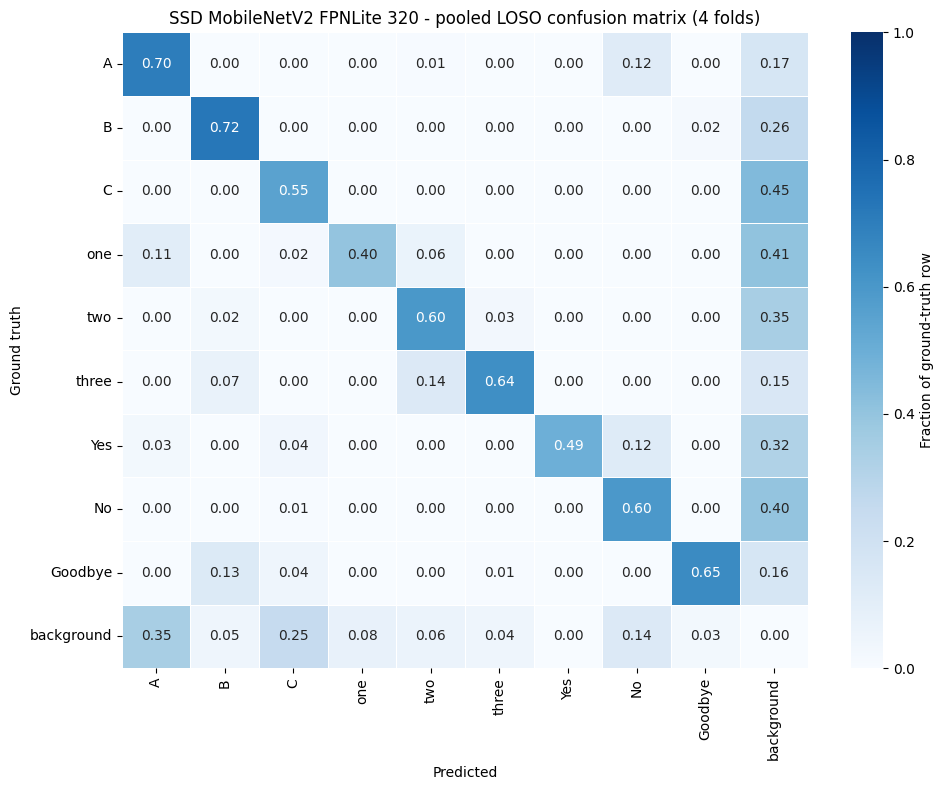


Most frequent confusions (ground truth -> predicted):
       one -> A        21
   Goodbye -> B        21
       Yes -> No       20
     three -> two      19
         A -> No       19
       one -> two      12
     three -> B        10
   Goodbye -> C        7
Error counts: confusion=158, false_positive=335, missed=421
Saved to d:\RealTimeObjectDetection\runs\loso\ssd

LOSO results - CBAM-SSD (proposed) (SSD frozen + 20000 fine-tuning steps, batch 4, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.803           0.767           0.726           0.721           0.726           118.0            45.1            22.2
fold2  subject_02     222           0.431           0.722         

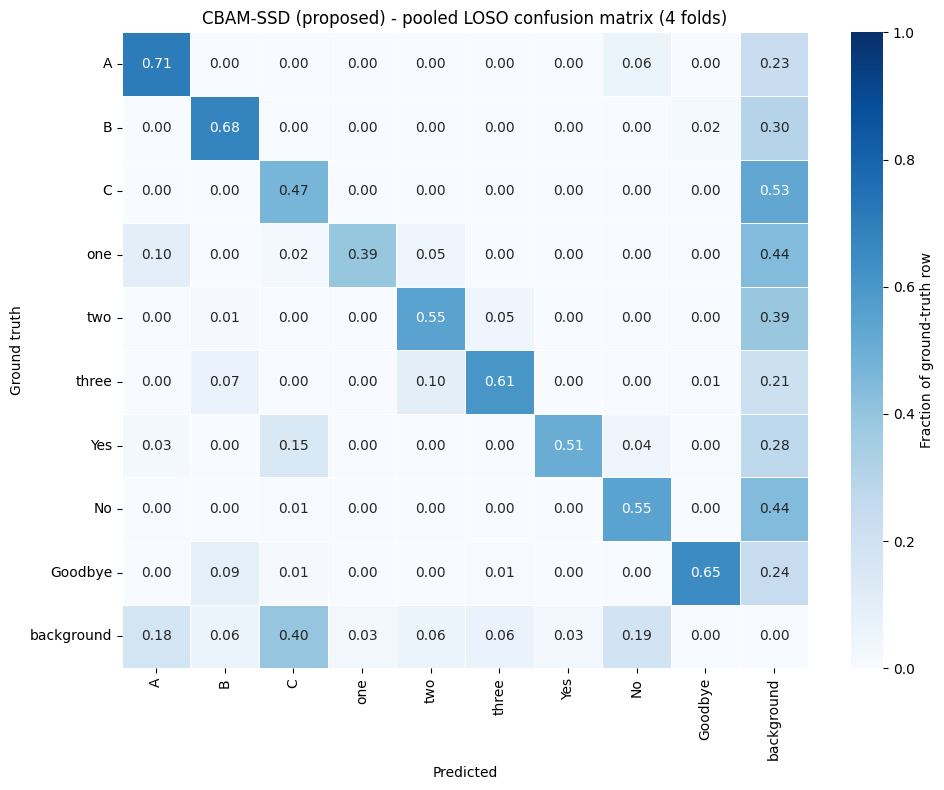


Most frequent confusions (ground truth -> predicted):
       Yes -> C        24
       one -> A        19
   Goodbye -> B        15
     three -> two      14
     three -> B        10
       one -> two      9
         A -> No       9
       two -> three    8
Error counts: confusion=133, false_positive=144, missed=482
Saved to d:\RealTimeObjectDetection\runs\loso\cbam_ssd

LOSO results - SP-FPN-SAM-SSD (proposed) (SSD frozen + 20000 fine-tuning steps, batch 4, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.810           0.749           0.763           0.715           0.723           214.0          3454.2             0.3
fold2  subject_02     222           0.419           0.630

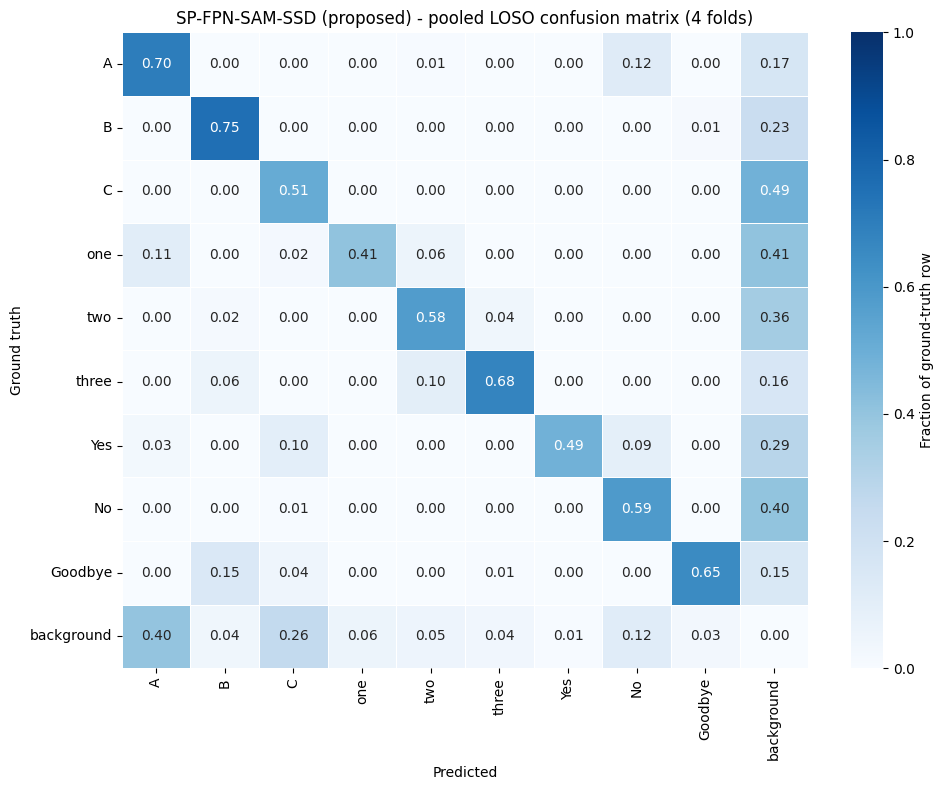


Most frequent confusions (ground truth -> predicted):
   Goodbye -> B        23
       one -> A        21
         A -> No       19
       Yes -> C        16
       Yes -> No       15
     three -> two      14
       one -> two      11
     three -> B        8
Error counts: confusion=157, false_positive=325, missed=420
Saved to d:\RealTimeObjectDetection\runs\loso\sp_fpn_sam_ssd

LOSO results - YOLOv5s 416 (50 epochs, batch 16, 416px, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.965           0.928           0.961           0.937           0.937            38.0            16.4            60.9
fold2  subject_02     222           0.691           0.742           0.586         

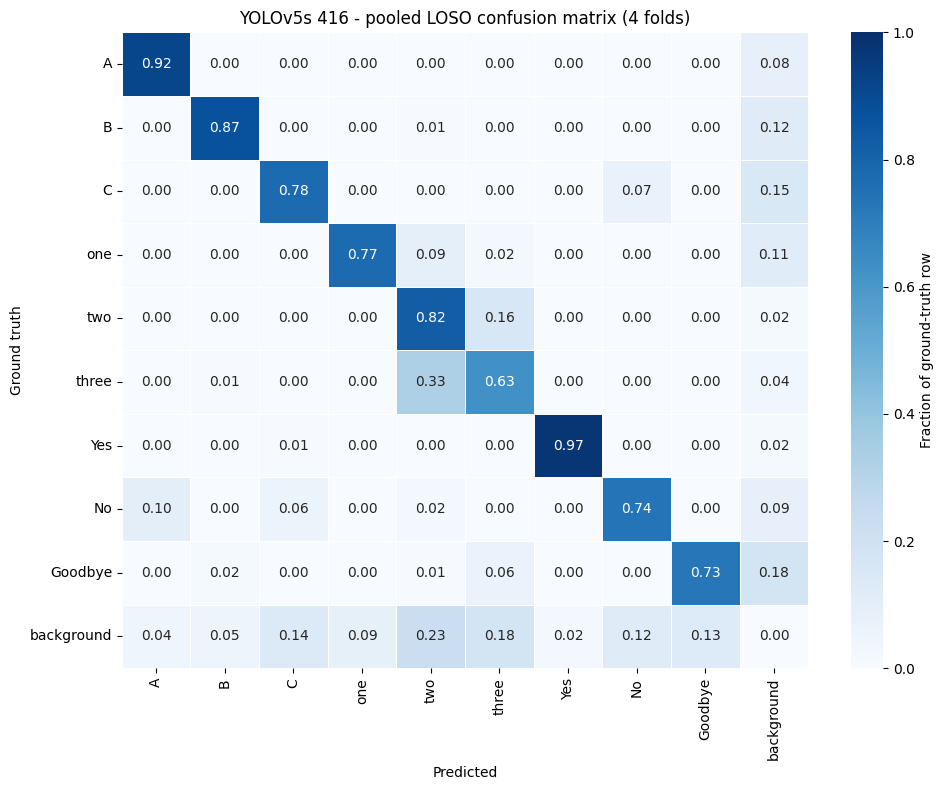


Most frequent confusions (ground truth -> predicted):
     three -> two      45
       two -> three    26
       one -> two      18
        No -> A        16
   Goodbye -> three    10
        No -> C        9
         C -> No       9
        No -> two      4
Error counts: confusion=148, false_positive=93, missed=127
Saved to d:\RealTimeObjectDetection\runs\loso\yolov5s

LOSO results - CBAM-YOLOv5s (proposed) (50 epochs, batch 16, 416px, CBAM added, trained end to end like YOLOv5s, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.934           0.934           0.894           0.861           0.881            50.0            23.7            42.2
fold2  subject_02     222          

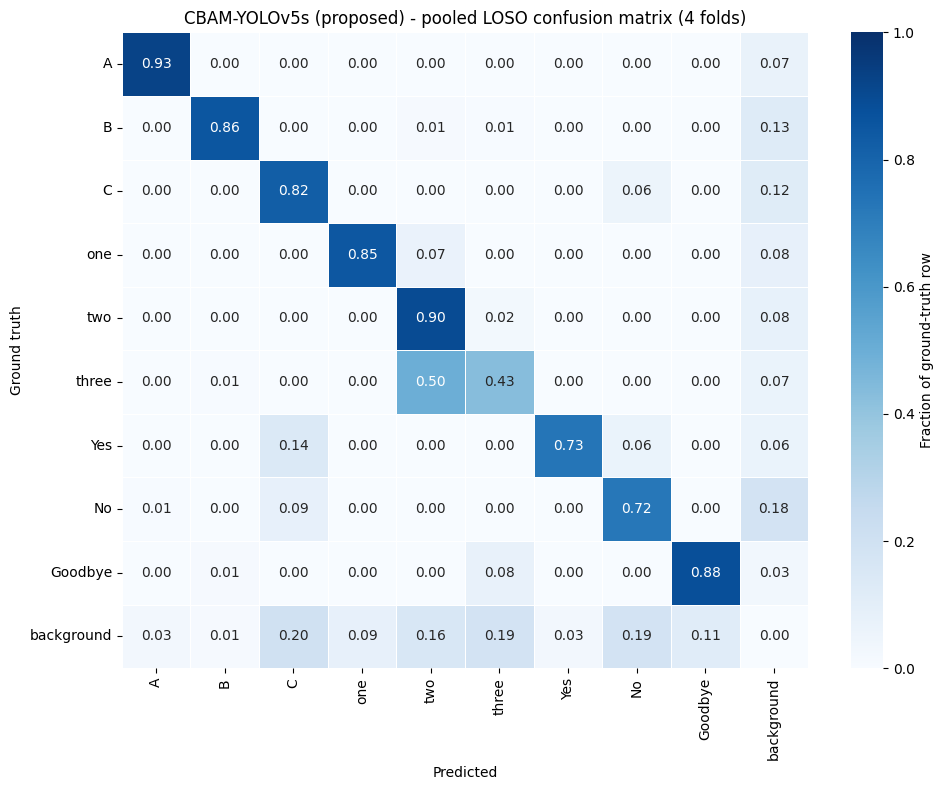


Most frequent confusions (ground truth -> predicted):
     three -> two      68
       Yes -> C        23
        No -> C        14
       one -> two      13
   Goodbye -> three    12
       Yes -> No       10
         C -> No       7
       two -> three    4
Error counts: confusion=158, false_positive=70, missed=129
Saved to d:\RealTimeObjectDetection\runs\loso\cbam_yolov5s

LOSO results - Faster R-CNN ResNet50 V1 640 (20000 steps, batch 2, NMS: per_class)
Fold   Test subject  Imgs         mAP@0.5       Precision          Recall         F1 @0.5         Best F1 False positives  Inference (ms)             FPS
---------------------------------------------------------------------------------------------------------------------------------------------------------
fold1  subject_01     407           0.979           0.852           0.910           0.856           0.859            95.0           162.3             6.2
fold2  subject_02     222           0.808           0.864           0.716  

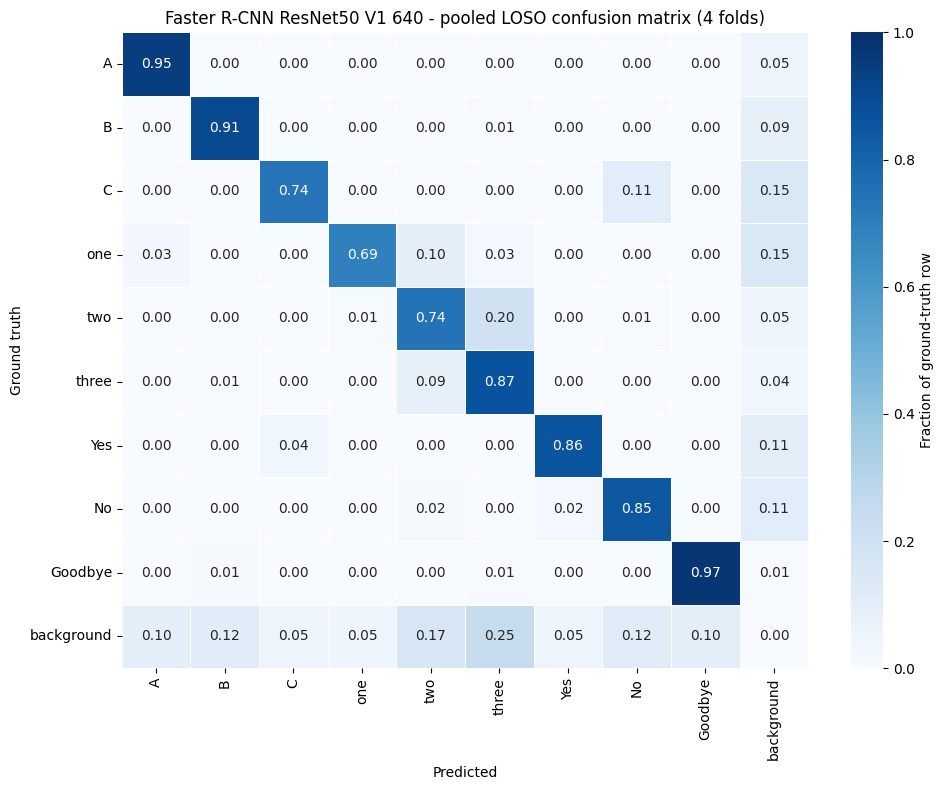


Most frequent confusions (ground truth -> predicted):
       two -> three    33
       one -> two      19
         C -> No       14
     three -> two      12
       one -> A        6
       Yes -> C        6
       one -> three    5
        No -> Yes      4
Error counts: confusion=109, false_positive=233, missed=119
Saved to d:\RealTimeObjectDetection\runs\loso\faster_rcnn


In [11]:
import csv
import matplotlib.pyplot as plt
import seaborn as sns

metric_keys = [('mAP', 'mAP@0.5', 3), ('precision', 'Precision', 3), ('recall', 'Recall', 3),
               ('f1', 'F1 @0.5', 3), ('best_f1', 'Best F1', 3), ('total_fp', 'False positives', 1),
               ('inference_ms_mean', 'Inference (ms)', 1), ('fps', 'FPS', 1)]

def mean_std(vals):
    vals = np.array([v for v in vals if v is not None and not np.isnan(v)], dtype=float)
    return float(vals.mean()), (float(vals.std(ddof=1)) if len(vals) > 1 else 0.0)

def load_results(model):
    out = []
    for fold in all_folds:
        pth = os.path.join(results_dir(model), f'{fold}_metrics.json')
        if os.path.exists(pth):
            with open(pth) as f:
                out.append(json.load(f))
    return out

def summarise_model(model):
    rdir, label = results_dir(model), model_label(model)
    fold_results = load_results(model)
    if len(fold_results) < 2:
        print(f'{label}: fewer than 2 evaluated folds - skipping'); return None

    # Per-fold table
    hdr = f"{'Fold':<7}{'Test subject':<13}{'Imgs':>5}" + ''.join(f'{lbl:>16}' for _, lbl, _ in metric_keys)
    lines = [f'LOSO results - {label} ({training_desc(model)}, NMS: {NMS_MODE})', hdr, '-' * len(hdr)]
    for r in fold_results:
        lines.append(f"{r['fold']:<7}{r['test_subject']:<13}{r['n_test_images']:>5}" +
                     ''.join(f"{r[k]:>16.{d}f}" for k, _, d in metric_keys))
    summary = {k: mean_std([r[k] for r in fold_results]) for k, _, _ in metric_keys}
    lines.append('-' * len(hdr))
    lines.append(f"{'Mean ± std':<25}" + ''.join(f"{summary[k][0]:>9.{d}f}±{summary[k][1]:<6.{d}f}"
                                                for k, _, d in metric_keys))
    print('\n'.join(lines))

    # Per-class AP
    per_class = {}
    print('\n' + f"{'Class':<10}" + ''.join(f"{r['fold']:>8}" for r in fold_results) + f"{'Mean ± std':>18}")
    for c in class_names:
        vals = [r['per_class'][c]['ap'] for r in fold_results]
        per_class[c] = mean_std(vals)
        print(f'{c:<10}' + ''.join(f'{v:>8.3f}' if v == v else f"{'n/a':>8}" for v in vals)
              + f'{per_class[c][0]:>11.3f} ± {per_class[c][1]:.3f}')

    with open(os.path.join(rdir, 'loso_per_fold.csv'), 'w', newline='', encoding='utf-8') as f:
        w = csv.writer(f)
        w.writerow(['fold', 'test_subject', 'n_test_images'] + [k for k, _, _ in metric_keys])
        for r in fold_results:
            w.writerow([r['fold'], r['test_subject'], r['n_test_images']] + [round(r[k], 4) for k, _, _ in metric_keys])
    with open(os.path.join(rdir, 'loso_summary.md'), 'w', encoding='utf-8') as f:
        f.write(f'### {label} - leave-one-subject-out ({len(fold_results)} folds, NMS: {NMS_MODE})\n\n| Metric | Mean ± std |\n|---|---|\n')
        for k, lbl, d in metric_keys:
            f.write(f'| {lbl} | {summary[k][0]:.{d}f} ± {summary[k][1]:.{d}f} |\n')
        f.write('\n| Class | AP@0.5 mean ± std |\n|---|---|\n')
        for c in class_names:
            f.write(f'| {c} | {per_class[c][0]:.3f} ± {per_class[c][1]:.3f} |\n')
    with open(os.path.join(rdir, 'loso_summary.json'), 'w', encoding='utf-8') as f:
        json.dump({'model': label, 'folds': len(fold_results), 'summary': summary,
                   'per_class_ap': per_class}, f, indent=1)

    # Pooled confusion matrix
    cm = np.sum([np.array(r['confusion_matrix']) for r in fold_results], axis=0)
    names = class_names + ['background']
    row = cm.sum(axis=1, keepdims=True)
    norm = np.divide(cm, row, out=np.zeros_like(cm, dtype=float), where=row > 0)
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=names,
                yticklabels=names, linewidths=0.5, ax=ax, cbar_kws={'label': 'Fraction of ground-truth row'})
    ax.set_xlabel('Predicted'); ax.set_ylabel('Ground truth')
    ax.set_title(f'{label} - pooled LOSO confusion matrix ({len(fold_results)} folds)')
    plt.tight_layout()
    plt.savefig(os.path.join(rdir, 'loso_confusion_matrix.png'), dpi=200, bbox_inches='tight')
    plt.show()

    # Misclassification list
    errors = [{'fold': r['fold'], 'test_subject': r['test_subject'], **e} for r in fold_results for e in r['errors']]
    with open(os.path.join(rdir, 'loso_errors.csv'), 'w', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=['fold', 'test_subject', 'image', 'type', 'ground_truth', 'predicted', 'score'])
        w.writeheader(); w.writerows(errors)
    pairs = defaultdict(int)
    for e in errors:
        if e['type'] == 'confusion':
            pairs[(e['ground_truth'], e['predicted'])] += 1
    print('\nMost frequent confusions (ground truth -> predicted):')
    for (g_, p_), n_ in sorted(pairs.items(), key=lambda x: -x[1])[:8]:
        print(f'  {g_:>8} -> {p_:<8} {n_}')
    print('Error counts: ' + ', '.join(f"{t}={sum(e['type'] == t for e in errors)}"
                                     for t in ('confusion', 'false_positive', 'missed')))
    print(f'Saved to {rdir}')
    return summary

summaries = {}
for model in MODELS_TO_RUN:
    print('\n' + '=' * 100)
    summaries[model] = summarise_model(model)

## 6. Model Comparison

Mean ± std per model, mAP for every held-out subject, and the component timings of SP-FPN-SAM-SSD (reviewer comment #3). The per-fold table is what the statistical test for comment #5 will use.

In [12]:
done = [m for m in MODELS_TO_RUN if summaries.get(m)]
if not done:
    raise RuntimeError('No model has results yet')

lines = [f"{'Metric':<18}" + ''.join(f"{model_label(m)[:30]:>32}" for m in done)]
lines.append('-' * len(lines[0]))
for k, lbl, d in metric_keys:
    lines.append(f'{lbl:<18}' + ''.join(f"{summaries[m][k][0]:>23.{d}f} ± {summaries[m][k][1]:<6.{d}f}" for m in done))
print('\n'.join(lines))

per_fold = {m: {r['fold']: r for r in load_results(m)} for m in done}
print('\nmAP@0.5 per held-out subject:')
print(f"{'Fold':<7}{'Test subject':<14}" + ''.join(f'{m:>16}' for m in done))
for fold in all_folds:
    if all(fold in per_fold[m] for m in done):
        subj = per_fold[done[0]][fold]['test_subject']
        print(f'{fold:<7}{subj:<14}' + ''.join(f"{per_fold[m][fold]['mAP']:>16.3f}" for m in done))

with open(os.path.join(RESULTS_ROOT, 'model_comparison.md'), 'w', encoding='utf-8') as f:
    f.write('| Metric | ' + ' | '.join(model_label(m) for m in done) + ' |\n')
    f.write('|---|' + '---|' * len(done) + '\n')
    for k, lbl, d in metric_keys:
        f.write(f'| {lbl} | ' + ' | '.join(f"{summaries[m][k][0]:.{d}f} ± {summaries[m][k][1]:.{d}f}" for m in done) + ' |\n')
with open(os.path.join(RESULTS_ROOT, 'model_comparison_per_fold.csv'), 'w', newline='', encoding='utf-8') as f:
    w = csv.writer(f)
    w.writerow(['fold', 'test_subject'] + [f'{m}_mAP' for m in done])
    for fold in all_folds:
        if all(fold in per_fold[m] for m in done):
            w.writerow([fold, per_fold[done[0]][fold]['test_subject']] + [round(per_fold[m][fold]['mAP'], 4) for m in done])
print(f'\nSaved: model_comparison.md, model_comparison_per_fold.csv in {RESULTS_ROOT}')

# --- SP-FPN-SAM-SSD: where the time goes (reviewer comment #3) ---
sp_models = [m for m in done if MODELS[m]['kind'] == 'spfpn']
for m in sp_models:
    rows = [r for r in load_results(m) if 'components_ms' in r]
    if not rows:
        continue
    keys = [('slic_ms', 'SLIC superpixels (CPU)'), ('detector_ms', 'SSD + fusion layers (GPU)'),
            ('objectness_ms', 'Objectness map (SAM or edge)'), ('refine_ms', 'Score re-scoring')]
    print(f"\n{model_label(m)} - mean time per image across {len(rows)} folds")
    total = 0.0
    tab = ['| Component | ms (mean ± std over folds) |', '|---|---|']
    for k, lbl in keys:
        mu, sd = mean_std([r['components_ms'][k] for r in rows])
        total += mu
        print(f'  {lbl:<32}{mu:>9.1f} ± {sd:.1f}')
        tab.append(f'| {lbl} | {mu:.1f} ± {sd:.1f} |')
    print(f"  {'Total':<32}{total:>9.1f}  ({1000/total:.1f} FPS)")
    tab.append(f'| **Total** | **{total:.1f}** ({1000/total:.1f} FPS) |')
    print('  gamma per fold:', [r.get('gamma') for r in rows])
    with open(os.path.join(RESULTS_ROOT, f'{m}_component_times.md'), 'w', encoding='utf-8') as f:
        f.write('\n'.join(tab) + '\n')

# --- Added parameters of the proposed models ---
for m in done:
    p_ = [r.get('new_params') for r in load_results(m) if r.get('new_params')]
    if p_:
        base = 'the YOLOv5s model (trained end to end)' if MODELS[m]['kind'] == 'yolo' else 'the frozen SSD'
        print(f'{model_label(m)}: {p_[0]:,} trainable parameters added to {base}')

Metric                 SSD MobileNetV2 FPNLite 320             CBAM-SSD (proposed)       SP-FPN-SAM-SSD (proposed)                     YOLOv5s 416         CBAM-YOLOv5s (proposed)    Faster R-CNN ResNet50 V1 640
------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
mAP@0.5                             0.672 ± 0.239                   0.708 ± 0.217                   0.683 ± 0.228                   0.861 ± 0.119                   0.875 ± 0.047                   0.923 ± 0.087 
Precision                           0.704 ± 0.121                   0.767 ± 0.053                   0.709 ± 0.103                   0.855 ± 0.080                   0.874 ± 0.073                   0.851 ± 0.031 
Recall                              0.588 ± 0.259                   0.547 ± 0.265                   0.587 ± 0.249                   0.809 ± 0.162           

## 6b. Is the Difference Real? Paired Bootstrap Tests (reviewer comment #5)

With only 4 held-out subjects, a test across folds cannot reach p < 0.05, so models are compared **image by image**. All models were tested on the same images, so each fold's test images are resampled with replacement 2,000 times (the same resample for every model), every metric is recomputed with the same evaluation code, and the difference in the LOSO mean is recorded. The 2.5th-97.5th percentiles of those differences give a 95% confidence interval; if it does not include 0, the difference is unlikely to be chance (p < 0.05).

The first line checks that the fast recomputation reproduces the evaluation above exactly. Takes a few minutes. Results: `runs/loso/significance.md` and `significance.csv`.

In [13]:
# ---- Paired bootstrap: is each difference larger than chance? (reviewer comment #5) ----
import csv
# Every model was tested on the same images, so models are compared image by image: the test images of each fold
# are resampled with replacement (the SAME resample for every model), every metric is recomputed with the
# evaluation code above, and the difference in the LOSO mean (mean over the 4 folds) is recorded each time.
PAIRS = [('cbam_ssd', 'ssd'),                 # proposed vs its own baseline
         ('cbam_yolov5s', 'yolov5s'),         # proposed vs its own baseline
         ('sp_fpn_sam_ssd', 'ssd'),           # ablation
         ('cbam_yolov5s', 'cbam_ssd'),
         ('cbam_yolov5s', 'faster_rcnn'),
         ('yolov5s', 'cbam_ssd')]
N_BOOT = 2000
BOOT_SEED = 0
_T = np.linspace(0, 1, 101)

def _boot_prepare(model, fold):
    """Detections of one model on one fold, matched once (matching only depends on the image itself)."""
    test_dir = fold_paths(fold, model)['test_dir']
    names = list_images(test_dir)
    index = {n: i for i, n in enumerate(names)}
    gts = ground_truths_for(test_dir)
    with open(os.path.join(results_dir(model), 'dumps', f'{fold}.json'), encoding='utf-8') as f:
        dets = json.load(f)['detections']
    per_class = {}
    for c in class_names:
        cls_dets = sorted([d for d in dets if d['class_name'] == c], key=lambda d: -d['score'])  # same order as match_class
        flags, _ = match_class(dets, gts, c)
        gt_count = np.bincount([index[g['image']] for g in gts if g['class_name'] == c], minlength=len(names))
        per_class[c] = (np.array([index[d['image']] for d in cls_dets], dtype=int).reshape(-1),
                        np.asarray(flags, dtype=float).reshape(-1),
                        np.array([d['score'] for d in cls_dets], dtype=float).reshape(-1),
                        gt_count.astype(float))
    return names, per_class

def _boot_ap(img, tp, gtc, w):
    n_gt = float(gtc @ w)
    if n_gt == 0:
        return np.nan                                   # class absent from this resample
    t = np.repeat(tp, w[img]) if len(tp) else tp
    if len(t) == 0:
        return 0.0
    tpc, fpc = np.cumsum(t), np.cumsum(1 - t)
    mrec = np.concatenate(([0.0], tpc / n_gt, [1.0]))
    mpre = np.concatenate(([1.0], tpc / (tpc + fpc), [0.0]))
    env = np.maximum.accumulate(mpre[::-1])[::-1]       # precision envelope, as in compute_ap
    return float(env[np.searchsorted(mrec, _T, side='left')].sum() / 101)

def _boot_metrics(per_class, w):
    """mAP, precision, recall (macro over classes present) and false positives at CONF_THRESH for weights w."""
    aps, ps, rs, fp = [], [], [], 0.0
    for c in class_names:
        img, tp, score, gtc = per_class[c]
        ap = _boot_ap(img, tp, gtc, w)
        keep = score >= CONF_THRESH
        wk = w[img[keep]]
        n_det, n_tp = float(wk.sum()), float((wk * tp[keep]).sum())
        fp += n_det - n_tp
        if np.isnan(ap):
            continue
        n_gt = float(gtc @ w)
        aps.append(ap); ps.append(n_tp / n_det if n_det else 0.0); rs.append(n_tp / n_gt)
    return np.mean(aps), np.mean(ps), np.mean(rs), fp

def _fmt_p(p):
    return '< 0.001' if p < 0.001 else f'{p:.3f}'

boot_models = sorted({m for pair in PAIRS for m in pair if m in MODELS},
                     key=lambda m: list(MODELS).index(m))
boot_models = [m for m in boot_models
               if all(os.path.exists(os.path.join(results_dir(m), 'dumps', f'{f}.json')) for f in folds)]
pairs = [(a, b) for a, b in PAIRS if a in boot_models and b in boot_models]
if not pairs:
    print('No pair has saved detections for every fold yet - run Phase B first.')
else:
    METRICS = ['mAP@0.5', 'Precision', 'Recall', 'False positives']
    prepared = {m: {f: _boot_prepare(m, f) for f in folds} for m in boot_models}
    # 1) Check: with every image counted once, the fast code must reproduce the evaluation exactly
    worst = 0.0
    for m in boot_models:
        for f in folds:
            names, pc = prepared[m][f]
            got = _boot_metrics(pc, np.ones(len(names), dtype=int))
            with open(os.path.join(results_dir(m), f'{f}_metrics.json'), encoding='utf-8') as fh:
                ref = json.load(fh)
            want = (ref['mAP'], ref['precision'], ref['recall'], ref['total_fp'])
            worst = max(worst, max(abs(g - r) for g, r in zip(got, want)))
    print(f'Check against the evaluation: largest difference {worst:.2e} '
          + ('(OK)' if worst < 1e-6 else '(!!! does not match - do not use these p-values; tell Claude)'))

    # 2) One set of resampled test sets, shared by every model (this is what makes the comparison paired)
    rng = np.random.default_rng(BOOT_SEED)
    n_img = {f: len(prepared[boot_models[0]][f][0]) for f in folds}
    weights = [{f: np.bincount(rng.integers(0, n_img[f], n_img[f]), minlength=n_img[f]) for f in folds}
               for _ in range(N_BOOT)]
    t0 = time.time()
    point, boot = {}, {}
    for m in boot_models:
        point[m] = np.array([_boot_metrics(prepared[m][f][1], np.ones(n_img[f], dtype=int)) for f in folds])  # folds x 4
        boot[m] = np.array([[_boot_metrics(prepared[m][f][1], w[f]) for f in folds] for w in weights])        # B x folds x 4
        print(f'  bootstrap {model_label(m)}: done ({time.time() - t0:.0f} s)', flush=True)

    # 3) Differences in the LOSO mean (mean over folds)
    rows = []
    md_lines = [f'Paired bootstrap over test images ({N_BOOT} resamples, seed {BOOT_SEED}). Difference = A - B in the '
                f'mean over the {len(folds)} held-out subjects. 95% CI = 2.5th-97.5th percentile. p = two-sided bootstrap p-value.', '',
                '| A | B | Metric | A | B | Difference | 95% CI | p | A better on |', '|---|---|---|---|---|---|---|---|---|']
    for a, b in pairs:
        print(f'\n{model_label(a)}  vs  {model_label(b)}')
        print(f"  {'Metric':<17}{'A':>9}{'B':>9}{'A - B':>9}   {'95% CI':<19}{'p':>8}   A better on")
        for k, name in enumerate(METRICS):
            pa, pb = point[a][:, k], point[b][:, k]
            diff = pa.mean() - pb.mean()
            d = boot[a][:, :, k].mean(1) - boot[b][:, :, k].mean(1)
            lo, hi = np.percentile(d, [2.5, 97.5])
            p = min(1.0, 2 * (min((d <= 0).sum(), (d >= 0).sum()) + 1) / (N_BOOT + 1))
            better = int((pa < pb).sum()) if name == 'False positives' else int((pa > pb).sum())
            dec = 1 if name == 'False positives' else 3
            ci = f'[{lo:+.{dec}f}, {hi:+.{dec}f}]'
            print(f'  {name:<17}{pa.mean():>9.{dec}f}{pb.mean():>9.{dec}f}{diff:>+9.{dec}f}   {ci:<19}'
                  f'{_fmt_p(p):>8}   {better}/{len(folds)} subjects')
            rows.append({'A': a, 'B': b, 'metric': name, 'A_value': pa.mean(), 'B_value': pb.mean(), 'difference': diff,
                         'ci_low': lo, 'ci_high': hi, 'p': p, 'A_better_folds': better, 'n_folds': len(folds)})
            md_lines.append(f'| {model_label(a)} | {model_label(b)} | {name} | {pa.mean():.{dec}f} | {pb.mean():.{dec}f} | '
                            f'{diff:+.{dec}f} | [{lo:+.{dec}f}, {hi:+.{dec}f}] | {_fmt_p(p)} | {better}/{len(folds)} |')
    with open(os.path.join(RESULTS_ROOT, 'significance.csv'), 'w', newline='', encoding='utf-8') as f:
        cw = csv.DictWriter(f, fieldnames=list(rows[0]))
        cw.writeheader(); cw.writerows(rows)
    with open(os.path.join(RESULTS_ROOT, 'significance.md'), 'w', encoding='utf-8') as f:
        f.write('\n'.join(md_lines) + '\n')
    print(f'\nSaved: significance.md, significance.csv in {RESULTS_ROOT}')
    print('Read it as: the difference is unlikely to be chance if the 95% CI does not include 0 (p < 0.05). '
          'False positives: lower is better, so a negative difference favours A.')


Check against the evaluation: largest difference 4.44e-16 (OK)
  bootstrap SSD MobileNetV2 FPNLite 320: done (23 s)
  bootstrap CBAM-SSD (proposed): done (40 s)
  bootstrap SP-FPN-SAM-SSD (proposed): done (59 s)
  bootstrap YOLOv5s 416: done (66 s)
  bootstrap CBAM-YOLOv5s (proposed): done (74 s)
  bootstrap Faster R-CNN ResNet50 V1 640: done (80 s)

CBAM-SSD (proposed)  vs  SSD MobileNetV2 FPNLite 320
  Metric                   A        B    A - B   95% CI                    p   A better on
  mAP@0.5              0.708    0.672   +0.036   [+0.027, +0.043]    < 0.001   3/4 subjects
  Precision            0.767    0.704   +0.063   [+0.021, +0.080]    < 0.001   3/4 subjects
  Recall               0.547    0.588   -0.041   [-0.055, -0.027]    < 0.001   0/4 subjects
  False positives       65.8    115.0    -49.2   [-56.2, -41.8]      < 0.001   4/4 subjects

CBAM-YOLOv5s (proposed)  vs  YOLOv5s 416
  Metric                   A        B    A - B   95% CI                    p   A better on
  

## 7. Diagnostics: False Positives and Annotation Style

Splits each held-out subject's false positives by cause and compares annotated box sizes between subjects.

In [14]:
# ---- Diagnostic: why so many false positives and misses? ----
import csv, os, re
import xml.etree.ElementTree as ET
from collections import defaultdict, Counter
import numpy as np

MODEL_TO_CHECK = MODELS_TO_RUN[0]
rows = list(csv.DictReader(open(os.path.join(results_dir(MODEL_TO_CHECK), 'loso_errors.csv'), encoding='utf-8', errors='replace')))

by_img = defaultdict(list)
for r in rows:
    by_img[(r['test_subject'], r['image'])].append(r)

# 1. Classify every false positive
kinds = defaultdict(Counter)
for (subj, img), errs in by_img.items():
    missed = Counter(e['ground_truth'] for e in errs if e['type'] == 'missed')
    for e in errs:
        if e['type'] != 'false_positive':
            continue
        if missed[e['predicted']] > 0:
            kinds[subj]['box in wrong place (right class, IoU < 0.5)'] += 1
        elif missed:
            kinds[subj]['wrong class on a missed hand'] += 1
        else:
            kinds[subj]['extra box (hand already detected, or background)'] += 1

print('FALSE POSITIVES BY CAUSE')
for subj in sorted(kinds):
    total = sum(kinds[subj].values())
    print(f'\n{subj}: {total} false positives')
    for k, n in kinds[subj].most_common():
        print(f'   {n:>4}  ({n/total:4.0%})  {k}')

# 2. Annotation style per subject: box size relative to the image
print('\n\nANNOTATED BOX SIZE PER SUBJECT (fraction of image)')
print(f"{'Subject':<12}{'Images':>8}{'Box width':>12}{'Box height':>12}{'Box area':>10}{'Boxes/img':>11}")
stats = defaultdict(lambda: {'w': [], 'h': [], 'a': [], 'n': []})
for f in os.listdir(ALL_DATA):
    if not f.endswith('.xml'):
        continue
    m = SUBJECT_RE.search(f)
    if not m:
        continue
    root = ET.parse(os.path.join(ALL_DATA, f)).getroot()
    W, H = int(root.find('size/width').text), int(root.find('size/height').text)
    objs = root.findall('object')
    stats[m.group(1)]['n'].append(len(objs))
    for o in objs:
        b = o.find('bndbox')
        w = (float(b.find('xmax').text) - float(b.find('xmin').text)) / W
        h = (float(b.find('ymax').text) - float(b.find('ymin').text)) / H
        stats[m.group(1)]['w'].append(w); stats[m.group(1)]['h'].append(h); stats[m.group(1)]['a'].append(w * h)
for subj in sorted(stats):
    s = stats[subj]
    print(f"{subj:<12}{len(s['n']):>8}{np.mean(s['w']):>12.2f}{np.mean(s['h']):>12.2f}"
          f"{np.mean(s['a']):>10.3f}{np.mean(s['n']):>11.2f}")


FALSE POSITIVES BY CAUSE

subject_01: 168 false positives
    144  ( 86%)  extra box (hand already detected, or background)
     23  ( 14%)  wrong class on a missed hand
      1  (  1%)  box in wrong place (right class, IoU < 0.5)

subject_02: 18 false positives
     10  ( 56%)  wrong class on a missed hand
      8  ( 44%)  extra box (hand already detected, or background)

subject_04: 71 false positives
     57  ( 80%)  extra box (hand already detected, or background)
     14  ( 20%)  wrong class on a missed hand

subject_05: 78 false positives
     31  ( 40%)  wrong class on a missed hand
     25  ( 32%)  extra box (hand already detected, or background)
     22  ( 28%)  box in wrong place (right class, IoU < 0.5)


ANNOTATED BOX SIZE PER SUBJECT (fraction of image)
Subject       Images   Box width  Box height  Box area  Boxes/img
subject_01       407        0.31        0.51     0.158       1.00
subject_02       223        0.21        0.37     0.080       1.00
subject_04       389     

## 8. Edge Deployment Benchmark (reviewer comment #4)

The real-time detectors (**SSD, CBAM-SSD, YOLOv5s, CBAM-YOLOv5s**) are deployed to the Jetson as **TensorRT FP16** engines, the standard optimised runtime on NVIDIA Jetson boards.

1. **8a (this PC):** export every trained model and fold to ONNX, then check the ONNX model against the original TensorFlow/PyTorch model on a few test images (raw outputs and final detections).
2. **8b (this PC):** build `edge_bundle.zip` (models, held-out test images, benchmark script), then run the whole held-out evaluation once with ONNX Runtime on this PC. Its mAP must equal the Phase B mAP; that proves the export and the pre/post-processing are exact.
3. **On the Jetson:** unzip, run `python3 edge_benchmark.py` (see `README_JETSON.md` inside the zip). It builds the TensorRT engines and measures accuracy on the device, latency (pre-processing / inference / post-processing), FPS, memory and board power (from the Jetson's own power sensors via `tegrastats`), plus energy per frame.

**Not deployed:** Faster R-CNN (two-stage; it already runs at only 6 FPS on the GTX 1060, and the TF two-stage graph does not convert to TensorRT without major rework) and SP-FPN-SAM-SSD (its SAM step takes 3.4 s per image on the GTX 1060). State both in the paper as not suitable for edge deployment, with these numbers as the reason.

**One-time setup on this PC** (Anaconda Prompt):
```
"C:\Users\Jason\.conda\envs\yolov5\python.exe" -m pip install onnx

conda create -n edge python=3.10 -y
conda activate edge
python -m pip install "tensorflow==2.15.1" "tf2onnx==1.16.1" "onnx==1.16.2" "onnxruntime==1.18.1" "opencv-python-headless==4.10.0.84" "numpy<2"
```
The separate `edge` environment keeps your `tfod` training environment untouched (installing ONNX tools there could break its protobuf version).


In [15]:
# ---- 8a. Export the real-time models to ONNX and check them against the original model ----
EDGE_MODELS = ['ssd', 'cbam_ssd', 'yolov5s', 'cbam_yolov5s']
EDGE_FOLDS  = folds
EDGE_PYTHON = None   # None = the conda environment called 'edge'; or the full path to its python.exe
EDGE_PYTHON = EDGE_PYTHON if (EDGE_PYTHON and os.path.exists(EDGE_PYTHON)) else find_python('edge')
EDGE_EXPORT = os.path.join(RUNS_ROOT, 'edge_export')
EDGE_BUNDLE = os.path.join(BASE_PATH, 'edge_bundle')

def python_ready(py, modules, label, how):
    if not (py and os.path.exists(py)):
        print(f'!!! {label}: Python environment not found.\n{how}'); return False
    r = subprocess.run([py, '-c', 'import ' + ', '.join(modules)], capture_output=True, text=True, env=torch_env())
    if r.returncode != 0:
        print(f'!!! {label}: packages missing in {py}:\n    {(r.stderr.strip().splitlines() or ["?"])[-1]}\n{how}'); return False
    return True

EDGE_HOW = ('    Create it once in Anaconda Prompt:\n      conda create -n edge python=3.10 -y\n      conda activate edge\n'
            '      python -m pip install "tensorflow==2.15.1" "tf2onnx==1.16.1" "onnx==1.16.2" "onnxruntime==1.18.1" '
            '"opencv-python-headless==4.10.0.84" "numpy<2"')

def export_edge(model, fold):
    """Export one trained model/fold to ONNX and check it. Returns the check result."""
    p = fold_paths(fold, model)
    kind = MODELS[model]['kind']
    out = os.path.join(EDGE_EXPORT, model, fold)
    val = os.path.join(out, 'validation.json')
    if os.path.exists(val):
        with open(val, encoding='utf-8') as f:
            v = json.load(f)
        if v.get('ok'):
            return v
    os.makedirs(out, exist_ok=True)
    if kind in ('tfod', 'cbam'):
        ssd_dir = p['model_dir'] if kind == 'tfod' else fold_paths(fold, 'ssd')['model_dir']
        cmd = [sys.executable, script('edge_export_tf.py'), '--kind', kind, '--model_dir', ssd_dir,
               '--test_dir', p['test_dir'], '--out_dir', out]
        if kind == 'cbam':
            cmd += ['--extra_dir', p['work']]
        env = tf_env()
    elif kind == 'yolo':
        cmd = [YOLO_PYTHON, script('edge_export_yolo.py'), '--repo', YOLO_REPO, '--weights', p['yolo_weights'],
               '--test_dir', p['test_dir'], '--out_dir', out, '--img', YOLO_IMG]
        env = torch_env()
    else:
        raise RuntimeError(f'{model} is not exported for the edge benchmark')
    log = os.path.join(out, 'export.log')
    if run_logged(cmd, log, env=env) != 0 or not os.path.exists(os.path.join(out, 'meta.json')):
        raise RuntimeError(f'export failed (log: {log}):\n{tail(log, 15)}')
    log2 = os.path.join(out, 'onnx.log')
    run_logged([EDGE_PYTHON, script('edge_to_onnx.py'), '--dir', out], log2, env=torch_env())
    if not os.path.exists(val):
        raise RuntimeError(f'ONNX conversion/check failed (log: {log2}):\n{tail(log2, 15)}')
    with open(val, encoding='utf-8') as f:
        return json.load(f)

ready = python_ready(EDGE_PYTHON, ['tensorflow', 'tf2onnx', 'onnx', 'onnxruntime', 'cv2'], "'edge' environment", EDGE_HOW)
if any(MODELS[m]['kind'] == 'yolo' for m in EDGE_MODELS):
    ready &= python_ready(YOLO_PYTHON, ['onnx', 'torch'], 'YOLOv5 environment',
                         f'    In Anaconda Prompt:  "{YOLO_PYTHON}" -m pip install onnx')
if ready:
    print(f"{'Model':<15}{'Fold':<7}{'ONNX MB':>9}{'max output diff':>17}{'detections matched':>20}")
    for model in EDGE_MODELS:
        for fold in EDGE_FOLDS:
            if not os.path.exists(fold_paths(fold, model)['done']):
                print(f'{model:<15}{fold:<7}  not trained - skipped'); continue
            try:
                v = export_edge(model, fold)
            except RuntimeError as e:
                print(f'{model:<15}{fold:<7}  !!! {e}'); continue
            flag = '' if v['ok'] else '   !!! MISMATCH - tell Claude'
            print(f"{model:<15}{fold:<7}{v['onnx_mb']:>9.1f}{v['max_relative_output_difference']:>17.1e}"
                  f"{v['detections_matched']:>12}/{v['detections_compared']:<4} ({100*v['match_rate']:.0f}%){flag}")


Model          Fold     ONNX MB  max output diff  detections matched
ssd            fold1       10.4          1.5e-06         100/100  (100%)
ssd            fold2       10.4          1.1e-06         100/100  (100%)
ssd            fold3       10.4          2.6e-06         100/100  (100%)
ssd            fold4       10.4          1.2e-06         100/100  (100%)
cbam_ssd       fold1       10.5          1.2e-06         100/100  (100%)
cbam_ssd       fold2       10.5          7.3e-07         100/100  (100%)
cbam_ssd       fold3       10.5          1.6e-06         100/100  (100%)
cbam_ssd       fold4       10.5          8.6e-07         100/100  (100%)
yolov5s        fold1       28.3          2.0e-06           8/8    (100%)
yolov5s        fold2       28.3          9.7e-07          33/33   (100%)
yolov5s        fold3       28.3          2.1e-06          12/12   (100%)
yolov5s        fold4       28.3          1.3e-06          27/27   (100%)
cbam_yolov5s   fold1       28.5          1.3e-06       

In [16]:
# ---- 8b. Build the Jetson bundle and run the full held-out evaluation once on this PC (ONNX Runtime) ----
import zipfile
REDO_PC_CHECK = False      # True = run the PC check again even if it finished before

def build_bundle():
    jobs = []
    for model in EDGE_MODELS:
        for fold in EDGE_FOLDS:
            src = os.path.join(EDGE_EXPORT, model, fold)
            vj = os.path.join(src, 'validation.json')
            if not os.path.exists(vj):
                continue
            with open(vj, encoding='utf-8') as f:
                if not json.load(f).get('ok'):
                    continue
            dst = os.path.join(EDGE_BUNDLE, 'models', model, fold)
            os.makedirs(dst, exist_ok=True)
            for name in ('model.onnx', 'meta.json', 'anchors.npy'):
                if os.path.exists(os.path.join(src, name)):
                    shutil.copy2(os.path.join(src, name), dst)
            with open(os.path.join(results_dir(model), f'{fold}_metrics.json'), encoding='utf-8') as f:
                m = json.load(f)
            desktop = {k: m[k] for k in ('mAP', 'precision', 'recall', 'f1', 'total_fp')}
            desktop['inference_ms_desktop_gpu'] = m.get('inference_ms_mean')
            with open(os.path.join(dst, 'desktop.json'), 'w', encoding='utf-8') as f:
                json.dump(desktop, f, indent=1)
            jobs.append((model, fold))
    for fold in sorted({f for _, f in jobs}):
        dst = os.path.join(EDGE_BUNDLE, 'data', fold, 'test')
        if not os.path.isdir(dst):
            shutil.copytree(fold_paths(fold, 'ssd')['test_dir'], dst)
    for name in ('edge_benchmark.py', 'edge_common.py', 'loso_common.py', 'loso_config.json', 'README_JETSON.md'):
        shutil.copy2(os.path.join(SCRIPTS_DIR, name), EDGE_BUNDLE)
    return jobs

jobs = build_bundle()
print(f'Bundle: {len(jobs)} model/fold pairs in {EDGE_BUNDLE}')
if jobs:
    pc_dir = os.path.join(EDGE_BUNDLE, 'results_pc')
    if REDO_PC_CHECK and os.path.isdir(pc_dir):
        shutil.rmtree(pc_dir)
    print('PC check with ONNX Runtime (CPU): every held-out image of every fold - a few minutes...', flush=True)
    log = os.path.join(EDGE_EXPORT, 'pc_check.log')
    run_logged([EDGE_PYTHON, os.path.join(EDGE_BUNDLE, 'edge_benchmark.py'), '--backend', 'onnxruntime',
                '--accuracy_only'], log, env=torch_env())
    print(f"\n{'Model':<15}{'Fold':<7}{'mAP ONNX':>10}{'mAP Phase B':>13}{'difference':>12}")
    worst = 0.0
    for model, fold in jobs:
        rp = os.path.join(pc_dir, 'rows', f'{model}_{fold}.json')
        if not os.path.exists(rp):
            print(f'{model:<15}{fold:<7}  !!! no result (log: {log})'); continue
        with open(rp, encoding='utf-8') as f:
            r = json.load(f)
        a, d = r['accuracy']['mAP'], r['desktop']['mAP']
        worst = max(worst, abs(a - d))
        print(f'{model:<15}{fold:<7}{a:>10.4f}{d:>13.4f}{a - d:>+12.4f}')
    print(f'\nLargest difference: {worst:.4f} ' + ('(OK - the exported models reproduce Phase B)' if worst < 0.005
                                                  else '(!!! larger than expected - tell Claude)'))

    zip_path = os.path.join(BASE_PATH, 'edge_bundle.zip')
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
        for root, dirs, files in os.walk(EDGE_BUNDLE):
            dirs[:] = [d for d in dirs if d not in ('results', 'results_pc')]
            for name in files:
                if not name.endswith(('.engine', '.log')):
                    full = os.path.join(root, name)
                    z.write(full, os.path.relpath(full, EDGE_BUNDLE))
    print(f'\nCopy this to the Jetson: {zip_path} ({os.path.getsize(zip_path) / 1e6:.0f} MB) - instructions in README_JETSON.md inside.')


Bundle: 16 model/fold pairs in d:\RealTimeObjectDetection\edge_bundle
PC check with ONNX Runtime (CPU): every held-out image of every fold - a few minutes...

Model          Fold     mAP ONNX  mAP Phase B  difference
ssd            fold1      0.8048       0.8048     +0.0000
ssd            fold2      0.4009       0.4009     +0.0000
ssd            fold3      0.9283       0.9283     +0.0000
ssd            fold4      0.5539       0.5539     +0.0000
cbam_ssd       fold1      0.8030       0.8030     +0.0000
cbam_ssd       fold2      0.4310       0.4310     +0.0000
cbam_ssd       fold3      0.9382       0.9382     +0.0000
cbam_ssd       fold4      0.6585       0.6585     +0.0000
yolov5s        fold1      0.9653       0.9653     +0.0000
yolov5s        fold2      0.6908       0.6908     +0.0000
yolov5s        fold3      0.9140       0.9140     +0.0000
yolov5s        fold4      0.8723       0.8723     +0.0000
cbam_yolov5s   fold1      0.9340       0.9340     +0.0000
cbam_yolov5s   fold2      0.8

## Next

- **Class-agnostic NMS** (one label per hand): set `NMS_MODE = 'class_agnostic'` and run all. Nothing retrains; every model is re-evaluated into `runs/loso_class_agnostic/` (run 6b again there).
- **Edge benchmark (reviewer comment #4):** after section 8, run `python3 edge_benchmark.py` on the Jetson and bring back `results/edge_results.md`.
- **Code repository (reviewer comment #3):** `loso_runs/scripts` plus this notebook contain everything needed to reproduce the results.